# 02 System model: Forch mobility hub 

This is our group's copy of the course notebook `02_system_modeling.ipynb`. **Part 1 (Sections 1.1 to 1.7) has been adapted to our case**: the mobility hub at Bahnhof Forch (Küsnacht and Maur, Forchbahn S18), measure GV6 of the 5th-generation Agglomerationsprogramm Stadt Zürich-Glattal.

**What the case is about.** Forch is a station on the Forchbahn (S18) between Zürich Stadelhofen and Esslingen. The hub would let people from Maur, Egg, Zumikon and the Pfannenstiel area reach the S18 by bike, bus or car and change there. The model represents the weekday evening peak (17:00-18:00). 

**How to read this notebook.** Grey boxes are code. Run them from top to bottom (menu *Run > Run All Cells*). Every table is also saved as a CSV in `deliverables/phase2/s1/tables/` and every figure as a PNG in `deliverables/phase2/s1/figures/`.


Task types, as in the course sheet: **tutorial** (to understand), **mandatory** (needed for the report), **advanced** (optional extensions).

## Setup

This cell loads the Python libraries and our project files. Two things differ from the course version:

1. `tools/` is added to the import path. It holds `forch_s1.py` (helpers that turn dashboard results into saved tables and figures) and `offline_osm.py` so that everyone has their own map.
2. The course's automatic exports go to `deliverables/phase2/s1/nb02_exports/` instead of `figures/` and `results/`, so all our outputs sit in one folder.

Use Python 3.11 with the packages in `requirements.txt`. After changing `parameters.py` or any other `.py` file: restart the kernel and run everything again.

In [3]:
print("Ça fonctionne")

Ça fonctionne


In [4]:
import sys
import os
import time
from pathlib import Path

from IPython.display import HTML, display

# Install dependencies only when preparing the environment.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INSTALL_REQUIREMENTS = False
if INSTALL_REQUIREMENTS:
    %pip install --quiet -r "$PROJECT_ROOT/requirements.txt"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lonboard
from joblib import Parallel, delayed

# 1. Set up project directories
CODE_DIR = PROJECT_ROOT / "code"
TOOLS_DIR = PROJECT_ROOT / "tools"
for folder in (CODE_DIR, TOOLS_DIR):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

# 2. Import project modules
import parameters as p
import stages as stages_module
import simulation_engine as m
import transport_model_interface as tmi
import adaptive_planning
from additional import uncertainty as uc
from additional import notebook_exports as exports
from parameters import N_YEARS, DISCOUNT_RATE

# Notebook configuration
SAVE_OUTPUTS = True
# Our exports live in deliverables/phase2/s1/ (figures/nb02_exports and results/nb02_exports).
S1_DIR = PROJECT_ROOT / "deliverables" / "phase2" / "s1"
exports.configure(S1_DIR, "nb02_exports", enabled=SAVE_OUTPUTS)
# skip Part 1 course exports, already saved as tables/s1_*
SKIP_EXPORTS = ("1_",)
exports._orig_save = getattr(exports, "_orig_save", exports.save_outputs)
exports.save_outputs = lambda name, **kw: {} if name.startswith(SKIP_EXPORTS) else exports._orig_save(name, **kw)
_NB_START = time.perf_counter()
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)


# The corridor builder repeats one connectivity warning per corridor; show it once.
import warnings
warnings.filterwarnings("once", message=".*cordon: excluded.*")

# Forch helpers: plain tables and figures instead of click-only dashboards.
import forch_s1 as f1
import offline_osm

# Part 1: How the system model works

## 1.1 What are we modelling? (tutorial)

**System boundary.** The model covers the Canton of Zürich, divided into **1,223 zones** from the Swiss national passenger model (NPVM). A zone is a small area, like a neighbourhood or a village; all its trips start and end at one point, the zone centroid. The model describes **one ordinary weekday evening hour, 17:00-18:00**. For Forch we look at a smaller area inside the canton, the *corridor* (Section 1.3), but trips from the rest of the canton still enter and leave it.

**Four steps, two of which we run.** A classic four-step model has:

| Step | Question | In this course |
|---|---|---|
| 1. Trip generation | How many trips start and end in each zone? | Fixed: taken from the NPVM origin-destination (OD) matrix |
| 2. Trip distribution | Who travels from which zone to which zone? | Fixed: the same NPVM OD matrix |
| 3. Mode choice | Which of five options does each traveller take? | **Run**: multinomial logit with car, PT with walk access, PT with bike access, bike, walk |
| 4. Assignment | Which roads do the cars use, and how slow do they get? | **Run**: all-or-nothing routes averaged by MSA, BPR congestion function |

Steps 3 and 4 are **coupled**: congestion from step 4 makes car trips slower, which changes the choices in step 3, which changes the number of cars in step 4. The loop repeats until the road flows stop changing (road relative gap at most 2 %, at least 8 and at most 64 iterations). The diagram below shows the loop.

**Limitations to keep in mind** (details in `deliverables/phase2/s1/S1_report_full.md`):
- total demand per OD pair is fixed; a better hub does not create new trips, it only moves trips between modes;
- there is no park-and-ride option in the mode choice, so "drive to Forch, then S18" cannot be chosen as one trip;
- only the evening peak hour is modelled; at Forch that hour is mostly people coming home, so the hub's *egress* role dominates;
- congestion is computed only on the local road network inside the cordon; background traffic (freight and other vehicles) is fixed;
- PT is not assigned to lines: PT times come from fixed skims, so a full Forchbahn does not slow down.

Sources: Sheet 2 §1.1 (Assignments/IP-HS2026-Project 3-4-f.pdf, p. 5); course notebook cell 3; `data/transport/config/mode_choice.json`; `code/transport_model_interface.py` (`ASSIGNMENT_SETTINGS`).

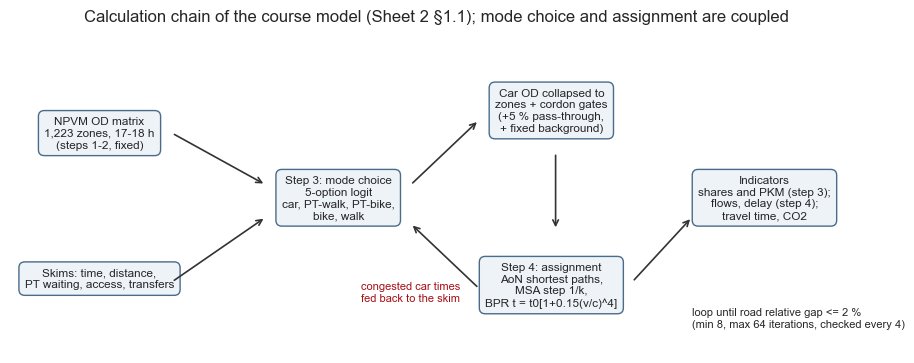

In [5]:
# Draw the calculation loop of the model once and save it for the report.
fig = f1.plot_model_loop()
f1.save_figure(fig, "s1_1_model_loop")
plt.show()

## 1.2 Input data and simulation setup (tutorial)

The preflight checks that every prepared input file exists and loads. "Ready" for every row means the model has its zones, OD demand, travel-time and distance skims, road network and mode-choice parameters. The table is saved as `tables/s1_2_preflight.csv`.

In [6]:
# 1. Check data readiness
transport_status = tmi.transport_input_status(PROJECT_ROOT)
TRANSPORT_FLAGS = tmi.readiness_flags(transport_status)

exports.save_outputs("1_2_transport_readiness", tables={"": transport_status})
f1.save_table(transport_status, "s1_2_preflight")
display(transport_status)
display(HTML(tmi.readiness_message(transport_status)))

# 2. Load the transport context
ctx = None
TRANSPORT_LOAD_ERROR = None

if TRANSPORT_FLAGS["mode_choice"]:
    try:
        ctx = tmi.load_transport_context(PROJECT_ROOT, allow_missing_detailed_network=True)
    except Exception as error:
        TRANSPORT_LOAD_ERROR = f"{type(error).__name__}: {error}"
        display(HTML(
            "<div style='padding:10px;border-left:5px solid #b71c1c;background:#ffebee'>"
            "<b>The files exist, but the transport model could not load them:</b><br>"
            f"<code>{TRANSPORT_LOAD_ERROR}</code>"
            "</div>"
        ))
else:
    display(HTML(
        "<div style='padding:10px;border-left:5px solid #c47f00;background:#fff8e1'>"
        "<b>Cannot load model:</b> Required input files are missing from <code>data/transport/prepared/</code>."
        "</div>"
    ))

,item,required,present,relative_path,purpose
0,Zones,True,True,data/transport/prepared/zones.parquet,Spatial zones & attributes
1,Passenger & Background Demand,True,True,data/transport/prepared/demand.pkl.gz,OD matrices
2,Multimodal Skims,True,True,data/transport/prepared/skims.pkl.gz,Travel times & distances
3,Intervention Lookups,True,True,data/transport/prepared/lookups.pkl.gz,Municipality and stop selectors
4,Road Network,True,True,data/transport/prepared/assignment_network.pkl,Road links and nodes
5,Mode-choice Parameters,True,True,data/transport/config/mode_choice.json,Logit coefficients


[OK] Automatically loaded detailed corridor network from forch_vb_detailed_network.pkl


## 1.3 Corridor and road network (tutorial + mandatory)

The map below shows the roads that cars can use in the whole canton, before any traffic is put on them. The background map also draws footpaths and closed roads, so some gaps in the coloured network are on purpose.

Pick a link property from the dropdown to colour the map:

- free-flow time: minutes to drive the link on an empty road;
- directional capacity: how many vehicles per hour the link can carry in one direction (a property of the road, not the traffic on it);
- lanes, speed and road class: what the road is like.

Nothing has been routed yet: there is no traffic, no congestion and no BPR time on this map.

In [7]:
FULL_NETWORK_MAP = None
FULL_NETWORK_MAP_ERROR = None

if ctx is not None:
    try:
        FULL_NETWORK_MAP = tmi.full_network_explorer(ctx)

        if FULL_NETWORK_MAP is not None:
            display(FULL_NETWORK_MAP)
        else:
            display(HTML(
                "<div style='padding:10px;border-left:5px solid #c47f00;"
                "background:#fff8e1'>"
                "<b>Full-network map unavailable.</b><br>"
                "The transport context was loaded, but the map function "
                "did not return a visualization."
                "</div>"
            ))

    except Exception as error:
        FULL_NETWORK_MAP_ERROR = f"{type(error).__name__}: {error}"

        display(HTML(
            "<div style='padding:10px;border-left:5px solid #b71c1c;"
            "background:#ffebee'>"
            "<b>The transport context loaded successfully, but the "
            "full-network map could not be created.</b><br>"
            f"<code>{FULL_NETWORK_MAP_ERROR}</code><br><br>"
            "Check that the geospatial and visualization dependencies "
            "(including <code>geopandas</code>, <code>lonboard</code>, and "
            "<code>ipywidgets</code>) are installed in the active notebook kernel."
            "</div>"
        ))

else:
    reason = (
        TRANSPORT_LOAD_ERROR
        if TRANSPORT_LOAD_ERROR is not None
        else "The transport context is not available."
    )

    display(HTML(
        "<div style='padding:10px;border-left:5px solid #c47f00;"
        "background:#fff8e1'>"
        "<b>Full-network map skipped.</b><br>"
        "Complete the transport-model preflight and resolve the loading "
        "problem before running this cell.<br>"
        f"<code>{reason}</code>"
        "</div>"
    ))

### Our corridor: the Forchbahn catchment plus the Glattal link (decisions D1 and V1)

Simulating every road in the canton would be slow, so the course cuts the network down to a **cordon** around the study area. The MehrSpur example did this with whole municipalities. For Forch, whole municipalities would be a poor fit: Küsnacht, for example, is mostly a lake-shore town served by the S6/S16, not by the Forchbahn. We therefore define the corridor **zone by zone** (`CORRIDOR_DEFINITION_MODE = "zones"` in `code/parameters.py`):

1. the city zones along the S18 from Stadelhofen to Rehalp and Witikon (the course's own `Zurich_S18_Alignment` list);
2. every zone of Zollikon, Zumikon, Küsnacht, Maur and Egg whose centroid is closer (straight line) to a Forchbahn stop than to any other rail station;
3. every zone whose centroid lies within 1.5 km of Forch station, the catchment used in the 2025 preliminary appraisal.

Stations come from the 2026 GTFS timetable in `data/transport/raw/gtfs`; the Forchbahn is identified by its agency name in the data. The script `tools/build_forch_corridor.py` does all of this and writes the reason for every zone to `tables/corridor_zones_D1.csv`. This first corridor, **D1**, has 93 zones.

In the v2 check (10 October 2026) five corridor variants were compared on one table (`tables/s1_v2_corridor_comparison.csv`, made by `tools/v2_variants.py`). D1 cut the northern city at Milchbuck, so traffic from the whole Glattal and Winterthur sector entered on residential streets and jammed there, far from Forch. The adopted corridor, **V-b**, is D1 plus every zone of Fällanden and Dübendorf (the bus 702 link to the Glattal): its cordon reaches the A1/A53 motorways, the jam on residential streets almost disappears, and it is the smallest variant that passes the four tests of decision V1 (`S1_decisions.md`). V-b has **125 zones**, grouped into the reporting regions used throughout: Zürich centre, Zürich east, Zollikerberg, Zumikon, Forch hub area, rest of Maur, rest of Egg, rest of Küsnacht, and Fällanden and Dübendorf.

The model then draws a 500 m buffer around these zones. Trips with at least one end inside the buffered cordon are reported, so the reporting scope is somewhat larger than the 125 configured zones.

Demand from outside the cordon enters through **gates**: points where roads cross the cordon line. The categories are: internal → internal, gate → internal (inbound), internal → gate (outbound), gate → gate (pass-through, an assumed 5 % share).

### Why the detailed roads come from a frozen file (decision D2)

The course code downloads detailed OpenStreetMap roads from the Overpass service the first time it builds a corridor. Overpass is slow and sometimes unreachable, and four people downloading on different days would get slightly different roads. So Omar downloaded one extract on 9 October 2026 (`data/transport/raw/osm/forch_2026-10-09_drive.pkl.gz`, made with `tools/fetch_forch_osm.py`). The next cell tells the course code to cut its roads from that file instead of downloading. Nothing else in the course code changes. The result is cached as `data/processed/forch_vb_detailed_network.pkl`, so after the first run this step only reads the cache.

In [8]:
# Serve osmnx.graph_from_polygon from the 2026-10-09 extract.
offline_osm.install()
print("Detailed network file:", p.DETAILED_NETWORK_FILE)

[offline_osm] osmnx.graph_from_polygon now reads forch_2026-10-09_drive.pkl.gz
Detailed network file: data/processed/forch_vb_detailed_network.pkl


Enhancing network for Forch...
[OK] Reusing detailed corridor network from forch_vb_detailed_network.pkl


/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/code/transport_model_interface.py:1764: UserWarning: Forch cordon: excluded 3 disconnected boundary candidates and 10 unreachable entry/exit directions. Retained 126 additional existing links to connect internal zone anchors. See corridor.metadata for the affected node and zone IDs.
  return build_corridor_context(context, name=project_name, **kwargs)


Reporting scope: 177 zones in the buffered corridor.
  • Calculating the Stage 0 (Stage 0 – Baseline Network) baseline modal split with the reference travel time skims...

Stage 0 baseline modal split calculated.


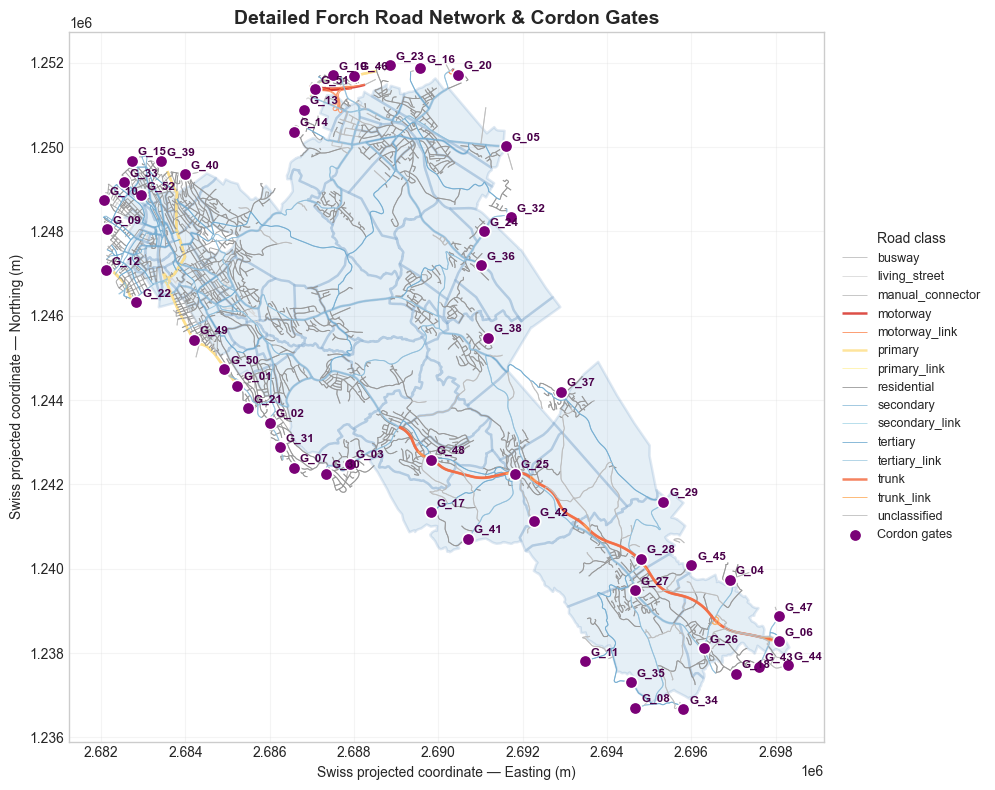

In [9]:
# 1. Enhance the baseline network with OpenStreetMap roads
project_name = "Forch"
corridor_municipalities = p.CORRIDOR_MUNICIPALITIES
cache_file = tmi.configured_detailed_network_path(PROJECT_ROOT, must_exist=False)
if cache_file is None:
    cache_file = PROJECT_ROOT / "data" / "processed" / f"{project_name.lower()}_detailed_network.pkl"

if ctx is None:
    raise RuntimeError(
        "The transport context is not available. "
        "Complete the transport-model preflight before running this cell."
    )

print(f"Enhancing network for {project_name}...")

# Use the cached detailed network when available.
# set the flag below to True only to download and rebuild the detailed roads.
tmi.ASSIGNMENT_SETTINGS["force_regenerate_corridor_network"] = False

ctx = tmi.load_detailed_corridor_network(
    ctx,
    corridor_municipalities=corridor_municipalities,
    cache_path=cache_file,
    allow_download=True,
)

# build the corridor context used by maps, gates, and diagnostic tables.
FORCH = tmi.build_corridor(
    ctx,
    project_name,
    corridor_municipalities=corridor_municipalities,
)

# Shared road relative gap settings for all native calculations below.
ASSIGNMENT_OPTIONS = tmi.resolve_assignment_settings()


# 2. Run Baseline Simulation
# for now just consider Stage 0 as the current baseline network with no additional infrastructure or policy interventions. 
# Car traffic assignment is introduced separately below first with fixed demand and then with congestion to mode choice feedback.
stages = stages_module.get_stages(p.NOMINAL_PARAMS)
# FOR later code
MEHRSPUR = FORCH
corridor_zones = list(FORCH.zone_ids)
print(f"Reporting scope: {len(corridor_zones)} zones in the buffered corridor.")


print(
    f"  • Calculating the Stage 0 ({stages[0]['name']}) "
    "baseline modal split with the reference travel time skims..."
)

res_stage0 = tmi.run_transport_mode_choice(
    ctx,
    stage=0,
    stage_specs=stages,
    corridor_zone_ids=corridor_zones,
)
metrics_stage0 = tmi.extract_corridor_metrics(
    ctx, res_stage0, corridor_zone_ids=corridor_zones
)

print("\nStage 0 baseline modal split calculated.")


# 3. Visualize the baseline Cordon Road Network and Gates 
if res_stage0 is not None:
    
    # map, selectable road attributes, gates, network detail, and OD summaries.
    FORCH_DASHBOARD = tmi.corridor_dashboard(
        ctx,
        FORCH,
        demand_matrix=res_stage0.drive_od,
    )
    display(FORCH_DASHBOARD)

    # Stage 0 network plot.
    tmi.static_network_plot(
        context=ctx,
        mode_result=res_stage0,
        corridor_municipalities=corridor_municipalities,
        project_name=project_name,
    )
else:
    display(HTML(
        "<div style='padding:10px;border-left:5px solid #c47f00;"
        "background:#fff8e1'>"
        "<b>Baseline visualization skipped.</b><br>"
        "The Stage 0 simulation did not return a result."
        "</div>"
    ))

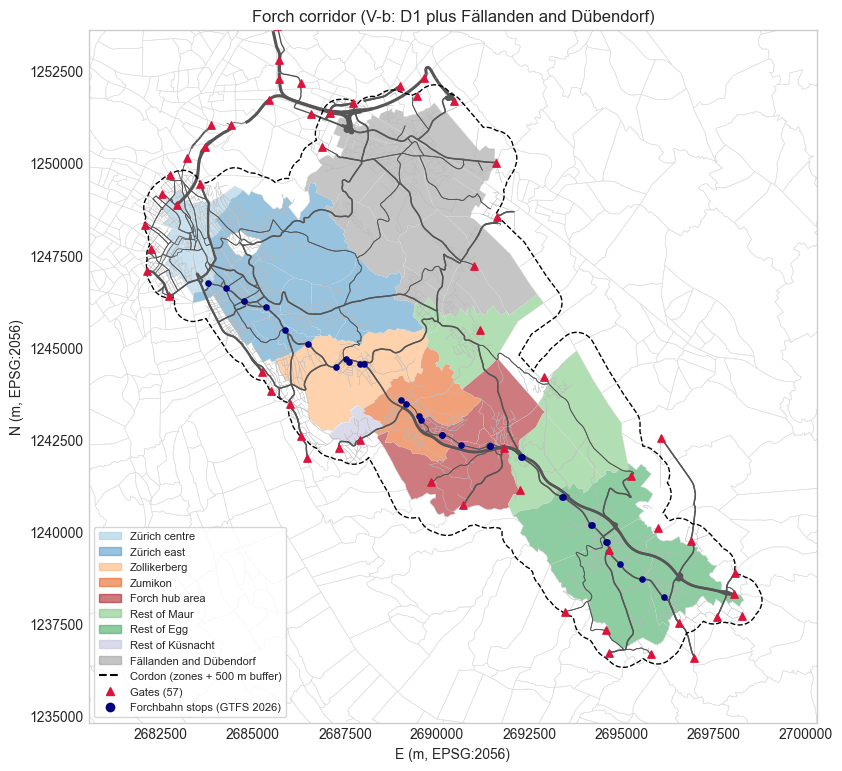

Configured zones: 125; zones inside the buffered cordon: 177


,zones,baseline_population,baseline_jobs
region,,,
Forch hub area,4.0,4990.0,1327.0
Fällanden and Dübendorf,32.0,41980.0,24485.0
Rest of Egg,5.0,8859.0,3063.0
Rest of Küsnacht,1.0,1397.0,369.0
Rest of Maur,5.0,7761.0,1677.0
Zollikerberg,5.0,8859.0,3691.0
Zumikon,3.0,3839.0,1646.0
Zürich centre,37.0,18100.0,104737.0
Zürich east,33.0,47500.0,56488.0


In [10]:
# Static corridor map for the report
STATIONS = pd.read_csv(f1.TAB / "rail_stations_gtfs.csv")
CORRIDOR_TABLE = pd.read_csv(f1.TAB / "corridor_zones_D1.csv", dtype={"grid_id": str})
fig = f1.plot_corridor_map(ctx, FORCH, p.PROJECT_ZONES, STATIONS)
f1.save_figure(fig, "s1_3_corridor_map")
plt.show()

# Corridor size in numbers, from zones.parquet.
# The configured corridor V-b with its reporting regions taken from PROJECT_ZONES in parameters.py.
CONFIGURED = (CORRIDOR_TABLE[CORRIDOR_TABLE["grid_id"].isin(p.CORRIDOR_ZONE_IDS)]
              .assign(region=lambda d: d["grid_id"].map({z: r for r, ids in p.PROJECT_ZONES.items() for z in ids})))
assert len(CONFIGURED) == len(p.CORRIDOR_ZONE_IDS)
CORRIDOR_SUMMARY = (CONFIGURED
                    .groupby("region")[["grid_id", "baseline_population", "baseline_jobs"]]
                    .agg({"grid_id": "count", "baseline_population": "sum", "baseline_jobs": "sum"})
                    .rename(columns={"grid_id": "zones"}))
CORRIDOR_SUMMARY.loc["Total"] = CORRIDOR_SUMMARY.sum()
f1.save_table(CORRIDOR_SUMMARY.reset_index(), "s1_3_corridor_regions")
print(f"Configured zones: {len(p.CORRIDOR_ZONE_IDS)}; zones inside the buffered cordon: {len(FORCH.zone_ids)}")
display(CORRIDOR_SUMMARY)

### Cordon gates (mandatory, decision D3)

Candidate gates are the places where roads cross the cordon line. The course code keeps a limited number of them, using road capacity, a minimum distance between gates and a maximum count; external zones are then attached to their nearest suitable gate. Too few gates squeeze traffic through a handful of points and create artificial jams; too many make the model slower without changing much.

We test the course's five configurations plus two in between. Retained demand alone cannot separate them (internal, inbound and outbound trips are kept by construction), so for each configuration we also run the **coupled Stage-0 assignment** and record the **road delay**, and we check whether every major road crossing (motorway, trunk, primary or secondary) has a gate within 400 m: Forchstrasse at the city edge, the Forchautobahn and Forchstrasse at the east end, links to the lake road, Egg/Esslingen, Maur/Uster and Fällanden/Dübendorf.

**Rule (D3):** choose the smallest configuration that gates every major crossing that can be gated at all (the unrestricted configuration shows which ones; a few crossings have no gate candidate within 400 m, see `tables/s1_3_major_crossings.csv`) and whose Stage-0 road delay is within 5 % of the next larger configuration. The chosen values are written into `DEFAULT_MAX_GATES` and `DEFAULT_GATE_SEPARATION_M` in `code/transport_model_interface.py`, so every later cell uses them.

> This cell runs seven coupled assignments and takes a few minutes.

In [11]:
# Test gate configurations: coverage of major road crossings plus Stage 0 road delay for each.
GATE_CONFIGURATIONS = [(15, 1000.0), (20, 1000.0), (30, 800.0), (40, 500.0), (60, 500.0), (100, 500.0), (10_000, 0.0)]
MAJOR_CROSSINGS = f1.major_boundary_crossings(ctx, FORCH)
ASSIGNMENT_OPTIONS = tmi.resolve_assignment_settings()

GATE_SENSITIVITY, gate_test_contexts, GATE_DISTANCES = f1.run_gate_tests(
    tmi, ctx, res_stage0, GATE_CONFIGURATIONS, MAJOR_CROSSINGS, assignment_options=ASSIGNMENT_OPTIONS)
GATE_SENSITIVITY = f1.choose_gate_configuration(GATE_SENSITIVITY)
CHOSEN_GATES = GATE_SENSITIVITY.loc[GATE_SENSITIVITY["chosen"]].iloc[0]

exports.save_outputs("1_3_gate_sensitivity", tables={"": GATE_SENSITIVITY})
f1.save_table(GATE_SENSITIVITY, "s1_3_gate_sensitivity")
MAJOR_CROSSINGS_TABLE = MAJOR_CROSSINGS.drop(columns="geometry").assign(
    **{f"dist_gate_m_{k[0]}_{int(k[1])}": d.round(0) for k, d in GATE_DISTANCES.items()})
f1.save_table(MAJOR_CROSSINGS_TABLE, "s1_3_major_crossings")
display(GATE_SENSITIVITY.round(3))
print(f"Chosen by D3: max_gates={int(CHOSEN_GATES.max_gates)}, separation={CHOSEN_GATES.separation_m:.0f} m "
      f"({int(CHOSEN_GATES.selected_gates)} gates). In use by FORCH: max_gates={tmi.DEFAULT_MAX_GATES}, "
      f"separation={tmi.DEFAULT_GATE_SEPARATION_M:.0f} m.")

/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/code/transport_model_interface.py:1764: UserWarning: Forch cordon: excluded 3 disconnected boundary candidates and 10 unreachable entry/exit directions. Retained 126 additional existing links to connect internal zone anchors. See corridor.metadata for the affected node and zone IDs.
  return build_corridor_context(context, name=project_name, **kwargs)
/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/code/transport_model_interface.py:1764: UserWarning: Forch cordon: excluded 3 disconnected boundary candidates and 10 unreachable entry/exit directions. Retained 126 additional existing links to connect internal zone anchors. See corridor.metadata for the affected node and zone IDs.
  return build_corridor_context(context, name=project_name, **kwargs)
/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/code/transport_model_interface.py:1764: 

,max_gates,separation_m,candidate_nodes,selected_gates,entry_gates,exit_gates,retained_trips_pct_of_canton,largest_gate_share,major_crossings,major_crossings_gated,...,stage0_delay_outside_city_veh_h,max_vc,stage0_vkt,stage0_avg_speed_kph,final_road_gap,iterations,runtime_s,full_major_coverage,delay_change_to_next_larger,chosen
0,15,1000.0,225,15,11,12,28.051,0.203,27,9,...,4695.073,3.834,475646.161,29.272,0.019,40,32.821,False,0.096,False
1,20,1000.0,225,20,16,17,28.053,0.203,27,13,...,4072.760,3.759,478782.262,30.472,0.020,36,29.852,False,0.017,False
2,30,800.0,225,30,25,26,28.040,0.162,27,17,...,4547.587,3.663,504485.901,31.423,0.020,32,31.553,False,-0.018,False
3,40,500.0,225,40,34,35,28.107,0.124,27,19,...,4408.788,3.413,519105.965,31.855,0.019,32,41.170,False,0.080,False
4,60,500.0,225,57,51,51,27.946,0.125,27,23,...,4360.672,3.268,531181.730,33.202,0.018,28,45.391,True,0.047,True
5,100,500.0,225,57,51,51,27.946,0.125,27,23,...,4360.672,3.268,531181.730,33.202,0.018,28,43.094,True,0.047,False
6,10000,0.0,225,222,170,175,27.918,0.058,27,23,...,4268.744,3.919,514708.191,33.122,0.017,24,92.831,True,NaN,False


Chosen by D3: max_gates=60, separation=500 m (57 gates). In use by FORCH: max_gates=60, separation=500 m.


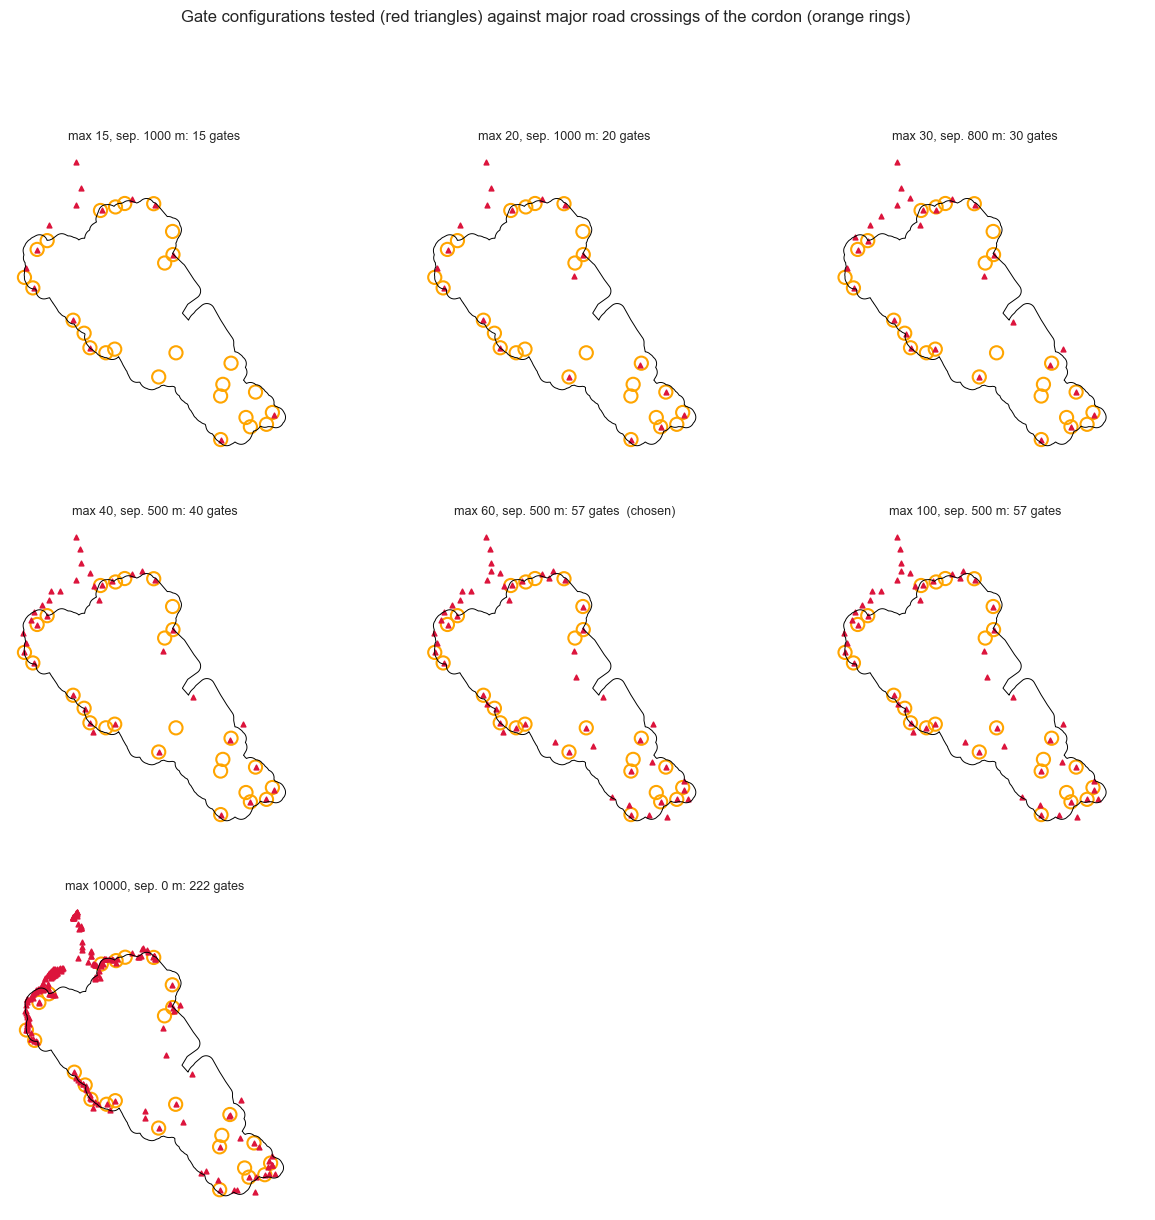

In [12]:
# map of all tested configurations against the major crossings.
fig = f1.plot_gate_configurations(ctx, gate_test_contexts, MAJOR_CROSSINGS,
                                  (int(CHOSEN_GATES.max_gates), float(CHOSEN_GATES.separation_m)))
f1.save_figure(fig, "s1_3_gate_configurations")
plt.show()

The gate settings are in `code/transport_model_interface.py` (`DEFAULT_MAX_GATES` and `DEFAULT_GATE_SEPARATION_M`; we use a maximum of 60 gates at least 500 m apart for the adopted corridor V-b, decisions D3 and V1). If you change them, save the file, restart the kernel and run everything again. The next map shows every point on the cordon that could become a gate.

In [13]:
ALL_GATE_CANDIDATES = gate_test_contexts[(10_000, 0.0)]
display(tmi.corridor_explorer(ALL_GATE_CANDIDATES))

## 1.4 Baseline travel demand and desire lines (tutorial + mandatory)

The OD matrix says how many people travel from each zone to each other zone between 17:00 and 18:00 on a normal weekday, all modes together. Here we look at it at three levels:

1. **municipalities** (the course explorers, now with our municipalities passed explicitly, because in zone mode they cannot guess them);
2. **reporting regions** (decision D7): the nine corridor regions, two "buffer" regions for zones that are inside only because of the 500 m buffer, the rest of Zürich city, and four compass sectors outside, seen from Forch station (north = Glattal, Dübendorf, Winterthur; east = Uster, Oberland; south = Meilen, the lake's right bank; west = the left bank, Limmattal, Sihltal);
3. **demand categories**: internal → internal, inbound, outbound and pass-through.

The validation against independent evidence is in `deliverables/phase2/s1/S1_validation.md`.

In [14]:
# Course explorers at municipality level. In zone mode they need the municipality list passed explicitly.
FORCH_MUNICIPALITIES = ["Zürich", "Zollikon", "Zumikon", "Küsnacht (ZH)", "Maur", "Egg",
                        "Fällanden", "Dübendorf", "Uster", "Meilen", "Erlenbach (ZH)", "Herrliberg",
                        "Oetwil am See", "Mönchaltorf", "Greifensee", "Volketswil"]
FORCH_MUNICIPALITIES = [m for m in FORCH_MUNICIPALITIES if m in set(ctx.zones["municipality_name"])]
MUNICIPALITY_OD, MUNICIPALITY_LINKS = tmi.aggregate_od_by_municipality(ctx, FORCH_MUNICIPALITIES)
f1.save_table(MUNICIPALITY_OD.round(1).reset_index(names="origin"), "s1_4_od_municipalities")
display(MUNICIPALITY_OD.round(0))

MUNICIPALITY_OD_FIGURE = tmi.municipality_od_explorer(ctx, FORCH_MUNICIPALITIES)
display(MUNICIPALITY_OD_FIGURE)

municipality_name,Zürich,Zollikon,Zumikon,Küsnacht (ZH),Maur,Egg,Fällanden,Dübendorf,Uster,Meilen,Erlenbach (ZH),Herrliberg,Oetwil am See,Mönchaltorf,Greifensee,Volketswil
municipality_name,,,,,,,,,,,,,,,,
Zürich,180137.0,1311.0,277.0,978.0,468.0,231.0,459.0,1977.0,884.0,484.0,275.0,246.0,83.0,77.0,142.0,768.0
Zollikon,1308.0,2298.0,91.0,285.0,80.0,25.0,51.0,55.0,26.0,32.0,33.0,21.0,8.0,8.0,6.0,44.0
Zumikon,247.0,85.0,1050.0,148.0,76.0,46.0,19.0,16.0,22.0,25.0,17.0,21.0,10.0,10.0,2.0,14.0
Küsnacht (ZH),970.0,280.0,154.0,3616.0,90.0,47.0,26.0,43.0,38.0,126.0,318.0,101.0,15.0,15.0,4.0,29.0
Maur,455.0,80.0,79.0,94.0,1038.0,50.0,113.0,83.0,73.0,32.0,12.0,22.0,14.0,19.0,8.0,73.0
Egg,222.0,23.0,47.0,46.0,49.0,1168.0,13.0,26.0,168.0,68.0,9.0,15.0,71.0,56.0,8.0,48.0
Fällanden,477.0,56.0,23.0,31.0,117.0,14.0,956.0,154.0,59.0,10.0,4.0,6.0,5.0,6.0,20.0,140.0
Dübendorf,2030.0,41.0,16.0,36.0,80.0,25.0,145.0,6968.0,196.0,18.0,7.0,9.0,9.0,12.0,47.0,468.0
Uster,837.0,33.0,34.0,52.0,69.0,148.0,50.0,177.0,9063.0,54.0,8.0,13.0,67.0,110.0,180.0,735.0


#### Desire-line map (municipalities)

A desire line is a straight line from where trips start to where they end, drawn thicker for more trips. It is not a route: it says nothing about which roads people use.

Use the category and flow-size controls to choose which movements to show. To keep the browser fast, the map draws only the largest flows; the hidden ones are still in the OD matrix and in the model. Each municipality is drawn at the centre of its area.

In [15]:
# Course desire line explorer for the same municipalities (interactive).
MUNICIPALITY_FLOW_MAP = tmi.municipality_flow_map_explorer(
    ctx, FORCH_MUNICIPALITIES, min_trips=1, max_flows=300,
    trip_bin_edges=[1, 10, 25, 50, 100, 250, 500, 1_000, np.inf],
)
display(MUNICIPALITY_FLOW_MAP)

### OD matrix and desire lines by reporting region (mandatory)

Each zone gets one reporting region. The table is the zone OD matrix summed by region (rows = where trips start, columns = where they end). Trips between two outside regions are left out of the figures because they do not touch the corridor. The desire-line maps draw one straight line per pair of regions, thicker for more trips; they show where people want to go, not which roads they use.

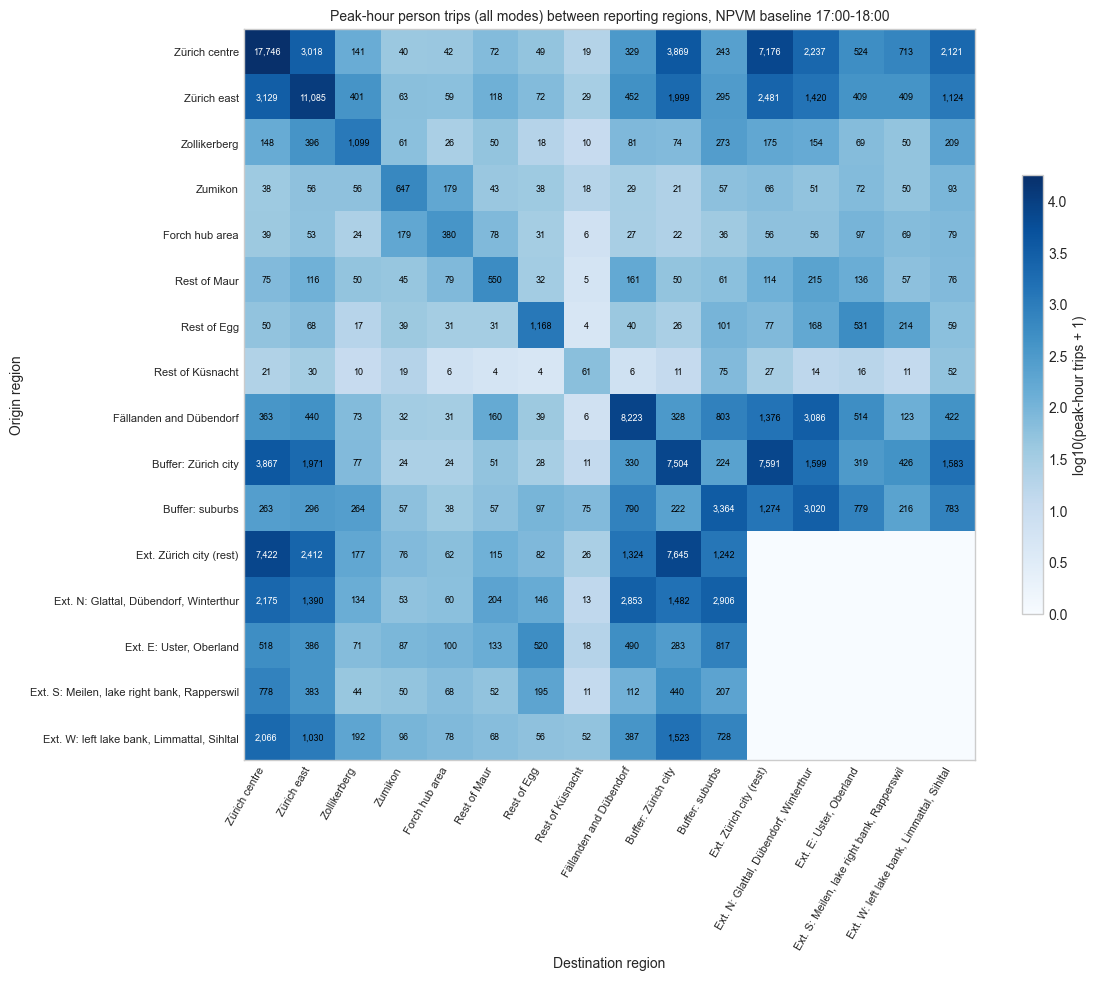

,region,internal_from_region,internal_to_region,outbound_from_region,inbound_to_region,intra_region,total_trip_ends
0,Zürich centre,25569.0,25740.0,12772.0,12959.0,17746.0,59294.0
1,Zürich east,17704.0,17528.0,5843.0,5601.0,11085.0,35590.0
2,Zollikerberg,2236.0,2211.0,656.0,618.0,1099.0,4622.0
3,Zumikon,1181.0,1206.0,332.0,362.0,647.0,2435.0
4,Forch hub area,873.0,896.0,357.0,368.0,380.0,2114.0
5,Rest of Maur,1223.0,1215.0,599.0,572.0,550.0,3058.0
6,Rest of Egg,1574.0,1575.0,1050.0,999.0,1168.0,4031.0
7,Rest of Küsnacht,248.0,243.0,120.0,120.0,61.0,670.0
8,Fällanden and Dübendorf,10498.0,10467.0,5521.0,5167.0,8223.0,23431.0
9,Buffer: Zürich city,14111.0,14126.0,11519.0,11373.0,7504.0,43625.0


In [16]:
# Region of every zone, and the region to region OD matrix of the baseline demand.
REGIONS = f1.reporting_regions(ctx, FORCH, p.PROJECT_ZONES, STATIONS)
f1.save_table(REGIONS.rename_axis("grid_id").reset_index(), "s1_4_zone_regions")
REGION_OD = f1.region_od(ctx.baseline_od, REGIONS)
f1.save_table(REGION_OD.round(2).reset_index(names="origin"), "s1_4_od_regions")
fig = f1.plot_region_heatmap(REGION_OD, "Peak-hour person trips (all modes) between reporting regions, NPVM baseline 17:00-18:00")
f1.save_figure(fig, "s1_4_od_regions_heatmap")
plt.show()

# Trip ends of every internal region split into internal, outbound and inbound.
# The matrix should not be symmetric. Maybe it could be more accurate to recreate one with the 2 first steps of 4 step model
REGION_CATEGORIES = f1.demand_categories_by_region(REGION_OD)
f1.save_table(REGION_CATEGORIES.round(1), "s1_4_region_categories")
display(REGION_CATEGORIES.round(0))

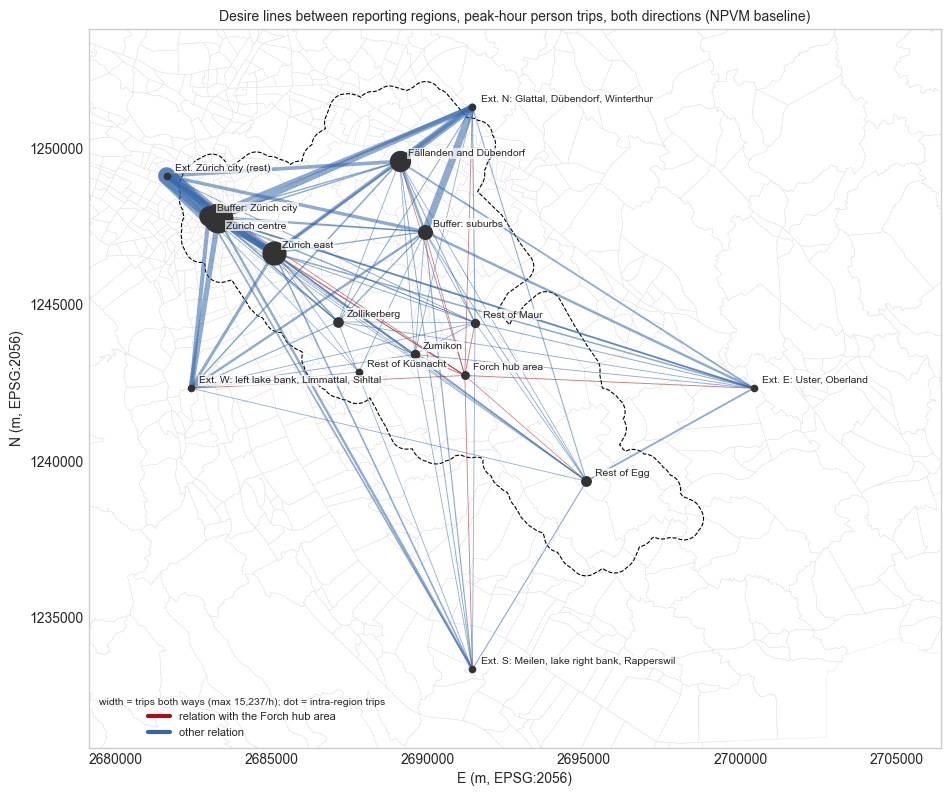

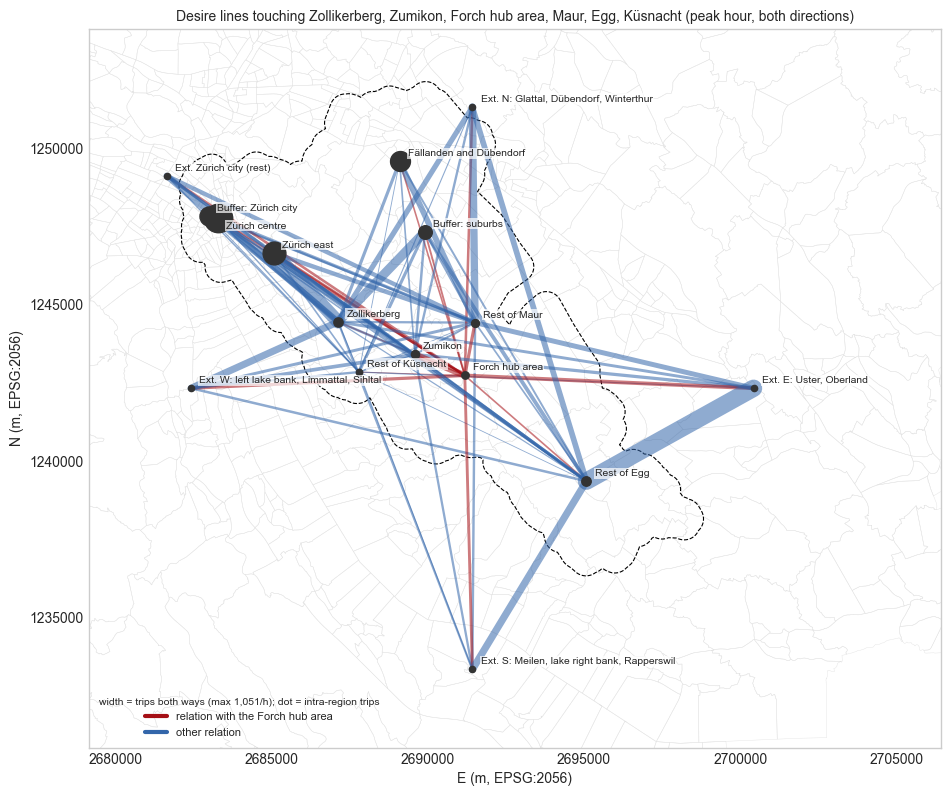

In [17]:
# Desire lines: whole corridor, then a focus on the Pfannenstiel regions so their small flows are visible.
ANCHORS = f1.region_anchor_points(ctx, REGIONS, STATIONS, FORCH)
fig = f1.plot_desire_lines(ctx, FORCH, REGION_OD, ANCHORS,
                           "Desire lines between reporting regions, peak-hour person trips, both directions (NPVM baseline)",
                           min_trips=50)
f1.save_figure(fig, "s1_4_desire_lines_all")
plt.show()
fig = f1.plot_desire_lines(ctx, FORCH, REGION_OD, ANCHORS,
                           "Desire lines touching Zollikerberg, Zumikon, Forch hub area, Maur, Egg, Küsnacht (peak hour, both directions)",
                           min_trips=5, focus=f1.PFANNENSTIEL)
f1.save_figure(fig, "s1_4_desire_lines_pfannenstiel")
plt.show()

In [18]:
# Key relations of decision D7 the 10 largest relations overall and the 10 largest relations that touch the Pfannenstiel regions.
EXT_N = "Ext. N: Glattal, Dübendorf, Winterthur"
KEY_PAIRS = [("Zürich centre", "Forch hub area"), ("Zürich east", "Forch hub area"),
             ("Forch hub area", "Rest of Egg"), ("Forch hub area", "Rest of Maur"),
             ("Zumikon", "Zürich centre"), ("Forch hub area", EXT_N)]
KEY_RELATIONS = f1.key_relations(REGION_OD, KEY_PAIRS)
pfannenstiel = f1.corridor_relevant_od(REGION_OD).stack().rename("trips").reset_index()
pfannenstiel.columns = ["origin", "destination", "trips"]
pfannenstiel = pfannenstiel[(pfannenstiel.origin != pfannenstiel.destination)
                            & (pfannenstiel.origin.isin(f1.PFANNENSTIEL) | pfannenstiel.destination.isin(f1.PFANNENSTIEL))]
KEY_RELATIONS = pd.concat([KEY_RELATIONS, pfannenstiel.nlargest(10, "trips").assign(set="10 largest Pfannenstiel relations")],
                          ignore_index=True)
f1.save_table(KEY_RELATIONS.round(1), "s1_4_key_relations")
display(KEY_RELATIONS.round(1))

,set,origin,destination,trips
0,D7 key relation,Zürich centre,Forch hub area,42.2
1,D7 key relation,Forch hub area,Zürich centre,39.2
2,D7 key relation,Zürich east,Forch hub area,59.5
3,D7 key relation,Forch hub area,Zürich east,52.6
4,D7 key relation,Forch hub area,Rest of Egg,30.5
5,D7 key relation,Rest of Egg,Forch hub area,31.0
6,D7 key relation,Forch hub area,Rest of Maur,77.7
7,D7 key relation,Rest of Maur,Forch hub area,78.9
8,D7 key relation,Zumikon,Zürich centre,37.6
9,D7 key relation,Zürich centre,Zumikon,40.5


### Internal, inbound, outbound and pass-through demand (mandatory)

Desire lines show the overall pattern. For the road model we also need to know how each trip meets the cordon:

- internal: it starts and ends inside;
- inbound: it starts outside and comes in through a gate;
- outbound: it starts inside and leaves through a gate;
- pass-through: it starts and ends outside but may drive across; the model keeps only an assumed share of these trips.

Every outside zone is attached to the nearest gate that lies in its direction. The table counts person trips in the peak hour. Background vehicles (lorries and other traffic that is not in the person matrix) and the course's extra road loading (the "endpoint uplift") are added later, in the road assignment of Section 1.6, so they are not in this table.


**Pass-through share (decision D4).** Gate → gate trips are external trips whose nearest entry and exit gates differ. Being near two different gates does not prove that a trip drives through the corridor, so the course keeps only a share of them (5 %). We test 0, 5 % and 10 %; 5 % stays unless traffic counts clearly support another value (checked in Section 1.6).

In [19]:
# collapse the canton wide OD matrix to internal zones and gates then test the pass through share.
BASELINE_CORDON_OD, BASELINE_CORDON_BREAKDOWN = tmi.collapse_od_to_gates(
    ctx.baseline_od, ctx, FORCH, passthrough_fraction=tmi.DEFAULT_PASSTHROUGH_FRACTION)
exports.save_outputs("1_4_cordon_demand", tables={"breakdown": BASELINE_CORDON_BREAKDOWN, "od": BASELINE_CORDON_OD})
f1.save_table(BASELINE_CORDON_BREAKDOWN, "s1_4_cordon_categories")
display(BASELINE_CORDON_BREAKDOWN)

PASSTHROUGH_TEST = f1.passthrough_test(tmi, ctx, FORCH, (0.0, 0.05, 0.10))
f1.save_table(PASSTHROUGH_TEST, "s1_4_passthrough_test")
display(PASSTHROUGH_TEST.round(0))

GATE_TOTALS = tmi.gate_totals(BASELINE_CORDON_OD, FORCH).merge(
    FORCH.gates[["gate_id", "highway", "capacity_vph"]], on="gate_id")
f1.save_table(GATE_TOTALS.round(1), "s1_4_gate_totals")
display(GATE_TOTALS.sort_values("cordon_total", ascending=False).head(10).round(0))

,category,trips,share_of_retained
0,internal -> internal,80740.163187,0.438506
1,gate -> internal,44040.004713,0.239184
2,internal -> gate,44840.537636,0.243532
3,gate -> gate (pass-through),14505.000260,0.078778


passthrough_fraction,category,0.0,0.05,0.1
0,gate -> gate (pass-through),0.0,14505.0,29010.0
1,gate -> internal,44040.0,44040.0,44040.0
2,internal -> gate,44841.0,44841.0,44841.0
3,internal -> internal,80740.0,80740.0,80740.0


,gate_id,to_internal,from_internal,passthrough_in,passthrough_out,cordon_total,highway,capacity_vph
31,G32,5984.0,6166.0,797.0,804.0,12950.0,tertiary,1500.0
37,G38,3761.0,3754.0,435.0,432.0,7949.0,primary,2100.0
18,G19,0.0,4162.0,3877.0,0.0,6101.0,motorway,4000.0
32,G33,2719.0,2743.0,353.0,352.0,5815.0,primary,3200.0
2,G03,3588.0,0.0,0.0,2920.0,5049.0,motorway_link,1000.0
19,G20,2430.0,1868.0,445.0,997.0,5019.0,residential,1700.0
7,G08,2282.0,2301.0,432.0,433.0,5016.0,secondary,1000.0
15,G16,2893.0,0.0,0.0,4114.0,4950.0,motorway,4000.0
43,G44,2245.0,2229.0,440.0,463.0,4925.0,residential,1500.0
21,G22,0.0,2349.0,3440.0,0.0,4069.0,motorway,4000.0


## 1.5 Baseline modal split (mandatory + tutorial)

Every traveller has five options: car, PT reached on foot (PT-walk), PT reached by bike (PT-bike), bike, walk. We report PT both **together** and **split by access mode** everywhere (decision D6), because a mobility hub acts mainly on how people get to and from the train.

**Trips versus passenger-kilometres (PKM).** A trip share counts every trip once: a 400 m walk to the shop weighs as much as a 15 km drive. A PKM share weighs each trip by its length. Walking and cycling trips are short, so they take a big share of trips and a small share of PKM; car and PT trips are longer, so their PKM shares are higher. Following the course, PKM for every mode uses the same distance, the car-road distance between the two zones, so the PKM share is a "how far would these trips go" indicator, not measured kilometres per mode.

**Distance filter (decision D5).** The course keeps only OD pairs of at least 5 km in the PKM share (`MIN_STRATEGIC_PKM_DISTANCE`). For Forch the question is whether the short hops between the hub area and Zumikon, Egg or Maur (3-5 km), which a hub could serve by bike-and-ride, would be lost. The rule: switch to 3 km only if those trips are at least 15 % of the hub area's motorised trips. The test below decides; 3 km and no filter are reported beside the headline either way.

,quantity,peak_hour_trips,share_of_hub_motorised
0,motorised trips with an end in the hub area,1395.015,1.000
1,"of which with Zumikon, Rest of Egg, Rest of Maur",265.536,0.190
2,of which with those areas and 3-5 km,99.918,0.072
3,all hub-area motorised trips 3-5 km,126.184,0.090
4,all hub-area motorised trips under 5 km,288.620,0.207


3-5 km trips between the hub area and Zumikon/Egg/Maur: 7.2% of the hub area's motorised trips -> headline filter stays 5 km


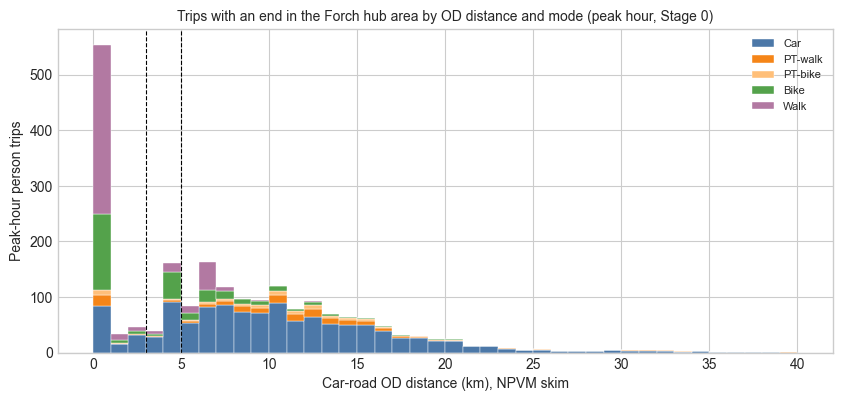

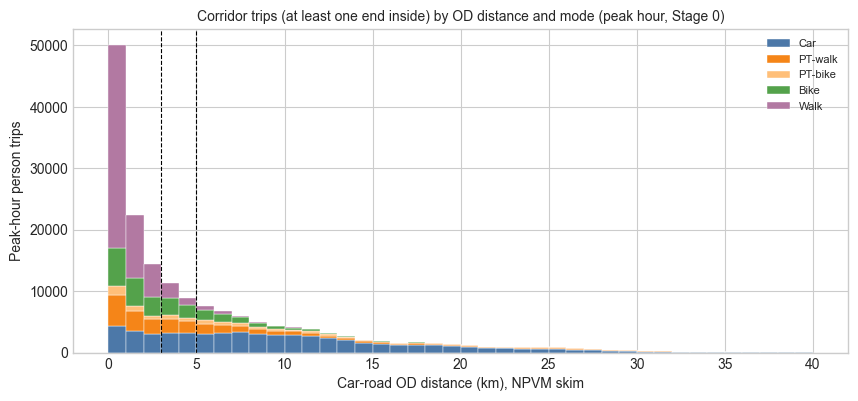

In [20]:
# Person trips by mode and OD distance on one zone order, plus the OD masks for the demand categories.
LABELS, MODE_TRIPS, OD_KM = f1.mode_arrays(ctx, res_stage0)
OD_MASKS = f1.od_masks(LABELS, FORCH)
CORRIDOR_MASK = OD_MASKS["corridor (at least one end inside)"]

# Decision D5: how much of the hub area's motorised demand is 3-5 km with Zumikon, Egg or Maur?
D5_TEST = f1.distance_band_test(MODE_TRIPS, OD_KM, LABELS, REGIONS)
f1.save_table(D5_TEST.round(4), "s1_5_d5_distance_test")
display(D5_TEST.round(3))
d5_share = D5_TEST.loc[2, "share_of_hub_motorised"]
print(f"3-5 km trips between the hub area and Zumikon/Egg/Maur: {d5_share:.1%} of the hub area's motorised trips "
      f"-> headline filter stays {p.MIN_STRATEGIC_PKM_DISTANCE:g} km" if d5_share < 0.15 else "-> switch to 3 km")

hub = REGIONS.reindex(LABELS).to_numpy() == "Forch hub area"
fig = f1.plot_distance_histogram(MODE_TRIPS, OD_KM, hub[:, None] | hub[None, :],
                                 "Trips with an end in the Forch hub area by OD distance and mode (peak hour, Stage 0)")
f1.save_figure(fig, "s1_5_distance_histogram_hub")
plt.show()
fig = f1.plot_distance_histogram(MODE_TRIPS, OD_KM, CORRIDOR_MASK,
                                 "Corridor trips (at least one end inside) by OD distance and mode (peak hour, Stage 0)")
f1.save_figure(fig, "s1_5_distance_histogram_corridor")
plt.show()

In [21]:
# Corridor modal split: trips and PKM with the headline filter 3 km and no filter side by side.
MIN_KM = p.MIN_STRATEGIC_PKM_DISTANCE
SPLITS = {f">= {MIN_KM:g} km (headline)": MIN_KM, ">= 3 km": 3.0, "no filter": None}
corridor_split = None
for label, min_km in SPLITS.items():
    t = f1.mode_table(MODE_TRIPS, OD_KM, CORRIDOR_MASK, min_km)
    if corridor_split is None:
        corridor_split = t[["mode", "trips", "trip_share"]].copy()
    corridor_split[f"PKM share {label}"] = t["pkm_share"]
    corridor_split[f"PKM {label}"] = t["pkm"]
f1.save_table(corridor_split, "s1_5_modal_split_corridor")
exports.save_outputs("1_5_baseline_modal_split", tables={"corridor": corridor_split})
display(corridor_split.style.format({c: "{:.1%}" for c in corridor_split if "share" in c} | {"trips": "{:,.0f}"}
                                    | {c: "{:,.0f}" for c in corridor_split if c.startswith("PKM ") and "share" not in c}))

# Same check against the course's own indicator function.
course_metrics = tmi.extract_corridor_metrics(ctx, res_stage0, corridor_zone_ids=corridor_zones)
print("Course function, PKM shares >= {:g} km: car {:.1%}, PT {:.1%}, bike {:.1%}, walk {:.1%}".format(
    MIN_KM, course_metrics["car_share"], course_metrics["pt_share"], course_metrics["bike_share"], course_metrics["walk_share"]))

,mode,trips,trip_share,PKM share >= 5 km (headline),PKM >= 5 km (headline),PKM share >= 3 km,PKM >= 3 km,PKM share no filter,PKM no filter
0,Car,"56,871",33.5%,67.6%,"525,852",64.3%,"551,287",60.1%,"566,009"
1,PT (all),"34,209",20.2%,24.6%,"191,414",24.8%,"212,724",24.3%,"228,536"
2,PT-walk,"25,072",14.8%,15.7%,"122,018",16.2%,"138,531",16.1%,"151,254"
3,PT-bike,"9,138",5.4%,8.9%,"69,396",8.7%,"74,193",8.2%,"77,282"
4,Bike,"24,584",14.5%,6.1%,"47,660",7.8%,"66,491",8.8%,"83,086"
5,Walk,"53,956",31.8%,1.7%,"13,371",3.1%,"26,470",6.8%,"64,526"
6,Total,"169,621",100.0%,100.0%,"778,298",100.0%,"856,972",100.0%,"942,157"


Course function, PKM shares >= 5 km: car 67.6%, PT 24.6%, bike 6.1%, walk 1.7%


In [22]:
# Modal split by demand category.
SPLIT_BY_CATEGORY = f1.split_by_category(MODE_TRIPS, OD_KM, OD_MASKS, MIN_KM)
f1.save_table(SPLIT_BY_CATEGORY, "s1_5_modal_split_by_category")
display(SPLIT_BY_CATEGORY.pivot(index="category", columns="mode", values="trip_share").round(3))

mode,Bike,Car,PT (all),PT-bike,PT-walk,Total,Walk
category,,,,,,,
corridor (at least one end inside),0.145,0.335,0.202,0.054,0.148,1.0,0.318
inbound (external -> internal),0.142,0.477,0.249,0.072,0.177,1.0,0.131
internal -> internal,0.148,0.182,0.145,0.031,0.114,1.0,0.525
outbound (internal -> external),0.142,0.473,0.257,0.077,0.180,1.0,0.128
"pass-through candidates (external -> external, different gates)",0.117,0.467,0.120,0.039,0.081,1.0,0.295


,origin,destination,total_trips,mean_car_km,Car trip share,PT (all) trip share,PT-walk trip share,PT-bike trip share,Bike trip share,Walk trip share
0,Zürich centre,Forch hub area,42,10.8,58.5%,36.3%,27.1%,9.2%,5.2%,0.0%
1,Forch hub area,Zürich centre,39,11.9,53.2%,40.8%,29.5%,11.4%,5.9%,0.0%
2,Zürich east,Forch hub area,59,8.8,53.4%,35.8%,25.2%,10.6%,10.5%,0.3%
3,Forch hub area,Zürich east,53,10.4,55.1%,32.0%,21.9%,10.0%,12.7%,0.3%
4,Forch hub area,Rest of Egg,31,4.5,87.5%,5.1%,2.7%,2.4%,6.2%,1.3%
5,Rest of Egg,Forch hub area,31,7.1,63.7%,16.0%,8.6%,7.3%,15.3%,5.0%
6,Forch hub area,Rest of Maur,78,6.7,38.5%,5.7%,3.5%,2.1%,14.0%,41.9%
7,Rest of Maur,Forch hub area,79,2.4,48.0%,5.6%,3.6%,2.0%,12.0%,34.4%
8,Zumikon,Zürich centre,38,7.1,41.0%,27.8%,19.9%,7.9%,31.2%,0.0%
9,Zürich centre,Zumikon,40,10.4,71.9%,18.4%,12.8%,5.6%,9.8%,0.0%


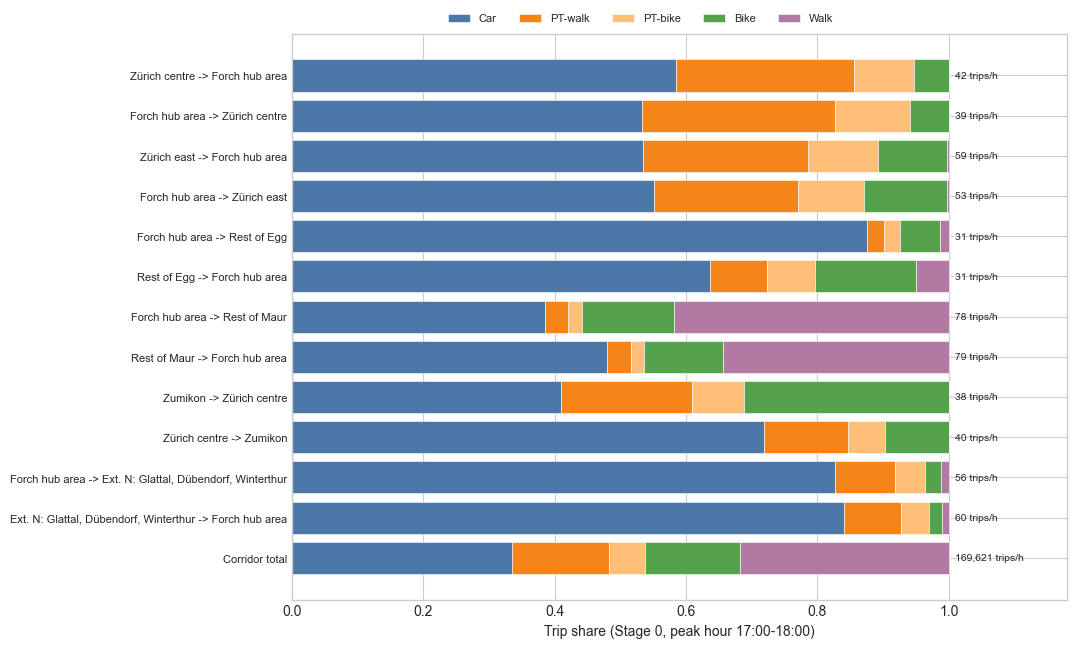

In [23]:
# Modal split for the key relations (D7) in both directions and the largest Pfannenstiel relations.
RELATIONS = [(o, d) for a, b in KEY_PAIRS for o, d in ((a, b), (b, a))]
RELATIONS += [tuple(r) for r in KEY_RELATIONS.loc[KEY_RELATIONS["set"] != "D7 key relation", ["origin", "destination"]]
              .drop_duplicates().itertuples(index=False) if tuple(r) not in RELATIONS]
SPLIT_BY_RELATION = f1.split_by_relation(MODE_TRIPS, OD_KM, LABELS, REGIONS, RELATIONS)
f1.save_table(SPLIT_BY_RELATION, "s1_5_modal_split_relations")
exports.save_outputs("1_5_baseline_modal_split", tables={"od_relations": SPLIT_BY_RELATION})
display(SPLIT_BY_RELATION.style.format({c: "{:.1%}" for c in SPLIT_BY_RELATION if "share" in c}
                                       | {"total_trips": "{:,.0f}", "mean_car_km": "{:.1f}"}))

# Chart: trip shares for the D7 relations next to the corridor total.
fig = f1.plot_relation_shares(SPLIT_BY_RELATION.head(len(KEY_PAIRS) * 2), corridor_split)
f1.save_figure(fig, "s1_5_modal_split_relations")
plt.show()

### Check cell (Sheet 2 §1.5)

Before using the modal split we check, over all OD pairs of the canton, that the five probabilities of every OD pair sum to one, that the aggregate shares sum to one, that no probability is below zero or above one, and that trips by mode add up to the total demand. A probability here is trips of a mode divided by the OD demand.

In [24]:
# The four checks
# every row must say passed = True.
MODE_CHOICE_CHECKS = f1.check_mode_choice(ctx, res_stage0)
f1.save_table(MODE_CHOICE_CHECKS, "s1_5_check_cell")
display(MODE_CHOICE_CHECKS)
assert MODE_CHOICE_CHECKS["passed"].all(), "A mode-choice consistency check failed"

,check,worst_value,passed
0,probabilities sum to one for every OD pair wit...,5.551115e-16,True
1,aggregate modal shares sum to one,1.554312e-15,True
2,"every probability lies in [0, 1]",0.000000e+00,True
3,trips by mode sum to total demand,0.000000e+00,True


### Validation inputs computed from this run (mandatory, see S1_validation.md)

The next cell computes the model side of every comparison in `S1_validation.md`: trip rates per resident, distance-weighted shares, the Forch hub catchment, mean trip length and annual PT trips around the Forchbahn. Reference values, their sources and access dates are in `tools/forch_s1.py` (`REFERENCES`) and are written next to the model values. It also reports how much corridor demand has no path in a mode's skim (a 999-minute "no path" value), because such OD pairs cannot choose that mode at all.

In [25]:
# Model values for the validation vs the published references
VALIDATION = f1.validation_table(f1.validation_comparators(
    ctx, res_stage0, MODE_TRIPS, OD_KM, LABELS, REGIONS, OD_MASKS, p.NOMINAL_PARAMS))
f1.save_table(VALIDATION, "s1_validation_demand_shares")
display(VALIDATION[["ref_id", "model_quantity", "model_value", "model_unit", "reference_value", "reference_unit", "gap_pct"]].round(3))

# Data-quality check: corridor demand without a path in a mode's skim.
NO_PATH = f1.no_path_diagnostics(ctx, res_stage0, LABELS, CORRIDOR_MASK)
f1.save_table(NO_PATH, "s1_validation_no_path")
display(NO_PATH.round(4))

,ref_id,model_quantity,model_value,model_unit,reference_value,reference_unit,gap_pct
0,R1,Weekday trips starting in the Forch hub area p...,2.089,trips/resident/day,2.90,trips/person/day,-27.957
1,R1,Weekday trips starting in the six Pfannenstiel...,2.429,trips/resident/day,2.90,trips/person/day,-16.254
2,R2a,"Car PKM share, corridor, peak hour, no distanc...",0.601,share,0.62,share,-3.103
3,R2b,"PT PKM share, corridor, peak hour, no distance...",0.243,share,0.28,share,-13.369
4,R2c,"Bike + walk PKM share, corridor, peak hour, no...",0.157,share,0.10,share,56.675
5,R3,Residents of the four Forch-hub-area zones (zo...,4990.000,residents,5000.00,people,-0.200
6,R4,Mean car-road OD distance of motorised peak-ho...,10.413,km,10.00,km,4.131
7,R5,PT trips with an end in the six Pfannenstiel r...,4692603.455,trips/year,6200000.00,passengers/year,-24.313


,mode,demand_without_path_share,worst_origin_zones
0,Car,0.0286,"19201001 (353), 16001003 (346), 19301001 (297)"
1,PT-walk,0.0065,"16001003 (346), 20001007 (178), 16001004 (86)"
2,PT-bike,0.0163,"6901018 (859), 16001003 (346), 26101094 (198)"
3,Bike,0.1581,"26101198 (1746), 26101218 (1570), 26101201 (1199)"
4,Walk,0.4651,"26101195 (1205), 26101201 (1199), 26101252 (1191)"


> **Checking the modal split against reality (mandatory)**
>
> The shares above can be compared with independent numbers: travel surveys, official statistics, earlier studies of the hub. We did this for the corridor total, for each demand category and for the key relations; the comparisons and their sources are in `deliverables/phase2/s1/S1_validation.md` (§1-§5).
>
> A difference is only a problem if trip length, location, the services on offer or the model's assumptions cannot explain it. The modal split matters because it decides how many cars go onto the roads, and through them congestion, travel-time savings, emissions and, later, the cost-benefit analysis.

### How mode choice works: utilities and the logit (tutorial)

Each traveller gives every mode a score called its **utility**, $U$. A higher (less negative) score means a more attractive option. The score is built from the trip's time and cost, each multiplied by a weight, called a coefficient and written $\beta$:

$$U_m = \beta_m + \beta_{TT} \cdot TT_m + \beta_{\text{cost}} \cdot C_m$$

- $TT_m$ is the travel time of mode $m$ for this origin and destination (driving from A to B, or taking PT from A to B). Each mode has its own.
- $\beta_{TT}$ says how much one minute hurts. It is negative, so a longer trip lowers the score. The more negative it is, the faster people leave slow modes.
- $C_m$ is the money cost: fuel for the car, the fare for PT. Walking and cycling cost nothing in the model.
- $\beta_{\text{cost}}$ says how much one franc hurts. It is negative too. The more negative it is, the more price-sensitive people are.

The coefficients were estimated from surveys of real choices; the course gives them to us (`data/transport/config/mode_choice.json`). Because minutes and francs end up on the same scale, a cheap, slow mode can be compared with a fast, expensive one. The real model has a few more terms than this short version, for example waiting, access and transfers for PT.

The **multinomial logit** then turns the scores into probabilities. The mode with the higher score gets the higher probability, but never all of it:

$$P_m = \frac{\exp(U_m)}{\sum_{k} \exp(U_k)}$$

#### The mode constant $\beta_m$

$\beta_m$, the alternative-specific constant (ASC), collects everything about a mode that time and cost do not capture: comfort, flexibility, privacy, shelter from the weather, image. Because the probabilities depend on $\exp(U_m)$, raising $\beta_m$ makes mode $m$ more attractive against all the others at once, and it pulls trips from every other mode.

The demand and PT-preference sliders below change trip totals and shares.

In [26]:
if callable(globals().get("dashboard_state", {}).get("close")):
    dashboard_state["close"]()

# Interactive mode-choice & parameter sensitivity dashboard: Stage 0 only
corridor_zones = list(FORCH.zone_ids)

stage_0_specs = {
    0: stages[0],}

dashboard_ui, dashboard_state = tmi.mode_choice_dashboard(
    ctx,
    # Keep Stage 0 fixed for now.
    # We can redo this later with more accurate inputs.
    stage_specs=stage_0_specs,  #here 'stages'
    corridor_zone_ids=corridor_zones,)

display(dashboard_ui)

The demand slider multiplies every OD flow by the same factor. With the same travel times and preferences, this changes the trip totals but not the shares. The **PT ASC shift** adds the same amount to the constants of both PT options; a positive shift makes PT more attractive than car, bike and walking.

The sliders update when you let go of them. A demand-only change reuses the current shares; a PT ASC change recomputes mode choice with the same travel times. **Refresh** redraws the current setting. Congestion feedback comes in Section 1.6.


**What the dashboard teaches, reproduced without clicks.** The next cell shifts the PT constant by -0.2, +0.2 and +0.5 utility units with everything else fixed and records the corridor shares. Scaling demand alone leaves shares unchanged (same skims, same preferences), so only the constant is varied.

In [27]:
# PT preference experiment: rerun Stage 0 mode choice with shifted PT constants.
asc_rows = []
for shift in (-0.2, 0.0, 0.2, 0.5):
    result = res_stage0 if shift == 0 else tmi.run_transport_mode_choice(
        ctx, stage=0, stage_specs=stages, corridor_zone_ids=corridor_zones, pt_asc_shift=shift)
    _, trips_shift, _ = f1.mode_arrays(ctx, result)
    t = f1.mode_table(trips_shift, OD_KM, CORRIDOR_MASK, MIN_KM).set_index("mode")
    asc_rows.append({"pt_asc_shift": shift, **{f"{m} trip share": t.loc[m, "trip_share"] for m in ["Car", "PT (all)", "PT-walk", "PT-bike", "Bike", "Walk"]},
                     f"PT PKM share >= {MIN_KM:g} km": t.loc["PT (all)", "pkm_share"]})
PT_ASC_EXPERIMENT = pd.DataFrame(asc_rows)
f1.save_table(PT_ASC_EXPERIMENT, "s1_5_pt_asc_experiment")
display(PT_ASC_EXPERIMENT.round(3))

,pt_asc_shift,Car trip share,PT (all) trip share,PT-walk trip share,PT-bike trip share,Bike trip share,Walk trip share,PT PKM share >= 5 km
0,-0.2,0.349,0.178,0.131,0.047,0.151,0.322,0.217
1,0.0,0.335,0.202,0.148,0.054,0.145,0.318,0.246
2,0.2,0.321,0.227,0.166,0.061,0.139,0.313,0.277
3,0.5,0.298,0.269,0.196,0.073,0.129,0.304,0.328


## 1.6 Traffic assignment and congestion feedback (tutorial + mandatory + advanced)

**Assignment** puts car traffic on the roads. It takes the car trips from the latest mode choice, turns them into vehicles with the car occupancy factor, adds the fixed background traffic and loads everything onto the reduced Forch network. Internal, inbound, outbound and pass-through trips all enter through the same zone-and-gate OD matrix.

Each driver is sent along the path that is currently fastest (**all-or-nothing**, AoN). Fuller roads get slower according to the **BPR function** (Bureau of Public Roads):

$$t_a = t_{a,0} \left[ 1 + \alpha_a \left( \frac{v_a}{c_a} \right)^{\beta_a} \right]$$

* $t_a$: travel time on link $a$ with traffic
* $t_{a,0}$: travel time on link $a$ when it is empty (free flow)
* $v_a / c_a$: volume divided by capacity ($V/C$) on link $a$
* $\alpha_a, \beta_a$: BPR parameters, here $\alpha = 0.15$ and $\beta = 4$

When times change, the fastest paths change too, so the model repeats. This is the **method of successive averages** (MSA): in iteration $k$ it computes the new fastest-path flows and mixes them into the previous flows with weight $1/k$ (half in iteration 2, a third in iteration 3, and so on). The weight shrinks, so the flows settle.

The loop stops when the **road relative gap** is at most 2 %. It is checked every four iterations, after at least 8 and at most 64 iterations. The gap compares the time drivers spend on their current routes with the time they would spend if everyone took the fastest route, for the same OD demand:

$$RG = \frac{\sum_a v_a t_a - \sum_{od} q_{od} c^{\mathrm{shortest}}_{od}}{\sum_a v_a t_a}.$$

A gap of 2 % means total road travel time is about 2 % above that fastest-route benchmark. It tells us the routes have settled. It does not prove that the whole system of mode choice and roads is in equilibrium. In the coupled run the comparison uses the averaged OD demand that the current flows carry.

The solver also tracks how much flow moved since the previous iteration (the relative L1 flow change). Because the MSA weight shrinks, this number becomes small even when routes are still poor, so it is not used to stop or plotted. Demand that cannot reach its destination is reported separately: a small gap does not mean every OD pair has a path.

The dashboard controls (gap target, iteration cap, OD cutoff with default zero, pass-through share) only change the interactive runs in this section. The defaults for the rest of the notebook are in `ASSIGNMENT_SETTINGS` in [`transport_model_interface.py`](../code/transport_model_interface.py).

The first dashboard keeps car demand fixed, so you can watch the assignment on its own. Use the map selector and click on links to see flow, $V/C$, congested time, speed and capacity. The coupled dashboard further down closes the loop: there, congestion also changes the modal split.

In [28]:
# Assignment uses the nominal baseline
mode_result = res_stage0

print(
    "Assignment has not started. Use the controls below and click "
    "'Run corridor MSA assignment' to begin."
)

# demand preparation, MSA, diagnostics, convergence chart, audit tables, and the interactive map live in tmi.
ASSIGNMENT_MODE_STATE = {"result": mode_result}
ASSIGNMENT_UI, ASSIGNMENT_STATE = tmi.assignment_dashboard(
    ctx,
    FORCH,
    ASSIGNMENT_MODE_STATE,
    modal_feedback=False,  # isolate car traffic assignment first
)
display(ASSIGNMENT_UI)

Assignment has not started. Use the controls below and click 'Run corridor MSA assignment' to begin.


### Fixed-demand assignment without clicks (tutorial)

The dashboard above needs a click. The next cell runs the same fixed-demand assignment directly (car demand from the Stage-0 mode choice, no feedback) and saves flows, volume/capacity (V/C), delay and speed for every link (`tables/s1_6_links_fixed.csv`).

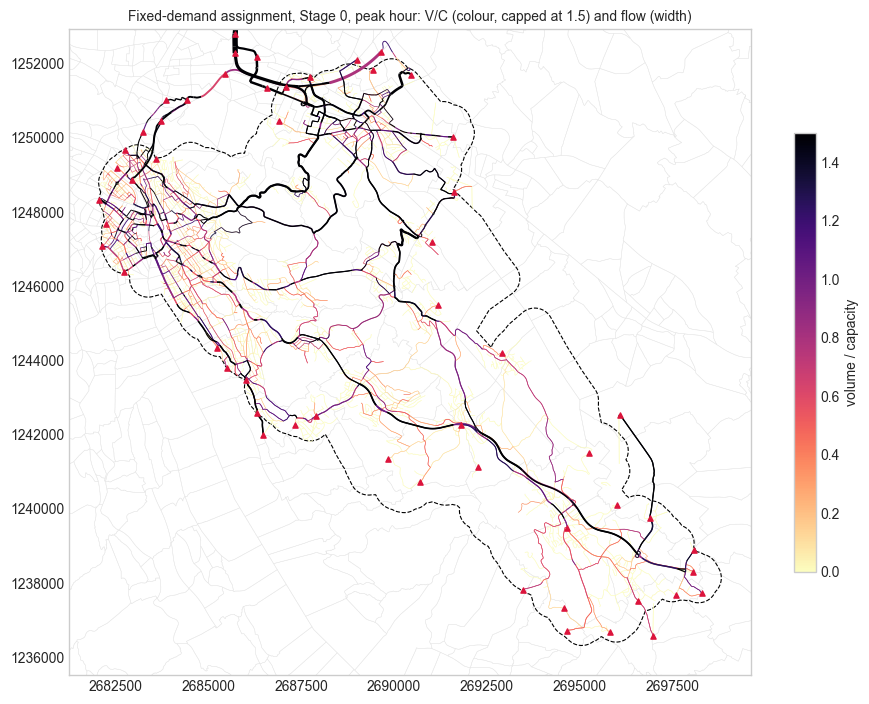

In [29]:
# Fixed demand MSA assignment with the shared settings, then link results and a V/C map.
fixed_assignment = tmi.run_corridor_assignment(
    ctx, FORCH, res_stage0, passthrough_fraction=tmi.DEFAULT_PASSTHROUGH_FRACTION,
    **tmi.assignment_solver_kwargs(ASSIGNMENT_OPTIONS, coupled=False))
LINKS_FIXED = f1.link_frame(ctx, fixed_assignment.links, REGIONS)
f1.save_table(LINKS_FIXED.drop(columns="geometry"), "s1_6_links_fixed")
fig = f1.plot_link_map(ctx, FORCH, LINKS_FIXED, "volume_capacity_ratio",
                       "Fixed-demand assignment, Stage 0, peak hour: V/C (colour, capped at 1.5) and flow (width)",
                       vmax=1.5, label="volume / capacity")
f1.save_figure(fig, "s1_6_vc_fixed")
plt.show()

### Is the stopping rule good enough? (tutorial)

This experiment changes demand slightly, reruns the fixed-demand assignment several times and plots the **road relative gap** at each checked iteration (the same definition as above). Each run stops at the 2 % target or at the iteration cap, so the curve at a given iteration only includes the runs still going.

The median, the interquartile range and the share of runs that reached each threshold show how much computing the 2 % rule needs. These are numerical tests: they are not future scenarios and not a calibration against counts.

> This takes a few minutes. `N_CONVERGENCE_RUNS` sets the number of runs.

,iteration,median,q25,q75,observed_runs
0,8,0.148,0.118,0.163,6
1,12,0.073,0.065,0.084,6
2,16,0.059,0.045,0.063,6
3,20,0.038,0.034,0.045,6
4,24,0.031,0.028,0.033,6
5,28,0.026,0.020,0.030,5
6,32,0.022,0.021,0.024,4
7,36,0.022,0.019,0.023,3
8,40,0.019,0.018,0.020,2
9,44,0.014,0.014,0.014,1


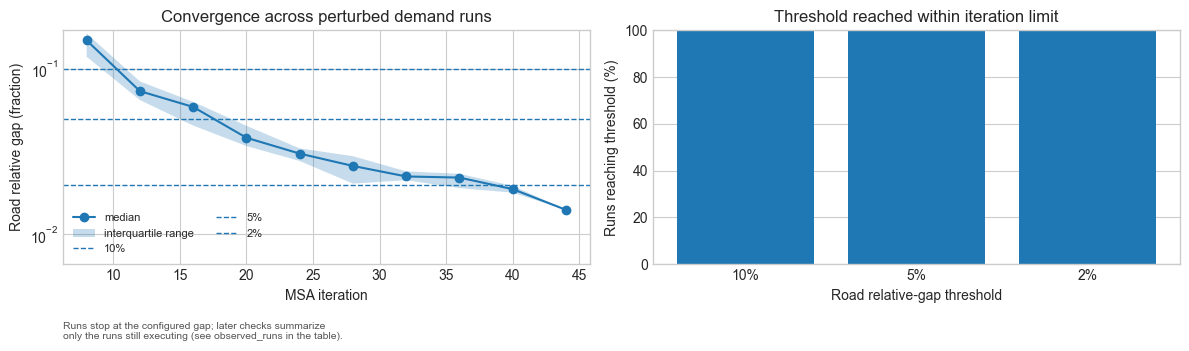

PosixPath('/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/deliverables/phase2/s1/figures/s1_6_msa_convergence.png')

In [30]:
# Parallel numerical stability test for the fixed-demand MSA calculation.

N_CONVERGENCE_RUNS = 6
CONVERGENCE_MAX_ITERATIONS = ASSIGNMENT_OPTIONS["max_iterations"]
CONVERGENCE_THRESHOLDS = (0.10, 0.05, 0.02)

N_CONVERGENCE_JOBS = 1

MSA_CONVERGENCE = tmi.assignment_convergence_test(
    ctx,
    FORCH,
    mode_result,
    n_runs=N_CONVERGENCE_RUNS,
    max_iterations=CONVERGENCE_MAX_ITERATIONS,
    thresholds=CONVERGENCE_THRESHOLDS,
    n_jobs=N_CONVERGENCE_JOBS,
)

exports.save_outputs("1_6_msa_convergence", tables=MSA_CONVERGENCE)
display(
    MSA_CONVERGENCE["summary"].style.format({
        "median": "{:.3f}",
        "q25": "{:.3f}",
        "q75": "{:.3f}",
    })
)

MSA_CONVERGENCE_FIGURE = tmi.plot_assignment_convergence_test(
    MSA_CONVERGENCE,
    thresholds=CONVERGENCE_THRESHOLDS,
)
exports.save_outputs("1_6_msa_convergence", figure=MSA_CONVERGENCE_FIGURE)
display(MSA_CONVERGENCE_FIGURE)
f1.save_table(MSA_CONVERGENCE["summary"], "s1_6_msa_convergence_summary")
f1.save_figure(MSA_CONVERGENCE_FIGURE, "s1_6_msa_convergence")

The chart shows the gap at each checked iteration. A run that stopped earlier does not count at later iterations. A run that hits the iteration cap before reaching the target is reported as not converged; raising the cap would be a separate modelling choice.

### Closing the loop: mode choice inside the MSA iterations

The fixed-demand run above updates routes and link times, but the car demand it assigns was computed once, from travel times on empty roads. A traveller choosing between car, PT, bike and walking never sees the congestion. The coupled run adds that feedback inside the same MSA loop. In every iteration:

1. the BPR function updates every link time from the current flow;
2. the fastest paths give the next target flows;
3. the travel times between every internal zone and every gate are recorded, on empty roads and with the current congestion;
4. the extra time caused by congestion (never negative) is added to the canton-wide car travel-time table of 1,223 zones; the parts of a trip outside the local network keep their fixed time;
5. the five-option logit recomputes car, walk, bike, PT-walk and PT-bike demand; the new car demand is collapsed to zones and gates and averaged with the same $1/k$ weight as the flows.

This is an approximation on the local network: only links in the assignment network (including a few connecting links just outside the cordon) change their times. Each OD pair runs through its own zones and gates, so each gets its own congested time.

In [31]:
# Run the same assignment controls with congestion-to-mode-choice feedback.
COUPLED_ASSIGNMENT_UI, COUPLED_ASSIGNMENT_STATE = tmi.assignment_dashboard(
    ctx,
    FORCH,
    ASSIGNMENT_MODE_STATE,
    modal_feedback=True,
)
display(COUPLED_ASSIGNMENT_UI)

The next cell compares the fixed-demand run with the coupled run under the same settings. It reuses the dashboard results only if their inputs match the shared settings; otherwise it computes what is missing. So the only difference between the two runs is whether congestion feeds back into mode choice.

Calculating fixed-demand assignment with shared settings...
Calculating coupled assignment with shared settings...


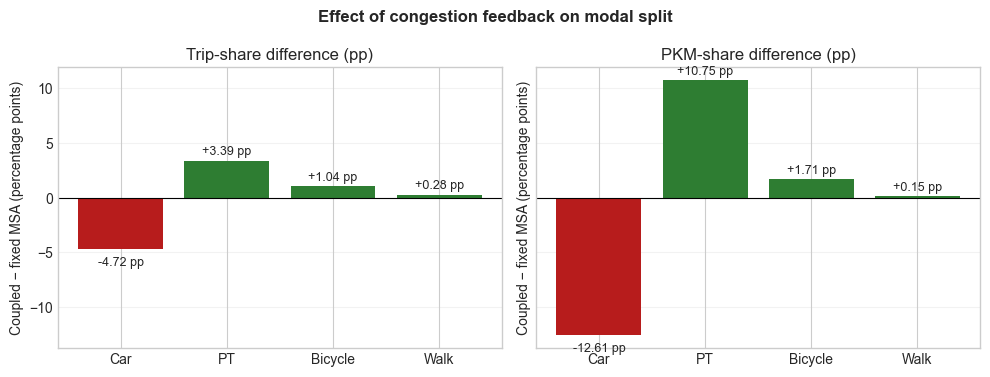

In [32]:
# Compare the same baseline network and solver settings with and without feedback.
_assignment_mode_result = ASSIGNMENT_MODE_STATE.get("result")
if _assignment_mode_result is None:
    raise RuntimeError("Run the Stage 0 mode-choice calculation before this cell.")

def matching_dashboard(state, coupled):
    result = state.get("result")
    return (
        result is not None
        and state.get("context") is ctx
        and state.get("corridor") is FORCH
        and state.get("mode_cache_key") == tuple(_assignment_mode_result.cache_key)
        and bool(result.diagnostics.get("modal_feedback", False)) == coupled
        and tmi.assignment_settings_match(result.diagnostics, ASSIGNMENT_OPTIONS,
                                         passthrough_fraction=tmi.DEFAULT_PASSTHROUGH_FRACTION)
    )

def comparison_assignment(state, coupled):
    if matching_dashboard(state, coupled):
        return state["result"]
    print(f"Calculating {'coupled' if coupled else 'fixed-demand'} assignment with shared settings...")
    runner = tmi.run_coupled_corridor_assignment if coupled else tmi.run_corridor_assignment
    result = runner(ctx, FORCH, _assignment_mode_result,
        passthrough_fraction=tmi.DEFAULT_PASSTHROUGH_FRACTION,
        **tmi.assignment_solver_kwargs(ASSIGNMENT_OPTIONS, coupled=coupled))
    # Keep the interactive dashboard's own selected result separate.
    return result

fixed_assignment = comparison_assignment(ASSIGNMENT_STATE, False)
coupled_assignment = comparison_assignment(COUPLED_ASSIGNMENT_STATE, True)

# -------------------------------------------------------------------------
# 1. Difference in modal split
# Values are percentage-point changes: coupled minus fixed-demand MSA.
# -------------------------------------------------------------------------

fixed_mode = (
    fixed_assignment.mode_result
    if fixed_assignment.mode_result is not None
    else ASSIGNMENT_MODE_STATE["result"]
)
coupled_mode = coupled_assignment.mode_result

if coupled_mode is None:
    raise RuntimeError("The coupled assignment contains no updated mode-choice result.")

zone_ids = (
    corridor_zones
    if "corridor_zones" in globals()
    else FORCH.zone_ids
)

fixed_metrics = tmi.extract_corridor_metrics(
    ctx, fixed_mode, corridor_zone_ids=zone_ids
)
coupled_metrics = tmi.extract_corridor_metrics(
    ctx, coupled_mode, corridor_zone_ids=zone_ids
)

modes = {
    "Car": "car",
    "PT": "pt",
    "Bicycle": "bike",
    "Walk": "walk",
}

modal_difference = pd.DataFrame({
    "Trip-share difference (pp)": {
        mode: 100 * (
            coupled_metrics[f"{key}_share_trips"]
            - fixed_metrics[f"{key}_share_trips"]
        )
        for mode, key in modes.items()
    },
    "PKM-share difference (pp)": {
        mode: 100 * (
            coupled_metrics[f"{key}_share"]
            - fixed_metrics[f"{key}_share"]
        )
        for mode, key in modes.items()
    },
})

exports.save_outputs("1_6_feedback_modal_difference", tables={"": modal_difference})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)

for axis, column in zip(axes, modal_difference.columns):
    values = modal_difference[column]
    colours = ["#2e7d32" if value >= 0 else "#b71c1c" for value in values]

    bars = axis.bar(values.index, values, color=colours)
    axis.axhline(0, color="black", linewidth=0.8)
    axis.set_title(column)
    axis.set_ylabel("Coupled − fixed MSA (percentage points)")
    axis.grid(axis="y", alpha=0.25)

    for bar, value in zip(bars, values):
        axis.annotate(
            f"{value:+.2f} pp",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 4 if value >= 0 else -12),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

fig.suptitle("Effect of congestion feedback on modal split", fontweight="bold")
fig.tight_layout()
exports.save_outputs("1_6_feedback_modal_difference", figure=fig)
plt.show()


# -------------------------------------------------------------------------
# 2. Relative difference in link-assignment results
# Only percentage-change attributes are retained in the map.
# -------------------------------------------------------------------------

def indexed_links(links):
    """Create a stable comparison key for directed links."""
    frame = links.copy().reset_index(drop=True)

    if (
        "edge_id" in frame
        and frame["edge_id"].notna().all()
        and not frame["edge_id"].astype(str).duplicated().any()
    ):
        frame["_comparison_key"] = frame["edge_id"].astype(str)
    else:
        occurrence = frame.groupby(
            ["source", "target"], sort=False
        ).cumcount().astype(str)

        frame["_comparison_key"] = (
            frame["source"].astype(str)
            + " → "
            + frame["target"].astype(str)
            + " #"
            + occurrence
        )

    return frame.set_index("_comparison_key", drop=False)


def relative_change(after, before):
    """Percentage change; undefined where the fixed-MSA value is zero."""
    after = pd.to_numeric(after, errors="coerce").to_numpy(dtype=float)
    before = pd.to_numeric(before, errors="coerce").to_numpy(dtype=float)

    return np.divide(
        100 * (after - before), np.abs(before),
        out=np.full_like(before, np.nan), where=np.abs(before) > 1e-9,
    )


fixed_links = indexed_links(fixed_assignment.links)
coupled_links = indexed_links(coupled_assignment.links)

common_links = fixed_links.index.intersection(coupled_links.index)
if common_links.empty:
    raise RuntimeError("The two assignments contain no matching directed links.")

# Retain identifiers, geometry, and percentage differences only.
identifier_columns = [
    column
    for column in (
        "_comparison_key", "edge_id", "source", "target", "highway", "geometry"
    )
    if column in coupled_links
]

link_differences = coupled_links.loc[
    common_links, identifier_columns
].copy()

comparison_metrics = {
    "flow_difference_pct": "flow_vehicles",
    "vc_difference_pct": "volume_capacity_ratio",
    "time_difference_pct": "time_min",
    "speed_difference_pct": "assigned_speed_kph",
}

for output_column, source_column in comparison_metrics.items():
    link_differences[output_column] = relative_change(
        coupled_links.loc[common_links, source_column],
        fixed_links.loc[common_links, source_column],
    )

exports.save_outputs("1_6_feedback_link_differences", tables={
    "": link_differences.drop(columns="geometry", errors="ignore"),
})
NETWORK_FEEDBACK_DIFFERENCE_MAP = tmi.network_explorer(
    link_differences,
    {
        "Traffic-volume difference (%)": {
            "column": "flow_difference_pct",
        },
        "Volume/capacity difference (%)": {
            "column": "vc_difference_pct",
        },
        "Congested-time difference (%)": {
            "column": "time_difference_pct",
        },
        "Assigned-speed difference (%)": {
            "column": "speed_difference_pct",
        },
    },
    gates=FORCH.gates,
    polygon=FORCH.polygon_gdf,
    title=(
        "Coupled modal-feedback MSA minus fixed-demand MSA - "
        "relative link differences only"
    ),
    height=650,
)

display(NETWORK_FEEDBACK_DIFFERENCE_MAP)

### Fixed demand versus congestion feedback, bottlenecks and checks (mandatory)

The table compares the two runs on the same network and settings: total and per-area delay, speed, vehicle-kilometres and modal shares. "Zürich city" and "outside Zürich city" split the links by where they lie, so the Forch side of the corridor can be read on its own. The bottleneck tables list the links with the most delay (vehicle-hours in the peak hour), first in the whole cordon, then outside the city.

,0,1
run,fixed demand,coupled (congestion feedback)
iterations,32,28
termination,converged,converged
final_road_gap,0.017974,0.018381
vehicles_assigned,84966.390027,72306.477284
car_driver_vehicles,55829.235402,46246.993866
vkt,717010.85582,531181.730328
vht,70618.500631,15998.696335
delay_veh_h,56899.386718,6012.275878
mean_speed_kph,10.1533,33.201563


,edge_id,highway,municipality,region,lat,lon,length_m,lanes,capacity_vph,flow_vehicles,volume_capacity_ratio,free_flow_time_min,delay_min,assigned_speed_kph,delay_veh_h
0,E00061739,secondary,Wallisellen,"Ext. N: Glattal, Dübendorf, Winterthur",47.42,8.57,1964.49,1.0,1000.0,2146.82,2.15,2.14,6.83,13.14,244.32
1,E00008038,living_street,Zürich,Ext. Zürich city (rest),47.40,8.55,151.18,1.0,400.0,1258.27,3.15,0.60,8.88,0.96,186.27
2,E00120577,secondary,Opfikon,"Ext. N: Glattal, Dübendorf, Winterthur",47.43,8.57,773.57,1.0,1000.0,2321.42,2.32,0.84,3.68,10.27,142.23
3,E00090265,secondary,Küsnacht (ZH),"Ext. W: left lake bank, Limmattal, Sihltal",47.33,8.58,1592.84,1.0,1000.0,1997.50,2.00,1.74,4.15,16.23,138.15
4,E00105015,tertiary,Zürich,Ext. Zürich city (rest),47.41,8.56,205.01,1.0,900.0,2447.07,2.72,0.41,3.36,3.26,137.09
5,E00055468,secondary,Küsnacht (ZH),"Ext. W: left lake bank, Limmattal, Sihltal",47.33,8.58,1592.84,1.0,1000.0,1927.12,1.93,1.74,3.59,17.92,115.46
6,OSM_292354553_1492866021_0,secondary,Dübendorf,Fällanden and Dübendorf,47.39,8.60,1422.99,2.0,1600.0,2862.28,1.79,1.55,2.38,21.69,113.77
7,OSM_1492865571_1492865473_0,tertiary,Dübendorf,Fällanden and Dübendorf,47.37,8.61,650.14,1.0,900.0,2027.05,2.25,0.87,3.35,9.26,113.04
8,E00048474,motorway,Opfikon,"Ext. N: Glattal, Dübendorf, Winterthur",47.42,8.57,864.67,2.0,4000.0,7391.01,1.85,0.52,0.91,36.38,111.74
9,E00108835,secondary,Mönchaltorf,"Ext. E: Uster, Oberland",47.32,8.72,3062.16,1.0,1000.0,1628.98,1.63,3.34,3.53,26.75,95.79


,edge_id,highway,municipality,region,lat,lon,length_m,lanes,capacity_vph,flow_vehicles,volume_capacity_ratio,free_flow_time_min,delay_min,assigned_speed_kph,delay_veh_h
0,E00061739,secondary,Wallisellen,"Ext. N: Glattal, Dübendorf, Winterthur",47.42,8.57,1964.49,1.0,1000.0,2146.82,2.15,2.14,6.83,13.14,244.32
1,E00120577,secondary,Opfikon,"Ext. N: Glattal, Dübendorf, Winterthur",47.43,8.57,773.57,1.0,1000.0,2321.42,2.32,0.84,3.68,10.27,142.23
2,E00090265,secondary,Küsnacht (ZH),"Ext. W: left lake bank, Limmattal, Sihltal",47.33,8.58,1592.84,1.0,1000.0,1997.50,2.00,1.74,4.15,16.23,138.15
3,E00055468,secondary,Küsnacht (ZH),"Ext. W: left lake bank, Limmattal, Sihltal",47.33,8.58,1592.84,1.0,1000.0,1927.12,1.93,1.74,3.59,17.92,115.46
4,OSM_292354553_1492866021_0,secondary,Dübendorf,Fällanden and Dübendorf,47.39,8.60,1422.99,2.0,1600.0,2862.28,1.79,1.55,2.38,21.69,113.77
5,OSM_1492865571_1492865473_0,tertiary,Dübendorf,Fällanden and Dübendorf,47.37,8.61,650.14,1.0,900.0,2027.05,2.25,0.87,3.35,9.26,113.04
6,E00048474,motorway,Opfikon,"Ext. N: Glattal, Dübendorf, Winterthur",47.42,8.57,864.67,2.0,4000.0,7391.01,1.85,0.52,0.91,36.38,111.74
7,E00108835,secondary,Mönchaltorf,"Ext. E: Uster, Oberland",47.32,8.72,3062.16,1.0,1000.0,1628.98,1.63,3.34,3.53,26.75,95.79
8,OSM_1492866049_26638971_0,secondary,Dübendorf,Fällanden and Dübendorf,47.40,8.60,116.41,1.0,1000.0,3036.35,3.04,0.14,1.78,3.64,90.13
9,E00054882,secondary,Mönchaltorf,"Ext. E: Uster, Oberland",47.32,8.72,3062.16,1.0,1000.0,1597.84,1.60,3.34,3.27,27.81,86.98


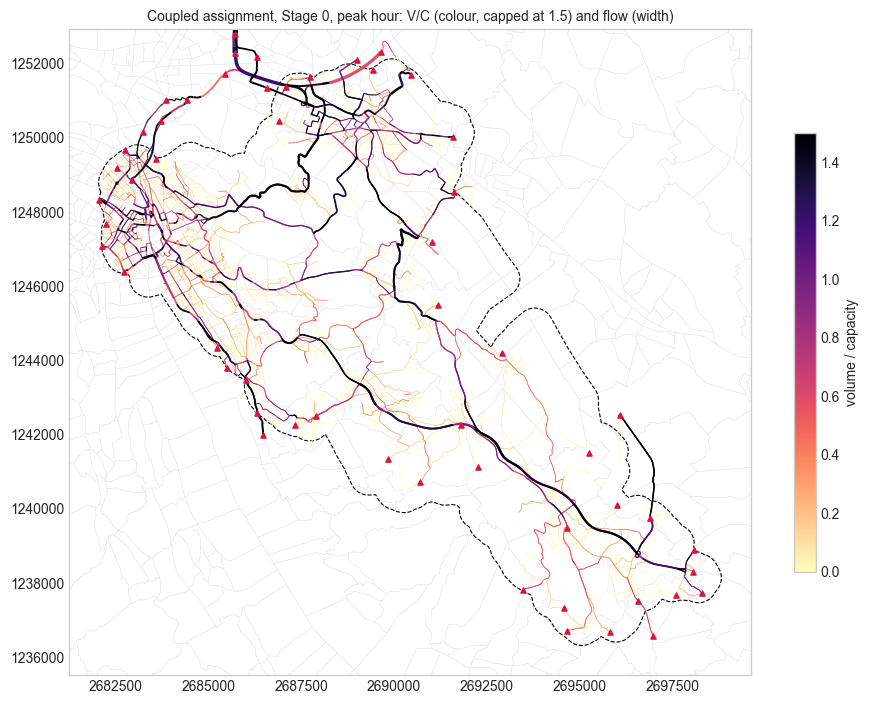

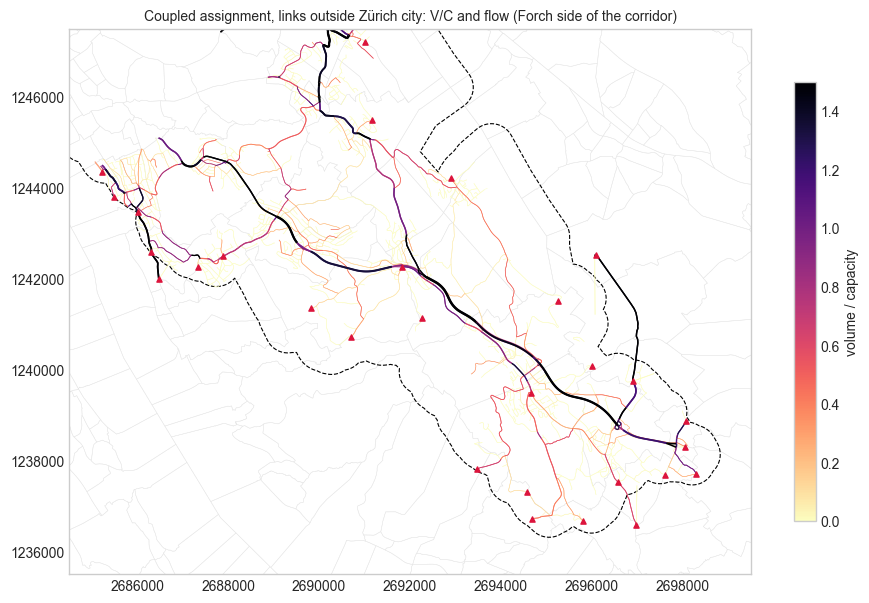

In [33]:
# Headline results of both runs, split by area.
LINKS_COUPLED = f1.link_frame(ctx, coupled_assignment.links, REGIONS)
f1.save_table(LINKS_COUPLED.drop(columns="geometry"), "s1_6_links_coupled")
ASSIGNMENT_COMPARISON = pd.DataFrame([f1.assignment_summary("fixed demand", fixed_assignment, LINKS_FIXED),
                                      f1.assignment_summary("coupled (congestion feedback)", coupled_assignment, LINKS_COUPLED)])
for key in ("car", "pt", "bike", "walk"):
    ASSIGNMENT_COMPARISON[f"{key}_trip_share"] = [fixed_metrics[f"{key}_share_trips"], coupled_metrics[f"{key}_share_trips"]]
    ASSIGNMENT_COMPARISON[f"{key}_pkm_share"] = [fixed_metrics[f"{key}_share"], coupled_metrics[f"{key}_share"]]
f1.save_table(ASSIGNMENT_COMPARISON, "s1_6_fixed_vs_coupled")
display(ASSIGNMENT_COMPARISON.T)

# Bottlenecks: whole cordon and outside the city.
BOTTLENECKS = f1.bottlenecks(LINKS_COUPLED, 15)
BOTTLENECKS_OUTSIDE = f1.bottlenecks(LINKS_COUPLED, 15, area="outside Zürich city")
f1.save_table(BOTTLENECKS, "s1_6_bottlenecks_all")
f1.save_table(BOTTLENECKS_OUTSIDE, "s1_6_bottlenecks_outside_city")
display(BOTTLENECKS.round(2))
display(BOTTLENECKS_OUTSIDE.round(2))

fig = f1.plot_link_map(ctx, FORCH, LINKS_COUPLED, "volume_capacity_ratio",
                       "Coupled assignment, Stage 0, peak hour: V/C (colour, capped at 1.5) and flow (width)",
                       vmax=1.5, label="volume / capacity")
f1.save_figure(fig, "s1_6_vc_coupled")
plt.show()
fig = f1.plot_link_map(ctx, FORCH, LINKS_COUPLED[LINKS_COUPLED["area"] == "outside Zürich city"], "volume_capacity_ratio",
                       "Coupled assignment, links outside Zürich city: V/C and flow (Forch side of the corridor)",
                       vmax=1.5, label="volume / capacity", zoom=(2684500, 1235500, 2699500, 1247500))
f1.save_figure(fig, "s1_6_vc_coupled_forch_side")
plt.show()

In [34]:
# Checks asked for by Sheet 2 §1.6, for both runs.
ASSIGNMENT_CHECKS = pd.concat([
    f1.assignment_checks(fixed_assignment, LINKS_FIXED).assign(run="fixed demand"),
    f1.assignment_checks(coupled_assignment, LINKS_COUPLED).assign(run="coupled")], ignore_index=True)
f1.save_table(ASSIGNMENT_CHECKS, "s1_6_checks")
display(ASSIGNMENT_CHECKS)

,check,value,passed,run
0,no negative link flows,0.000000,True,fixed demand
1,no negative congested times,0.001408,True,fixed demand
2,no negative delays,0.000000,True,fixed demand
3,congested time >= free-flow time on every link,0.000000,True,fixed demand
4,all OD demand served (unserved vehicles),0.000000,True,fixed demand
5,road gap at the last checks (values),0.017974,True,fixed demand
6,largest change of a mode share over the last 3...,NaN,not applicable (fixed demand),fixed demand
7,"links with V/C > 2 (count; plausibility flag, ...",299.000000,True,fixed demand
8,no negative link flows,0.000000,True,coupled
9,no negative congested times,0.001341,True,coupled


### Pass-through share and road delay (decision D4)

Pass-through trips only matter for the roads, so the coupled Stage-0 run is repeated with 0, 5 % and 10 % pass-through. If delay hardly moves, the 5 % assumption is harmless; if it moves a lot, it needs count evidence.

In [35]:
# Coupled Stage 0 runs with three pass through shares.
pt_rows = []
for share in (0.0, 0.05, 0.10):
    result = coupled_assignment if share == tmi.DEFAULT_PASSTHROUGH_FRACTION else tmi.run_coupled_corridor_assignment(
        ctx, FORCH, res_stage0, passthrough_fraction=share, **tmi.assignment_solver_kwargs(ASSIGNMENT_OPTIONS))
    pt_rows.append({"passthrough_fraction": share,
                    **f1.assignment_summary(f"pass-through {share:.0%}", result, f1.link_frame(ctx, result.links))})
PASSTHROUGH_DELAY = pd.DataFrame(pt_rows)
f1.save_table(PASSTHROUGH_DELAY, "s1_6_passthrough_delay")
display(PASSTHROUGH_DELAY[["passthrough_fraction", "vehicles_assigned", "delay_veh_h", "delay_veh_h_city",
                           "delay_veh_h_outside_city", "mean_speed_kph", "final_road_gap"]].round(3))

,passthrough_fraction,vehicles_assigned,delay_veh_h,delay_veh_h_city,delay_veh_h_outside_city,mean_speed_kph,final_road_gap
0,0.00,66696.372,4712.890,1411.860,3301.031,35.267,0.019
1,0.05,72306.477,6012.276,1651.603,4360.673,33.202,0.018
2,0.10,77311.668,7420.403,1920.105,5500.298,31.171,0.019


### Demand multipliers (tutorial)

Here all passenger OD demand is scaled by the same factor, to see how congestion and mode choice respond. Background road traffic stays fixed. Every run uses the same gap target and iteration cap; easy cases may stop earlier.

> The four runs take a few minutes.

Completed 4 demand scenarios × up to 64 MSA iterations using 1 parallel workers in 204.7s.


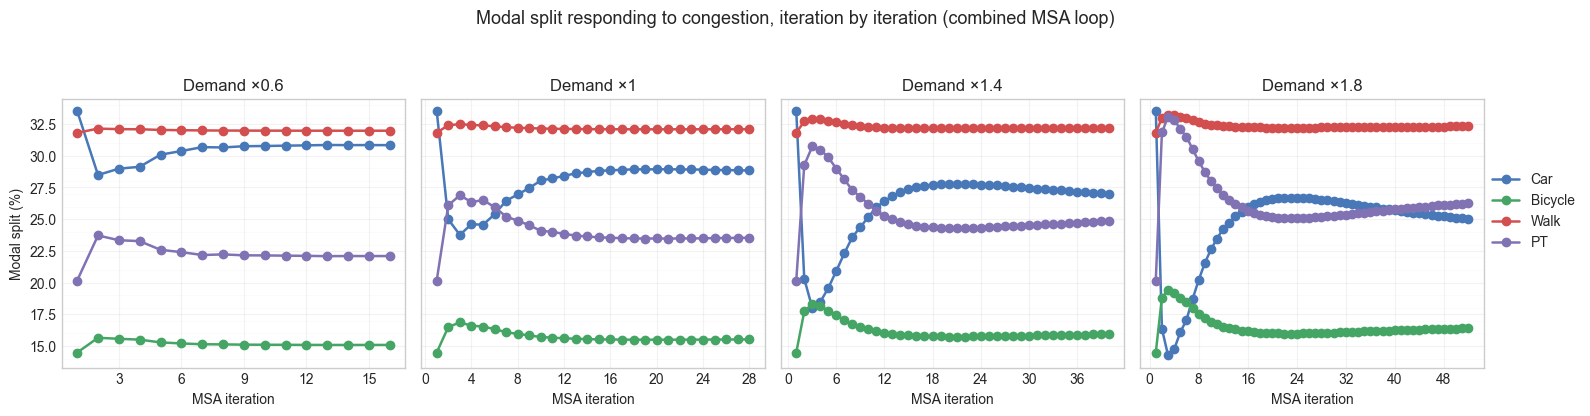

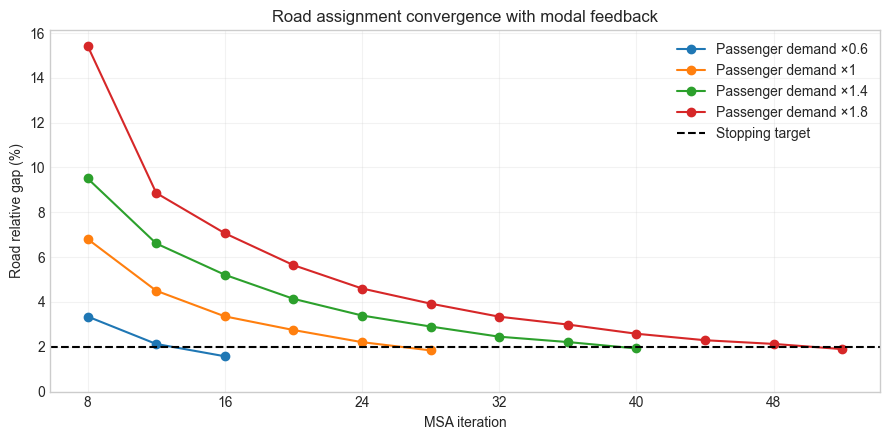

,demand_multiplier,iterations,final_road_relative_gap_feasible_averaged_od,termination_reason
0,0.6,16,0.015753,converged
1,1.0,28,0.018381,converged
2,1.4,40,0.019251,converged
3,1.8,52,0.018945,converged


PosixPath('/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/deliverables/phase2/s1/tables/s1_6_demand_multipliers.csv')

In [36]:
DEMAND_MULTIPLIERS_COMBINED = [0.6, 1.0, 1.4, 1.8]
COMBINED_MSA_ITERATIONS = ASSIGNMENT_OPTIONS["max_iterations"]

# Run one independent demand scenario per process.

N_JOBS = 1

mode_result = ASSIGNMENT_MODE_STATE.get("result")

if mode_result is None:
    raise RuntimeError(
        "Run the Stage 0 mode-choice calculation before this cell."
    )


def run_combined_case(demand_multiplier):
    """Run one coupled MSA scenario and return lightweight outputs."""

    result = tmi.run_coupled_corridor_assignment(
        ctx,
        FORCH,
        mode_result,
        demand_multiplier=demand_multiplier,
        **tmi.assignment_solver_kwargs(ASSIGNMENT_OPTIONS),
    )

    history = result.history.copy()
    history["demand_multiplier"] = demand_multiplier

    return history, result.diagnostics


# ---------------------------------------------------------------------------
# 1. Run the demand scenarios in parallel
# ---------------------------------------------------------------------------

started = time.perf_counter()

parallel_results = Parallel(
    n_jobs=N_JOBS,
    backend="loky",
)(
    delayed(run_combined_case)(multiplier)
    for multiplier in DEMAND_MULTIPLIERS_COMBINED
)

combined_elapsed = time.perf_counter() - started

combined_history = pd.concat(
    [history for history, _ in parallel_results],
    ignore_index=True,
)

combined_diagnostics = pd.DataFrame([
    {
        "demand_multiplier": multiplier,
        **diagnostics,
    }
    for multiplier, (_, diagnostics) in zip(
        DEMAND_MULTIPLIERS_COMBINED,
        parallel_results,
    )
])

exports.save_outputs("1_6_demand_scenarios", tables={
    "history": combined_history, "diagnostics": combined_diagnostics,
})

print(
    f"Completed {len(DEMAND_MULTIPLIERS_COMBINED)} demand scenarios × "
    f"up to {COMBINED_MSA_ITERATIONS} MSA iterations "
    f"using {N_JOBS} parallel workers in {combined_elapsed:.1f}s."
)


# ---------------------------------------------------------------------------
# 2. Modal split response, iteration by iteration
# ---------------------------------------------------------------------------

from matplotlib.ticker import MultipleLocator, MaxNLocator

MODE_SERIES = {
    "car_share": ("Car", "#4878b8"),
    "bike_share": ("Bicycle", "#45a564"),
    "walk_share": ("Walk", "#d34e4e"),
    "pt_share": ("PT", "#8172b3"),
}

fig, axes = plt.subplots(
    1,
    len(DEMAND_MULTIPLIERS_COMBINED),
    figsize=(16, 4.2),
    sharey=True,
)

for axis, multiplier in zip(
    axes,
    DEMAND_MULTIPLIERS_COMBINED,
):
    history = combined_history.loc[
        combined_history["demand_multiplier"] == multiplier
    ]

    for column, (label, colour) in MODE_SERIES.items():
        axis.plot(
            history["iteration"],
            100.0 * history[column],
            marker="o",
            linewidth=1.8,
            color=colour,
            label=label,
        )

    axis.set_title(f"Demand ×{multiplier:g}")
    axis.set_xlabel("MSA iteration")
    axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))

    axis.yaxis.set_minor_locator(MultipleLocator(1))
    axis.grid(which="major", alpha=0.25)
    axis.grid(which="minor", axis="y", alpha=0.10, linewidth=0.5)

axes[0].set_ylabel("Modal split (%)")

handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="center right",
    bbox_to_anchor=(0.995, 0.5),
)

fig.suptitle(
    "Modal split responding to congestion, iteration by iteration "
    "(combined MSA loop)",
    fontsize=13,
)

fig.tight_layout(rect=(0, 0, 0.94, 0.93))
exports.save_outputs("1_6_demand_scenarios_modal_split", figure=fig)
plt.show()


# 3. Road relative gap at checked iterations.
gap_column = "road_relative_gap_feasible_averaged_od"
fig, axis = plt.subplots(figsize=(9, 4.5))
for multiplier, history in combined_history.groupby("demand_multiplier", sort=False):
    checked = history.loc[np.isfinite(history[gap_column])]
    axis.plot(checked["iteration"], 100 * checked[gap_column], marker="o",
              label=f"Passenger demand ×{multiplier:g}")
axis.axhline(100 * ASSIGNMENT_OPTIONS["road_gap_threshold"], color="black",
             linestyle="--", label="Stopping target")
axis.set(xlabel="MSA iteration", ylabel="Road relative gap (%)",
         title="Road assignment convergence with modal feedback")
axis.set_ylim(bottom=0)
axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
exports.save_outputs("1_6_demand_scenarios_road_gap", figure=fig)
plt.show()
display(combined_diagnostics[["demand_multiplier", "iterations",
    "final_road_relative_gap_feasible_averaged_od", "termination_reason"]])

f1.save_table(combined_diagnostics, "s1_6_demand_multipliers")

### Calibrating the model (advanced)

Is Stage 0 a believable picture of today? To find out, compare the model's traffic volumes, congestion, speeds, travel times and modal split with independent evidence: traffic counters, PT statistics, travel surveys, measured journey times, earlier studies.

Before comparing two numbers, make sure they describe the same thing:

- the same place and direction;
- the same period (the model is one evening peak hour);
- the same units (vehicles or people);
- the same car occupancy;
- the same roads and boundaries;
- the same year of survey or measurement.

Then look for causes one at a time. Possible causes:

- the cantonal OD matrix and total demand;
- the demand kept inside the corridor;
- the split into internal, inbound, outbound and pass-through trips;
- the number and position of the gates;
- how outside demand is attached to the gates;
- background road traffic;
- car occupancy;
- link capacities and free-flow speeds;
- mode-choice parameters and car travel times;
- an MSA run that has not converged.

Change a setting only when evidence supports it, change as few as possible, and after each change repeat the whole chain of checks:

1. total and retained passenger demand;
2. internal, inbound, outbound and pass-through demand;
3. modal split;
4. traffic volumes by link and direction;
5. travel times and speeds;
6. V/C and congestion delay.

Write down every change, its evidence and its effect. Never tune the model to match one counter or one indicator: a better fit on one road is worthless if modal shares, travel times, gate flows or demand patterns elsewhere become implausible.

Keep calibration apart from the infrastructure stages. Stage 0 should stay a transparent and defensible picture of today; later stages should contain only the changes the project makes.


**Forch note: what we checked, and where.** The comparisons are scripted outside this notebook so that they can be rerun on their own; every result is in `deliverables/phase2/s1/S1_validation.md`.

| Possible cause (list above) | What we did | Where |
|---|---|---|
| OD matrix, retained demand, categories | Where the peak matrix comes from (raw NPVM); trips per resident, hub-area residents, Forchbahn ridership, settlement population | `tools/v2_demand_provenance.py`, `tools/v2_validation.py`; `S1_validation.md` §1-§4 and §9 |
| Gates and allocation of external demand | Seven gate settings; five corridor variants with their own gates (decision V1); gate loading near Milchbuck | §1.3 above; `tools/v2_variants.py`, `tools/forch_variants.py`, `tools/forch_variant_gates.py`; `S1_validation.md` §6 |
| Pass-through share | 0, 5 and 10 % against delay, the Forch counts and the city-edge counters | §1.6 above; `tools/forch_evidence.py --passthrough`, `tools/v2_calibration.py`; `S1_validation.md` §7 |
| Background road traffic | Each vehicle stream switched off in turn (cars, NPVM background, the course's endpoint uplift) | `tools/forch_flow_components.py`; `S1_validation.md` §7 |
| Vehicle occupancy | No cited figure that would justify a change | `S1_validation.md` §7 |
| Car and PT travel times | Congested car time and Forchbahn time against the timetable; share of the course's connector and parking minutes in car time | `tools/forch_evidence.py`, `tools/v2_zoning.py`; `S1_validation.md` §8 |
| Link volumes by direction | Assigned flows against the Stadt Zürich counters at the city edge | `tools/v2_counts.py`, `tools/v2_count_comparison.py`; `S1_validation.md` §7 |
| MSA convergence | Convergence test above | §1.6 above |

Result: no setting that §1 may change is supported by the evidence, so Stage 0 is not calibrated (decision D9 in `S1_decisions.md`).

## 1.7 Performance indicators (mandatory)

Indicators turn the model results into a few numbers we can compare between years and stages. These are the four core indicators:

| Indicator | Unit | What it measures |
|---|---|---|
| Trip time | min/trip | Average travel time from the skims, weighted by demand. PT includes in-vehicle, access, egress and waiting time |
| Road delay | vehicle-hours/peak hour | Time on the roads beyond free flow, including background traffic and the course's extra road loading |
| Carbon emissions | tonnes/peak hour | CO2 from passenger cars (in this table) |
| Trips and modal shares | passenger trips/peak hour; % | Passenger demand in the corridor |

Year 1 and Year 40 use the nominal paths for passenger growth, PT preference, e-bike share and road freight in `parameters.py`. Annual totals use each mode's conversion from peak hour to day and its number of equivalent days per year; road delay counts only in the configured peak hours. Later appraisal indicators separate delay to passengers from delay to vehicles and report motorised in-vehicle time on its own.

> **Why are short trips kept in the time, delay and emissions indicators?**
> In Section 1.5 the PKM modal split counts only OD pairs of at least `MIN_STRATEGIC_PKM_DISTANCE` (5 km, decision D5), to focus on the longer trips a hub can shift. The physical indicators below (travel time, congested time, CO2) keep short and long trips with at least one end in the buffered reporting area, and road delay also includes background vehicles. The reason: moving commuters to the S18 frees road space on the Forchstrasse and in Zürich, which also helps short local car trips. A cost-benefit analysis must count this decongestion benefit, and leaving local trips out would undercount the project's value.

Annual appraisal indicators also include the emissions from the electricity the trains use, calculated from the timetable.

The next cells run Year 1 and Year 40 and compare the two snapshots. `PERFORMANCE_INDICATORS`, chosen from `INDICATOR_CATALOG`, sets which indicator families are shown in Sections 1.7, 3.3 and 4.3. Definitions and units stay with each table, and every indicator is still calculated and kept for the appraisal.

`STAGE_PLOT_INDICATORS`, `PLAN_PLOT_INDICATORS` and `PROJECT_PLOT_INDICATORS` pick the individual subplots and their order; an empty list hides that figure. `CHANGE_PLOT_COLUMNS` and `CHANGE_PLOT_FONT_SIZE` set the layout. To change those figures, rerun this selection cell and the display cells in Sections 3.3 and 4.3; they reuse finished calculations.


**Forch note.** Road delay depends strongly on where the cordon cuts the network: with the first corridor D1 most Stage-0 delay sat on residential streets near Milchbuck, far from Forch; the adopted corridor V-b removes most of that, but part of its delay now lies in Dübendorf. The course's road-delay indicator is therefore reported as it is *and* split into the city part and the part outside the city, and a few Forch-specific indicators are added (Section "Forch indicators" below).

In [37]:
# Select indicator families for the tables and plots in Sections 1.7, 3.3 and 4.3.
INDICATOR_CATALOG = {
    "trips": "Peak person-trips and mode-specific annual trip equivalents",
    "trip_share": "Shares of person-trips (Sections 1.7 and 3.3)",
    "distance_share": "Strategic modal shares, weighted by common OD distance for trips ≥5 km",
    "travel_time": "Journey time in 1.7; car/PT in-vehicle time in 3.3 and 4.3",
    "road_delay": "Vehicle-hours including background in 1.7; passenger-hours in 3.3 and 4.3",
    "operating_co2": "Passenger-car CO2 in 1.7 and 3.3; car and rail CO2 in 4.3",
    "construction_co2": "Total package construction emissions (Section 4.3)",
    "infrastructure_cost": "Undiscounted investment plus operating cost (Section 4.3)",
    "stage": "Transport configuration in Year 40 (Section 4.3)",
    "section_travel_time": "Section reference-pair in-vehicle minutes, fixed OD/submode weights",
    "section_loading": "Modeled and supplementary section passengers, comfort capacity and load/capacity",
    "section_crowding": "Peak crowding multiplier and discomfort-equivalent minutes for the section reference journey",
    "pt_components": "Waiting, access, egress and transfer walking for the same-year baseline PT passengers",
}
# Default display selection for the corridor and project-effect figures.
# Adding a catalogue entry does not automatically add it to this selection.
PERFORMANCE_INDICATORS = [
    "trips", "trip_share", "distance_share", "travel_time", "road_delay",
    "operating_co2", "construction_co2", "infrastructure_cost", "stage",
    "section_travel_time", "section_loading", "section_crowding", "pt_components",
]
# Individual subplots, in display order; [] hides a figure.
# PERFORMANCE_INDICATORS must also include the corresponding indicator family.
STAGE_PLOT_INDICATORS = {
    "Car passengers": ["Trips", "Trip Share", "PKM Share (>5km)", "TT", "Delay", "CO2"],
    "Public transport": ["Trips", "Trip Share", "PKM Share (>5km)", "TT"],
    "Active mobility": ["Bike Trips", "Bike Trip Share", "Bike PKM Share", "Walk Trips", "Walk Trip Share", "Walk PKM Share"],
    "Overall system": ["Total Demand", "System Avg TT", "Peak Delay", "Peak CO2"],
}
PLAN_PLOT_INDICATORS = [
    "Car %", "PT %", "Bicycle %", "Walk %", "Car/PT in-vehicle time (min)",
    "Congestion (k person-h/yr)", "Operating CO2 (t/yr)",
    "Annual trip equivalents (thousands)", "Construction CO2 (t total)", "40-yr cost (bn CHF)",
]
CHANGE_PLOT_COLUMNS = 2  # One or two columns keep text readable in the notebook.
CHANGE_PLOT_FONT_SIZE = 12

# Optional reduced display: ["trip_share", "travel_time", "road_delay", "operating_co2"]

unknown_indicators = set(PERFORMANCE_INDICATORS) - set(INDICATOR_CATALOG)
if unknown_indicators or not PERFORMANCE_INDICATORS:
    raise ValueError(f"Choose at least one key from INDICATOR_CATALOG; unknown keys: {sorted(unknown_indicators)}")
INDICATOR_DEFINITIONS = pd.Series(INDICATOR_CATALOG, name="Definition / availability").to_frame()
exports.save_outputs("1_7_indicator_catalog", tables={"": INDICATOR_DEFINITIONS})
display(INDICATOR_DEFINITIONS)

def _indicator_group(column):
    text = column.lower().removeprefix("year 1 ").removeprefix("year 40 ")
    if text in {"pt waiting", "pt access", "pt egress", "pt transfer walking"}: return "pt_components"
    if text == "section reference time": return "section_travel_time"
    if text.startswith("section crowding"): return "section_crowding"
    if text.startswith("section "): return "section_loading"
    if text.startswith("stage"): return "stage"
    if "construction co2" in text: return "construction_co2"
    if "cost" in text: return "infrastructure_cost"
    if "co2" in text: return "operating_co2"
    if "pkm" in text or text in {"car %", "pt %", "bicycle %", "walk %"}: return "distance_share"
    if "share" in text: return "trip_share"
    if "congest" in text or "delay" in text: return "road_delay"
    if "time" in text or " tt" in text or text == "tt": return "travel_time"
    if "trip" in text or "demand" in text: return "trips"
    raise ValueError(f"No display group defined for {column!r}")

def _selected_indicators(frame):
    return frame.loc[:, [c for c in frame if _indicator_group(c) in PERFORMANCE_INDICATORS]]

def _display_indicators(frame, formats, **kwargs):
    selected = _selected_indicators(frame)
    if len(selected.columns):
        display(selected.style.format(formats, **kwargs).relabel_index(
            [c.replace(">5km", "≥5 km").replace(">5 km", "≥5 km") for c in selected], axis="columns"))
    else:
        print("No selected indicators are available in this table.")
    return selected


# Section counts include supplementary passengers; PT components cover modeled passengers.
PROJECT_INDICATOR_UNITS = {
    "Section reference time": "minutes",
    "Section modeled passengers": "passengers/day",
    "Section supplementary passengers": "passengers/day",
    "Section combined passengers": "passengers/day",
    "Section comfort capacity": "passengers/peak hour",
    "Section load/capacity": "ratio",
    "Section crowding multiplier": "multiplier",
    "Section crowding penalty": "equivalent minutes at peak",
    "PT waiting": "minutes/baseline PT trip",
    "PT access": "minutes/baseline PT trip",
    "PT egress": "minutes/baseline PT trip",
    "PT transfer walking": "minutes/baseline PT trip",
}
# Choose any keys from PROJECT_INDICATOR_UNITS for the section/PT figure.
PROJECT_PLOT_INDICATORS = [
    "Section reference time", "Section load/capacity", "Section crowding penalty",
    "PT waiting", "PT access", "PT egress", "PT transfer walking",
]

# Reference-time, load and crowding reductions have a preferred direction.
# Passenger counts and capacity are context; a larger value is not a welfare score.
PROJECT_INDICATOR_DIRECTIONS = {
    key: "low" if key in {"Section reference time", "Section load/capacity",
                          "Section crowding multiplier", "Section crowding penalty"}
                   or key.startswith("PT ") else "context"
    for key in PROJECT_INDICATOR_UNITS
}

def _metric_key(column):
    return column.removeprefix("Year 1 ").removeprefix("Year 40 ")

def _plot_columns(frame, requested):
    available = {_metric_key(c) for c in frame}
    unknown = set(requested) - available
    if unknown:
        raise ValueError(f"Unknown plot indicators: {sorted(unknown)}. Available: {sorted(available)}")
    return [c for key in requested for c in frame
            if _metric_key(c) == key and _indicator_group(c) in PERFORMANCE_INDICATORS]

def _project_indicator_row(snapshot):
    annual = snapshot["annual"]
    report = snapshot.get("reporting", {})
    active = bool(annual.get("section_active", False))
    capacity = annual.get("section_capacity_peak", 0.0)
    crowding = active and capacity > 0
    minutes = annual.get("section_reference_minutes", np.nan) if active else np.nan
    multiplier = annual.get("section_crowding_multiplier", np.nan) if crowding else np.nan
    return {
        "Section reference time": minutes,
        "Section modeled passengers": annual.get("section_modeled_daily", np.nan) if active else np.nan,
        "Section supplementary passengers": annual.get("section_external_daily", np.nan) if active else np.nan,
        "Section combined passengers": annual.get("section_combined_daily", np.nan) if active else np.nan,
        "Section comfort capacity": capacity if crowding else np.nan,
        "Section load/capacity": annual.get("section_load_ratio", np.nan) if crowding else np.nan,
        "Section crowding multiplier": multiplier,
        "Section crowding penalty": (multiplier - 1.0) * minutes,
        "PT waiting": report.get("pt_wait_min", np.nan),
        "PT access": report.get("pt_access_min", np.nan),
        "PT egress": report.get("pt_egress_min", np.nan),
        "PT transfer walking": report.get("pt_transfer_walk_min", np.nan),
    }

def _baseline_change_table(frame, baseline, *, percentage_point_columns=()):
    """Keep full-precision alternative-minus-baseline values for CSV export."""
    changes = frame.subtract(frame.loc[baseline], axis="columns").drop(index=baseline)
    for column in percentage_point_columns:
        changes[column] *= 100.0
    return changes.rename(columns={
        column: f"{column} change (percentage points)" if column in percentage_point_columns
        else f"{column} change (original units)"
        for column in changes
    })

,Definition / availability
trips,Peak person-trips and mode-specific annual tri...
trip_share,Shares of person-trips (Sections 1.7 and 3.3)
distance_share,"Strategic modal shares, weighted by common OD ..."
travel_time,Journey time in 1.7; car/PT in-vehicle time in...
road_delay,Vehicle-hours including background in 1.7; pas...
operating_co2,Passenger-car CO2 in 1.7 and 3.3; car and rail...
construction_co2,Total package construction emissions (Section ...
infrastructure_cost,Undiscounted investment plus operating cost (S...
stage,Transport configuration in Year 40 (Section 4.3)
section_travel_time,"Section reference-pair in-vehicle minutes, fix..."


Calculated 1 missing case(s) using 1 worker(s) in 48.3 s.
Year 1: evening peak-hour results


,Peak Trips,Trip Share,PKM Share (>= 5 km),Mode-choice journey time,Peak Road Congested Time (veh-h),Peak Car CO2 (t)
Mode,,,,,,
Car passengers,"48,865",28.81%,54.95%,30.9 min,"6,012.3 h",56.6 t
Public Transport,"39,966",23.56%,35.34%,27.2 min,0.0 h,0.0 t
Bicycle,"26,356",15.54%,7.84%,14.6 min,0.0 h,0.0 t
Walking,"54,434",32.09%,1.87%,11.5 min,0.0 h,0.0 t
--- Total / System Average ---,"169,621",100.00%,100.00%,21.3 min,"6,012.3 h",56.6 t



Year 40: evening peak-hour results


,Peak Trips,Trip Share,PKM Share (>= 5 km),Mode-choice journey time,Peak Road Congested Time (veh-h),Peak Car CO2 (t)
Mode,,,,,,
Car passengers,"54,340",26.70%,50.38%,31.2 min,"7,111.5 h",22.5 t
Public Transport,"50,498",24.81%,37.95%,27.1 min,0.0 h,0.0 t
Bicycle,"34,237",16.82%,9.84%,14.5 min,0.0 h,0.0 t
Walking,"64,469",31.67%,1.83%,11.4 min,0.0 h,0.0 t
--- Total / System Average ---,"203,545",100.00%,100.00%,21.1 min,"7,111.5 h",22.5 t



Comparison of modal split and corridor metrics between Year 1 and Year 40


,Year 1 Trip Share,Year 40 Trip Share,Trip-share change (pp),Year 1 PKM Share,Year 40 PKM Share,PKM-share change (pp)
Mode,,,,,,
Car passengers,28.81%,26.70%,-2.11 pp,54.95%,50.38%,-4.57 pp
Public Transport,23.56%,24.81%,+1.25 pp,35.34%,37.95%,+2.61 pp
Bicycle,15.54%,16.82%,+1.28 pp,7.84%,9.84%,+2.00 pp
Walking,32.09%,31.67%,-0.42 pp,1.87%,1.83%,-0.04 pp


,Year 1 Annual Trips,Year 40 Annual Trips,Year 1 Avg TT,Year 40 Avg TT,Year 1 Annual Road Congested Time (veh-h),Year 40 Annual Road Congested Time (veh-h),Year 1 Annual Car CO2 (t),Year 40 Annual Car CO2 (t)
Mode,,,,,,,,
Car passengers,"139,747,467","155,406,566",30.9 min,31.2 min,"7,214,731 h","8,533,762 h","161,983 t","64,227 t"
Public Transport,"126,741,452","160,141,771",27.2 min,27.1 min,0 h,0 h,0 t,0 t
Bicycle,"52,711,925","68,474,781",14.6 min,14.5 min,0 h,0 h,0 t,0 t
Walking,"108,867,815","128,937,844",11.5 min,11.4 min,0 h,0 h,0 t,0 t
--- Total / System Average ---,"428,068,659","512,960,961",21.3 min,21.1 min,"7,214,731 h","8,533,762 h","161,983 t","64,227 t"


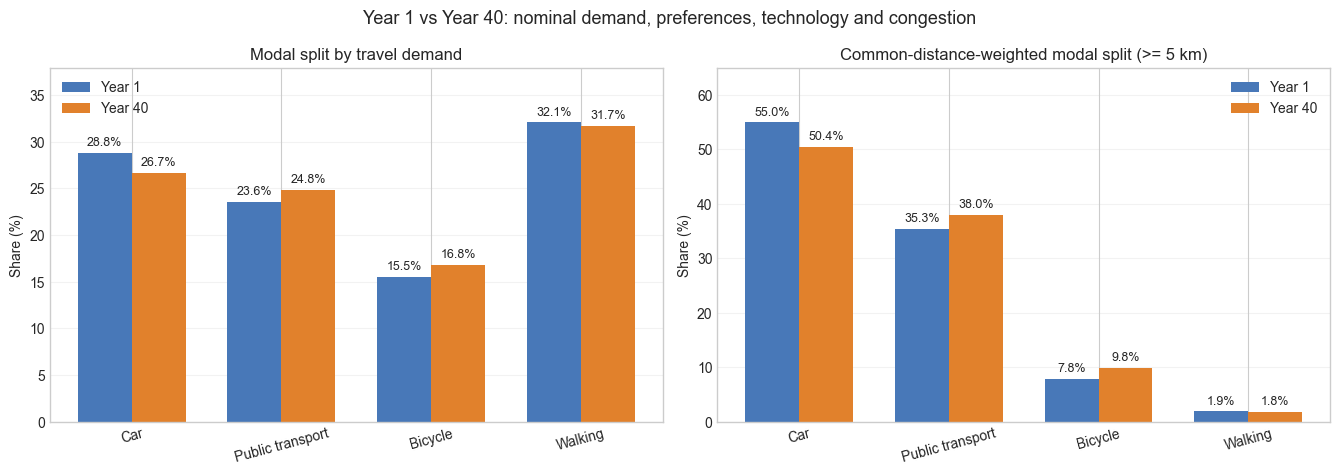

PosixPath('/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/deliverables/phase2/s1/tables/s1_7_annual_comparison.csv')

In [38]:
# The same nominal transport paths are used in every Year-40 comparison.
NOMINAL_PATHS = uc.nominal_paths()
YEAR_CASES = {"Year 1": 0, "Year 40": p.N_YEARS - 1}
# Sequential: two parallel model copies ran out of memory on a 7 GB machine.
PARALLEL_YEAR_RUNS = False
base_mode_result = res_stage0
YEAR_ASSIGNMENT_CACHE = globals().get("YEAR_ASSIGNMENT_CACHE", {})

YEAR_INPUTS = {
    label: uc.native_transport_inputs({
        key: uc.year_parameters(NOMINAL_PATHS, index)[key]
        for key in uc.TRANSPORT_BINDINGS
    })
    for label, index in YEAR_CASES.items()
}

def cache_key(label):
    return (
        id(ctx), id(FORCH), id(base_mode_result),
        tuple(sorted((key, repr(value)) for key, value in ASSIGNMENT_OPTIONS.items())),
        tuple(sorted(YEAR_INPUTS[label].items())),
    )

def compatible_baseline(assignment):
    if assignment is None or assignment.mode_result is None:
        return False
    nominal_inputs = YEAR_INPUTS["Year 1"]
    return (
        tuple(assignment.mode_result.cache_key) == (*base_mode_result.cache_key, "coupled_msa")
        and tmi.assignment_settings_match(assignment.diagnostics, ASSIGNMENT_OPTIONS,
                                         passthrough_fraction=tmi.DEFAULT_PASSTHROUGH_FRACTION)
        and np.isclose(nominal_inputs["passenger_demand_multiplier"], 1.0)
        and np.isclose(nominal_inputs["road_freight_multiplier"], 1.0)
        and np.isclose(nominal_inputs["pt_asc_shift"], 0.0)
        and np.isclose(nominal_inputs["bike_asc_shift"], 0.0)
        and np.isclose(nominal_inputs["ebike_share"], base_mode_result.scenario["ebike_share"])
    )

candidate = globals().get("coupled_assignment")
if compatible_baseline(candidate):
    YEAR_ASSIGNMENT_CACHE.setdefault(cache_key("Year 1"), candidate)

def run_case(label):
    state = tmi.acquire_native_transport_state(
        ctx, base_mode_result, stage=0,
        corridor_municipalities=corridor_municipalities,
        corridor_context=FORCH, assignment_settings=ASSIGNMENT_OPTIONS,
        **YEAR_INPUTS[label],
    )
    return label, state["assignment_result"]

missing = [label for label in YEAR_CASES if cache_key(label) not in YEAR_ASSIGNMENT_CACHE]
started = time.perf_counter()
if len(missing) > 1 and PARALLEL_YEAR_RUNS:
    n_jobs = min(len(missing), max(1, (os.cpu_count() or 2) - 1))
    new_results = Parallel(n_jobs=n_jobs, backend="loky")(delayed(run_case)(label) for label in missing)
else:
    n_jobs = 1 if missing else 0
    new_results = [run_case(label) for label in missing]
for label, assignment in new_results:
    YEAR_ASSIGNMENT_CACHE[cache_key(label)] = assignment
YEAR_ASSIGNMENTS = {label: YEAR_ASSIGNMENT_CACHE[cache_key(label)] for label in YEAR_CASES}
assignment_y1, assignment_y40 = YEAR_ASSIGNMENTS.values()
print(f"Calculated {len(missing)} missing case(s) using {n_jobs} worker(s) in {time.perf_counter() - started:.1f} s.")

# Retain numeric transport states for the later stage and plan comparisons.
YEAR_SNAPSHOTS = globals().get("YEAR_SNAPSHOTS", {})
for label, index in YEAR_CASES.items():
    year_params = uc.year_parameters(NOMINAL_PATHS, index)
    tmi.stage_year_snapshot(ctx, base_mode_result, stage_spec=stages[0],
        corridor_context=FORCH, year_idx=index,
        g_cum=float(year_params["PASSENGER_DEMAND_GROWTH"]), params=year_params,
        assignment_settings=ASSIGNMENT_OPTIONS, snapshots=YEAR_SNAPSHOTS,
        transport_state=tmi.transport_state_from_mode(
            ctx, YEAR_ASSIGNMENTS[label].mode_result, FORCH.zone_ids))

def corridor_mask(matrix):
    labels = matrix.index.astype(str).to_numpy()
    internal = np.isin(labels, np.asarray(FORCH.zone_ids, dtype=str))
    return internal[:, None] | internal[None, :]

def weighted_minutes(od, times):
    if times is None:
        return np.nan
    times = times.reindex(index=od.index, columns=od.columns)
    demand, minutes = od.to_numpy(float), times.to_numpy(float)
    valid = corridor_mask(od) & np.isfinite(demand) & np.isfinite(minutes) & (demand > 0)
    return float((demand[valid] * minutes[valid]).sum())

def pt_times(times, access):
    combined = times.get(f"pt_{access}")
    if combined is not None:
        return combined

    ivt = times.get(f"ivt_pt_{access}")
    ovt = times.get(f"ovt_pt_{access}")

    if ivt is None or ovt is None:
        return None
    return ivt + ovt

# Label follows the configured strategic distance (decision D5).
PKM_LABEL = f"PKM Share (>= {p.MIN_STRATEGIC_PKM_DISTANCE:g} km)"
MODE_ORDER = ["Car passengers", "Public Transport", "Bicycle", "Walking"]

def mode_breakdown(assignment, car_co2_kg_per_vehicle_km):
    result, od, tt = assignment.mode_result, assignment.mode_result.od_by_mode, assignment.mode_result.travel_times
    matrices = {
        "Car passengers": od["drive"],
        "Public Transport": od["pt_walk"] + od["pt_bike"],
        "Bicycle": od["bike"],
        "Walking": od["walk"],
    }
    mask = corridor_mask(od["drive"])
    trips = {
        mode: float(matrix.to_numpy(float)[mask].sum())
        for mode, matrix in matrices.items()
    }
    minutes = {
        "Car passengers": weighted_minutes(od["drive"], tt.get("drive", tt.get("car"))),
        "Public Transport": (
            weighted_minutes(od["pt_walk"], pt_times(tt, "walk"))
            + weighted_minutes(od["pt_bike"], pt_times(tt, "bike"))
        ),
        "Bicycle": weighted_minutes(od["bike"], tt.get("bike")),
        "Walking": weighted_minutes(od["walk"], tt.get("walk")),
    }
    metrics = tmi.extract_corridor_metrics(
        ctx, result, corridor_zone_ids=FORCH.zone_ids,
        p_co2_kg_per_km=float(car_co2_kg_per_vehicle_km), min_distance_km=p.MIN_STRATEGIC_PKM_DISTANCE,
    )
    shares = {
        "Car passengers": metrics["car_share"],
        "Public Transport": metrics["pt_share"],
        "Bicycle": metrics["bike_share"],
        "Walking": metrics["walk_share"],
    }
    total = sum(trips.values())
    delay = assignment.diagnostics["total_delay_hours"]
    rows = [{
        "Mode": mode,
        "Peak Trips": trips[mode],
        "Trip Share": trips[mode] / max(total, 1e-9),
        PKM_LABEL: shares[mode],
        "Mode-choice journey time": minutes[mode] / max(trips[mode], 1e-9),
        "Peak Road Congested Time (veh-h)": delay if mode == "Car passengers" else 0.0,
        "Peak Car CO2 (t)": metrics["car_co2_tonnes_peak"] if mode == "Car passengers" else 0.0,
    } for mode in MODE_ORDER]
    rows.append({
        "Mode": "--- Total / System Average ---",
        "Peak Trips": total,
        "Trip Share": 1.0,
        PKM_LABEL: 1.0,
        "Mode-choice journey time": sum(minutes.values()) / max(total, 1e-9),
        "Peak Road Congested Time (veh-h)": delay,
        "Peak Car CO2 (t)": metrics["car_co2_tonnes_peak"],
    })
    return pd.DataFrame(rows).set_index("Mode")

CAR_CO2_PATH = uc.get_trajectory("CAR_CO2_KG_PER_VEHICLE_KM")
df_y1 = mode_breakdown(assignment_y1, CAR_CO2_PATH[0])
exports.save_outputs("1_7_performance", tables={"year_1_peak": df_y1})
df_y40 = mode_breakdown(assignment_y40, CAR_CO2_PATH[-1])
exports.save_outputs("1_7_performance", tables={"year_40_peak": df_y40})

table_format = {
    "Peak Trips": "{:,.0f}",
    "Trip Share": "{:.2%}",
    PKM_LABEL: "{:.2%}",
    "Mode-choice journey time": "{:.1f} min",
    "Peak Road Congested Time (veh-h)": "{:,.1f} h",
    "Peak Car CO2 (t)": "{:,.1f} t",
}

print("Year 1: evening peak-hour results")
_display_indicators(df_y1, table_format, na_rep="-")
print("\nYear 40: evening peak-hour results")
_display_indicators(df_y40, table_format, na_rep="-")

print("\nComparison of modal split and corridor metrics between Year 1 and Year 40")
modal_comparison = pd.DataFrame({
    "Year 1 Trip Share": df_y1.loc[MODE_ORDER, "Trip Share"],
    "Year 40 Trip Share": df_y40.loc[MODE_ORDER, "Trip Share"],
    "Trip-share change (pp)": 100 * (
        df_y40.loc[MODE_ORDER, "Trip Share"] - df_y1.loc[MODE_ORDER, "Trip Share"]
    ),
    "Year 1 PKM Share": df_y1.loc[MODE_ORDER, PKM_LABEL],
    "Year 40 PKM Share": df_y40.loc[MODE_ORDER, PKM_LABEL],
    "PKM-share change (pp)": 100 * (
        df_y40.loc[MODE_ORDER, PKM_LABEL]
        - df_y1.loc[MODE_ORDER, PKM_LABEL]
    ),
})
exports.save_outputs("1_7_performance", tables={"modal_comparison": modal_comparison})
_display_indicators(modal_comparison, {
    "Year 1 Trip Share": "{:.2%}", "Year 40 Trip Share": "{:.2%}",
    "Trip-share change (pp)": "{:+.2f} pp",
    "Year 1 PKM Share": "{:.2%}", "Year 40 PKM Share": "{:.2%}",
    "PKM-share change (pp)": "{:+.2f} pp",
})

annualizers = m._annualizers(p.NOMINAL_PARAMS)
annual_factors = pd.Series({
    "Car passengers": annualizers["car"],
    "Public Transport": annualizers["pt"],
    "Bicycle": annualizers["bike"],
    "Walking": annualizers["walk"],
})
annual_trips_y1 = df_y1.loc[MODE_ORDER, "Peak Trips"] * annual_factors
annual_trips_y40 = df_y40.loc[MODE_ORDER, "Peak Trips"] * annual_factors
annual_trips_y1.loc["--- Total / System Average ---"] = annual_trips_y1.sum()
annual_trips_y40.loc["--- Total / System Average ---"] = annual_trips_y40.sum()
annual_comparison = pd.DataFrame({
    "Year 1 Annual Trips": annual_trips_y1,
    "Year 40 Annual Trips": annual_trips_y40,
    "Year 1 Avg TT": df_y1["Mode-choice journey time"],
    "Year 40 Avg TT": df_y40["Mode-choice journey time"],
    "Year 1 Annual Road Congested Time (veh-h)": df_y1["Peak Road Congested Time (veh-h)"] * annualizers["congestion"],
    "Year 40 Annual Road Congested Time (veh-h)": df_y40["Peak Road Congested Time (veh-h)"] * annualizers["congestion"],
    "Year 1 Annual Car CO2 (t)": df_y1["Peak Car CO2 (t)"] * annualizers["car"],
    "Year 40 Annual Car CO2 (t)": df_y40["Peak Car CO2 (t)"] * annualizers["car"],
})
exports.save_outputs("1_7_performance", tables={"annual_comparison": annual_comparison})
_display_indicators(annual_comparison, {
    "Year 1 Annual Trips": "{:,.0f}", "Year 40 Annual Trips": "{:,.0f}",
    "Year 1 Avg TT": "{:.1f} min", "Year 40 Avg TT": "{:.1f} min",
    "Year 1 Annual Road Congested Time (veh-h)": "{:,.0f} h",
    "Year 40 Annual Road Congested Time (veh-h)": "{:,.0f} h",
    "Year 1 Annual Car CO2 (t)": "{:,.0f} t",
    "Year 40 Annual Car CO2 (t)": "{:,.0f} t",
}, na_rep="-")

# Compare the selected modal-share indicators.
share_panels = [
    ("Trip Share", "Modal split by travel demand"),
    (PKM_LABEL, f"Common-distance-weighted modal split (>= {p.MIN_STRATEGIC_PKM_DISTANCE:g} km)"),
]
share_panels = [(c, title) for c, title in share_panels if _indicator_group(c) in PERFORMANCE_INDICATORS]
if share_panels:
    x, width = np.arange(len(MODE_ORDER)), 0.36
    labels = ["Car", "Public transport", "Bicycle", "Walking"]
    fig, axes = plt.subplots(1, len(share_panels), figsize=(6.75 * len(share_panels), 4.8), squeeze=False)
    for ax, (column, title) in zip(axes[0], share_panels):
        y1 = 100 * df_y1.loc[MODE_ORDER, column].to_numpy(float)
        y40 = 100 * df_y40.loc[MODE_ORDER, column].to_numpy(float)
        bars1 = ax.bar(x - width / 2, y1, width, label="Year 1", color="#4878b8")
        bars40 = ax.bar(x + width / 2, y40, width, label="Year 40", color="#e1812c")
        ax.bar_label(bars1, [f"{v:.1f}%" for v in y1], padding=3, fontsize=9)
        ax.bar_label(bars40, [f"{v:.1f}%" for v in y40], padding=3, fontsize=9)
        ax.set(title=title, ylabel="Share (%)", xticks=x, xticklabels=labels)
        ax.tick_params(axis="x", rotation=15)
        ax.grid(axis="y", alpha=0.25)
        ax.legend()
        ax.set_ylim(0, max(y1.max(), y40.max(), 1) * 1.18)
    fig.suptitle("Year 1 vs Year 40: nominal demand, preferences, technology and congestion", fontsize=13)
    fig.tight_layout()
    exports.save_outputs("1_7_year_comparison_modal_split", figure=fig)
    plt.show()


# Save the course tables under our names as well.
f1.save_table(df_y1.reset_index(), "s1_7_year1_peak")
f1.save_table(df_y40.reset_index(), "s1_7_year40_peak")
f1.save_table(modal_comparison.reset_index(), "s1_7_modal_comparison")
f1.save_table(annual_comparison.reset_index(), "s1_7_annual_comparison")

### The four indicators for Stage 0, Year 1 and Year 40, with units and preferred direction (mandatory)

One table with each core indicator, its unit, the Year-1 and Year-40 values, the change, which direction is better, and the Phase 1 outcome it serves (our Phase 1 §5.3 table; the group's §5.4 criteria were not available when this was written). Year 40 is a *conditional snapshot*: it shows Stage 0 under the nominal Year-40 assumptions in `parameters.py` (+20 % passenger demand, PT constant +0.10, e-bike share 0.25 -> 0.50, freight +10 %, car CO2 0.139 -> 0.050 kg/veh-km). It is not a forecast. Below it, the Forch indicators split road delay into the city part and the rest, and follow the hub area's and the Pfannenstiel's own modal split.

In [39]:
# Core indicators (course definitions) in one table, then the Forch-specific ones.
total = "--- Total / System Average ---"
core = [
    ("Mode-choice journey time", "min/trip", df_y1.loc[total, "Mode-choice journey time"], df_y40.loc[total, "Mode-choice journey time"], "lower",
     "5.3 #3 door-to-door travel time and generalised cost"),
    ("Road delay (vehicle-hours incl. background, cordon)", "veh-h/peak hour", df_y1.loc[total, "Peak Road Congested Time (veh-h)"],
     df_y40.loc[total, "Peak Road Congested Time (veh-h)"], "lower", "5.3 #5 car traffic on the Forchstrasse corridor; #3"),
    ("Car CO2", "t/peak hour", df_y1.loc[total, "Peak Car CO2 (t)"], df_y40.loc[total, "Peak Car CO2 (t)"], "lower",
     "5.3 #6 greenhouse gas emissions (operation)"),
    ("Trips (all modes)", "person trips/peak hour", df_y1.loc[total, "Peak Trips"], df_y40.loc[total, "Peak Trips"], "context (demand, not a score)",
     "5.3 #2 users (context)"),
]
for mode in MODE_ORDER:
    core.append((f"Trip share: {mode}", "share", df_y1.loc[mode, "Trip Share"], df_y40.loc[mode, "Trip Share"],
                 "higher" if mode != "Car passengers" else "lower", "5.3 #1 modal split"))
    core.append((f"{PKM_LABEL}: {mode}", "share", df_y1.loc[mode, PKM_LABEL], df_y40.loc[mode, PKM_LABEL],
                 "higher" if mode == "Public Transport" else "lower" if mode == "Car passengers" else "context", "5.3 #1 modal split"))
forch_y1 = f1.forch_indicators(ctx, assignment_y1, REGIONS)
forch_y40 = f1.forch_indicators(ctx, assignment_y40, REGIONS)
direction = lambda k: ("lower" if "delay" in k or "car trip share" in k else "higher" if "PT" in k else "context")
outcome = lambda k: ("5.3 #5 car traffic; #3" if "delay" in k else "5.3 #1 modal split of trips from the catchment" if "share" in k
                     else "5.3 #2 users of the hub (context)")
unit = lambda k: "veh-h/peak hour" if "veh-h" in k else "share" if "share" in k else "person trips/peak hour"
for key in forch_y1:
    core.append((f"Forch: {key}", unit(key), forch_y1[key], forch_y40[key], direction(key), outcome(key)))
INDICATORS_S17 = pd.DataFrame(core, columns=["indicator", "unit", "year_1", "year_40", "better", "phase1_outcome"])
INDICATORS_S17["change"] = INDICATORS_S17["year_40"] - INDICATORS_S17["year_1"]
INDICATORS_S17["change_pct"] = 100 * INDICATORS_S17["change"] / INDICATORS_S17["year_1"].abs().where(INDICATORS_S17["year_1"] != 0)
f1.save_table(INDICATORS_S17, "s1_7_indicators_stage0")
display(INDICATORS_S17.round(3))

,indicator,unit,year_1,year_40,better,phase1_outcome,change,change_pct
0,Mode-choice journey time,min/trip,21.309,21.102,lower,5.3 #3 door-to-door travel time and generalise...,-0.208,-0.974
1,"Road delay (vehicle-hours incl. background, co...",veh-h/peak hour,6012.276,7111.468,lower,5.3 #5 car traffic on the Forchstrasse corrido...,1099.193,18.282
2,Car CO2,t/peak hour,56.640,22.458,lower,5.3 #6 greenhouse gas emissions (operation),-34.182,-60.350
3,Trips (all modes),person trips/peak hour,169620.706,203544.847,"context (demand, not a score)",5.3 #2 users (context),33924.141,20.000
4,Trip share: Car passengers,share,0.288,0.267,lower,5.3 #1 modal split,-0.021,-7.329
5,PKM Share (>= 5 km): Car passengers,share,0.550,0.504,lower,5.3 #1 modal split,-0.046,-8.315
6,Trip share: Public Transport,share,0.236,0.248,higher,5.3 #1 modal split,0.012,5.294
7,PKM Share (>= 5 km): Public Transport,share,0.353,0.380,higher,5.3 #1 modal split,0.026,7.391
8,Trip share: Bicycle,share,0.155,0.168,higher,5.3 #1 modal split,0.013,8.253
9,PKM Share (>= 5 km): Bicycle,share,0.078,0.098,context,5.3 #1 modal split,0.020,25.497


**PT by access mode, Year 1 and Year 40 (decision D6).** The course's year table reports PT as one mode. This cell splits it into PT with walk access and PT with bike access for the same corridor, and checks that the PT total and the car share agree with the course table.

In [40]:
# Split PT into walk and bike access for both snapshots, then check the totals against the course table.
PT_SPLIT_S17 = f1.year_pt_split(ctx, FORCH, {"Year 1": assignment_y1, "Year 40": assignment_y40}, p.MIN_STRATEGIC_PKM_DISTANCE)
for year, table in (("Year 1", df_y1), ("Year 40", df_y40)):
    ours = PT_SPLIT_S17[PT_SPLIT_S17.year == year].set_index("mode")
    gap_pt = abs(ours.loc["PT (all)", "trip_share"] - table.loc["Public Transport", "Trip Share"])
    gap_car = abs(ours.loc["Car", "trip_share"] - table.loc["Car passengers", "Trip Share"])
    print(f"{year}: PT trip share differs from the course table by {gap_pt:.2e}, car by {gap_car:.2e}")
f1.save_table(PT_SPLIT_S17, "s1_7_pt_split")
display(PT_SPLIT_S17.pivot(index="mode", columns="year", values=["trip_share", "pkm_share"]).round(4))

Year 1: PT trip share differs from the course table by 0.00e+00, car by 0.00e+00
Year 40: PT trip share differs from the course table by 0.00e+00, car by 0.00e+00


trip_share         pkm_share        
year         Year 1 Year 40    Year 1 Year 40
mode                                         
Bike         0.1554  0.1682    0.0784  0.0984
Car          0.2881  0.2670    0.5495  0.5038
PT (all)     0.2356  0.2481    0.3534  0.3795
PT-bike      0.0667  0.0727    0.1329  0.1488
PT-walk      0.1690  0.1754    0.2205  0.2308
Total        1.0000  1.0000    1.0000  1.0000
Walk         0.3209  0.3167    0.0187  0.0183

## Summary: what Part 1 delivers for Forch (Sheet 2 §5 items 1-6)

| Sheet 2 §5 item | Where it is |
|---|---|
| 1. System boundary, four-step structure, calculation chain, limitations | Section 1.1; `figures/s1_1_model_loop.png`; `S1_report_full.md` |
| 2. Input preflight | Section 1.2; `tables/s1_2_preflight.csv` |
| 3. Validated baseline OD matrix and desire lines (internal, inbound, outbound, pass-through) | Section 1.4; `tables/s1_4_*.csv`; `figures/s1_4_*.png`; `S1_validation.md` |
| 4. Validated Stage-0 modal split by trips and PKM, with OD relations | Section 1.5; `tables/s1_5_*.csv`; `figures/s1_5_*.png`; `S1_validation.md` |
| 5. Coupled Stage-0 assignment compared with fixed demand, with convergence | Section 1.6; `tables/s1_6_*.csv`; `figures/s1_6_*.png` |
| 6. Four indicators for Stage 0, Year 1 and Year 40, with units and preferred direction | Section 1.7; `tables/s1_7_indicators_stage0.csv` |

All paths are under `deliverables/phase2/s1/`.

# Part 2 — Model Parameters & System Dynamics

Now that we have established our performance indicators, we examine **what drives them**.

The system is governed by three levels of input:

1. **Demand dynamics** (`code/parameters.py`): how much travel grows by Year 40 (`PASSENGER_DEMAND_GROWTH_Y40`), including the planning horizon and success thresholds.
2. **Mode preferences**: how attractive each mode is. Baseline coefficients (ASCs, time/cost betas, fares) are in `data/transport/config/mode_choice.json`. The Year-40 PT preference shift (`PT_ASC_SHIFT_Y40`) is in `code/parameters.py`. Baseline e-bike share and speed are also in `code/parameters.py`.
3. **Network and service attributes**: percentage changes to PT in-vehicle time, waiting, transfers, access, and egress on selected OD pairs. These encode infrastructure and service packages in `code/stages.py`. You set Stage 1 / Stage 2 values in Part 3.

**2.1** lists current values, grouped according to the 3 levels above. **2.2–2.3** allow an exploration of a subset of the parameters with sliders at **Stage 0**: demand growth, PT preference and e-bikes, and the PT time/quality `%` adjustments.


| Input level | Parameter | Value |
|---|---|---|
| Demand dynamics | `PASSENGER_DEMAND_GROWTH_Y40` | 0.20 |
| | Appraisal horizon `N_YEARS` | 40 |
| | Appraisal threshold `PT_SHARE_TARGET` | 0.35 |
| Mode preference (baseline) | `ASC_CAR` | 0.5 |
| | `ASC_WALK` | 2.4 |
| | `ASC_BIKE` | -0.1 |
| | `ASC_PT_WALK` | 0.0 |
| | `ASC_PT_BIKE` | -1.5 |
| | `B_CAR_TIME` | -0.075 |
| | `B_WALK_TIME` | -0.10 |
| | `B_BIKE_TIME` | -0.10 |
| | `B_PT_IVT` | -0.045 |
| | `B_PT_OVT` | -0.08 |
| | `B_COST` | -0.18 |
| | `B_PT_FARE` | -0.18 |
| | `B_TRANSFER` | -0.43 |
| | `CAR_COST_CHF_PER_KM` | 0.27 |
| | `PT_MIN_FARE_CHF` | 3.0 |
| | `PT_FARE_CHF_PER_KM` | 0.08 |
| | `PT_MAX_FARE_CHF` | 8.0 |
| | `EBIKE_SHARE`| 0.25 | 
| Mode preference shift (Y40)| `PT_ASC_SHIFT_Y40` | 0.10 |
| | `BIKE_ASC_SHIFT_Y40` (deactivated by default) | 0.20 |
| | `EBIKE_SHARE_Y40 `| 0.50 |

<br>

> **Coupled MSA.** The parameter playground runs mode choice and road assignment together. Each selected setting is compared with a nominal run, with completed calculations cached.

### 2.1 Core Parameter Overview (mandatory task)

Look at the tables below. You will eventually have to select and adapt some of the values to your own case study through the semester. The overview shows which assumptions feed the transport model, the physical indicators, and the later evaluation.

| Table | Level | Contents | File | 
|---|---|---|---|
| 1 | Demand dynamics | Horizon, demand growth, success thresholds | `code/parameters.py` |
| 2 | Mode preferences | Year-40 PT preference shift and baseline e-bikes | `code/parameters.py` |
| 3 | Mode preferences | Baseline ASCs, time/cost betas, fares | `data/transport/config/mode_choice.json` |
| 4–5 | Outcome evaluation | Appraisal monetary values, peak hours, discount factor | `code/parameters.py` |
| 6 | Network and service | PT time/capacity `%` improvements | `code/stages.py` |


In [41]:
import re


def _src(file, key):
    """Link to the line where `key` is defined in code/<file> (file-level link if not found)."""
    lines = (CODE_DIR / file).read_text(encoding="utf-8").splitlines()
    pattern = re.compile(rf'^\s*(?:"{key}"\s*:|{key}\s*=)')
    line = next((i for i, text in enumerate(lines, 1) if pattern.match(text)), None)
    anchor = f"#L{line}" if line else ""
    return f'<a href="../code/{file}{anchor}">{file}</a>'


def _transport_src(file):
    base = "../data/transport" if file.startswith("config/") else "../code/transport_core"
    return f'<a href="{base}/{file}">{file}</a>'


def _show(name, title, rows):
    columns = [
        "Parameter", "Where it is", "Definition", "Baseline Value",
        "Unit", "Spatial Scope", "Direct System Impact",
    ]
    table = pd.DataFrame(rows, columns=columns)
    exports.save_outputs(name, tables={"": table})
    f1.save_table(table, name)  # Save under our own name as well.
    display(HTML(f"<h4>{title}</h4>"))
    display(HTML(table.to_html(escape=False, index=False)))
    return table


stage0 = stages_module.get_stages(p.NOMINAL_PARAMS)[0]

# 1. Macro demand and planning horizon.
demand_rows = [
    ("N_YEARS", _src("parameters.py", "N_YEARS"), "Planning horizon", f"{p.N_YEARS}", "years", "Global", "Length of Year 1 → Year 40 comparison"),
    ("PASSENGER_DEMAND_GROWTH_Y40", _src("parameters.py", "PASSENGER_DEMAND_GROWTH_Y40"), "Total corridor demand growth by Year 40", f"{p.PASSENGER_DEMAND_GROWTH_Y40:.0%}", "fraction", "All 1,223 Canton Zürich zones", "Drives Year 40 traffic volume and congestion"),
    ("MAX_AVG_TT", _src("parameters.py", "MAX_AVG_TT"), "Maximum acceptable average motorized travel time", f"{p.MAX_AVG_TT:.0f}", "minutes", "Corridor-wide", "Acceptability / success threshold"),
    ("PT_SHARE_TARGET", _src("parameters.py", "PT_SHARE_TARGET"), "Target PT modal split", f"{p.PT_SHARE_TARGET:.0%}", "fraction", "Corridor-wide", "Acceptability / success threshold"),
]
demand_df = _show("2_1_demand_dynamics", "1. Demand dynamics (parameters.py)", demand_rows)

# 2. Mode preferences: Year-40 PT shift and Stage 0 e-bikes.
behavior_rows = [
    ("PT_ASC_SHIFT_Y40", _src("parameters.py", "PT_ASC_SHIFT_Y40"), "Common additive shift to both PT ASCs by Year 40", f"{p.PT_ASC_SHIFT_Y40:g}", "utility", "All PT alternatives", "Year-40 PT preference"),
    ("EBIKE_SHARE", _src("parameters.py", "EBIKE_SHARE"), "Share of bicycles that are e-bikes", f"{p.EBIKE_SHARE:.0%}", "fraction", "All corridor travel demand", "Raises effective average bicycle speed"),
    ("EBIKE_SPEED_MULTIPLIER", _src("parameters.py", "EBIKE_SPEED_MULTIPLIER"), "Speed advantage of e-bikes over conventional bicycles", f"{stage0['EBIKE_SPEED_MULTIPLIER']:.1f}x", "multiplier", "All corridor travel demand", "Raises effective average bicycle speed"),
]
behavior_df = _show("2_1_mode_preferences", "2. Mode preferences — Year-40 PT shift and Stage 0 e-bikes", behavior_rows)

# 3. Native FSM utility, time, and cost coefficients.
mode_choice_baseline = ctx.modules["mode_choice_zurich"].load_mode_choice_parameters()

mode_choice_rows = [
    ("ASC_CAR", _transport_src("config/mode_choice.json"), "Base preference for car, independent of time and cost", f"{mode_choice_baseline['ASC_CAR']:g}", "utility", "All mode-choice segments", "Sets baseline logit utility"),
    ("ASC_WALK", _transport_src("config/mode_choice.json"), "Base preference for walking", f"{mode_choice_baseline['ASC_WALK']:g}", "utility", "All mode-choice segments", "Sets baseline logit utility"),
    ("ASC_BIKE", _transport_src("config/mode_choice.json"), "Base preference for bicycle", f"{mode_choice_baseline['ASC_BIKE']:g}", "utility", "All mode-choice segments", "Sets baseline logit utility"),
    ("ASC_PT_WALK", _transport_src("config/mode_choice.json"), "Base preference for PT accessed by walking", f"{mode_choice_baseline['ASC_PT_WALK']:g}", "utility", "All mode-choice segments", "Sets baseline logit utility"),
    ("ASC_PT_BIKE", _transport_src("config/mode_choice.json"), "Base preference for PT accessed by bicycle", f"{mode_choice_baseline['ASC_PT_BIKE']:g}", "utility", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_CAR_TIME", _transport_src("config/mode_choice.json"), "Utility penalty per minute of car travel time", f"{mode_choice_baseline['B_CAR_TIME']:g}", "utility/min", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_WALK_TIME", _transport_src("config/mode_choice.json"), "Utility penalty per minute of walking time", f"{mode_choice_baseline['B_WALK_TIME']:g}", "utility/min", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_BIKE_TIME", _transport_src("config/mode_choice.json"), "Utility penalty per minute of bicycle time", f"{mode_choice_baseline['B_BIKE_TIME']:g}", "utility/min", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_PT_IVT", _transport_src("config/mode_choice.json"), "Utility penalty per minute of PT in-vehicle time", f"{mode_choice_baseline['B_PT_IVT']:g}", "utility/min", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_PT_OVT", _transport_src("config/mode_choice.json"), "Utility penalty per minute of PT out-of-vehicle time", f"{mode_choice_baseline['B_PT_OVT']:g}", "utility/min", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_TRANSFER", _transport_src("config/mode_choice.json"), "Utility penalty per PT transfer", f"{mode_choice_baseline['B_TRANSFER']:g}", "utility/transfer", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_COST", _transport_src("config/mode_choice.json"), "Utility penalty per CHF of car cost", f"{mode_choice_baseline['B_COST']:g}", "utility/CHF", "All mode-choice segments", "Sets baseline logit utility"),
    ("B_PT_FARE", _transport_src("config/mode_choice.json"), "Utility penalty per CHF of PT fare", f"{mode_choice_baseline['B_PT_FARE']:g}", "utility/CHF", "All mode-choice segments", "Sets baseline logit utility"),
    ("CAR_COST_CHF_PER_KM", _transport_src("config/mode_choice.json"), "Car operating cost", f"{mode_choice_baseline['CAR_COST_CHF_PER_KM']:g}", "CHF/km", "All corridor travel demand", "Sets baseline car cost"),
    ("PT_MIN_FARE_CHF", _transport_src("config/mode_choice.json"), "Minimum PT fare", f"{mode_choice_baseline['PT_MIN_FARE_CHF']:g}", "CHF", "All corridor travel demand", "Sets baseline PT fare floor"),
    ("PT_FARE_CHF_PER_KM", _transport_src("config/mode_choice.json"), "PT distance-based fare", f"{mode_choice_baseline['PT_FARE_CHF_PER_KM']:g}", "CHF/km", "All corridor travel demand", "Sets baseline PT fare"),
    ("PT_MAX_FARE_CHF", _transport_src("config/mode_choice.json"), "Maximum PT fare", f"{mode_choice_baseline['PT_MAX_FARE_CHF']:g}", "CHF", "All corridor travel demand", "Sets baseline PT fare ceiling"),
]
mode_choice_df = _show("2_1_baseline_coefficients", "3. Mode preferences — baseline coefficients (mode_choice.json)", mode_choice_rows)

# 4. Economic and environmental valuation.
# General values are defined in NOMINAL_PARAMS in parameters.py.
econ_rows = [
    ("DISCOUNT_RATE", _src("parameters.py", "DISCOUNT_RATE"), "Social discount rate", f"{p.DISCOUNT_RATE:.1%}", "fraction", "Corridor-wide CBA", "Discounts future costs and benefits to present value"),
    ("CAR_CO2_KG_PER_VEHICLE_KM", _src("parameters.py", "CAR_CO2_KG_PER_VEHICLE_KM"), "Car fleet emission factor", f"{p.CAR_CO2_KG_PER_VEHICLE_KM:.3f}", "kg CO₂/vehicle-km", "Car travel", "Converts vehicle-km to physical emissions"),
    ("CO2_VALUE_CHF_PER_TONNE", _src("parameters.py", "CO2_VALUE_CHF_PER_TONNE"), "Carbon value in reference year", f"{p.CO2_VALUE_CHF_PER_TONNE:.1f}", "CHF/tonne CO₂", "Car and rail", "Values each mode at the same carbon price"),
    ("CO2_REFERENCE_YEAR", _src("parameters.py", "CO2_REFERENCE_YEAR"), "Carbon valuation reference year", f"{p.CO2_REFERENCE_YEAR:g}", "calendar year", "Car and rail", "Starting year for carbon-price escalation"),
    ("CO2_VALUE_ANNUAL_GROWTH", _src("parameters.py", "CO2_VALUE_ANNUAL_GROWTH"), "Annual carbon-price growth", f"{p.CO2_VALUE_ANNUAL_GROWTH:.1%}", "fraction/year", "Car and rail", "Compounds the carbon value by calendar year"),
    ("APPRAISAL_START_YEAR", _src("parameters.py", "APPRAISAL_START_YEAR"), "Calendar year of appraisal Year 1", f"{p.APPRAISAL_START_YEAR:g}", "calendar year", "Corridor-wide CBA", "Aligns annual carbon values with the appraisal horizon"),
    ("C_TT_CAR", _src("parameters.py", "C_TT_CAR"), "Value of car travel time", f"{p.C_TT_CAR:.1f}", "CHF/h", "Car travel demand", "Monetizes car travel-time savings"),
    ("C_TT_PT", _src("parameters.py", "C_TT_PT"), "Value of in-vehicle PT travel time", f"{p.C_TT_PT:.2f}", "CHF/person-hour", "PT passengers", "Monetizes PT in-vehicle time savings"),
    ("C_TT_PT_WAITING", _src("parameters.py", "C_TT_PT_WAITING"), "Value of PT waiting time", f"{p.C_TT_PT_WAITING:.2f}", "CHF/person-hour", "PT passengers", "Values initial and transfer waiting"),
    ("C_TT_PT_ACCESS", _src("parameters.py", "C_TT_PT_ACCESS"), "Value of station access and egress", f"{p.C_TT_PT_ACCESS:.2f}", "CHF/person-hour", "PT passengers", "Values access and egress time"),
    ("C_TT_PT_TRANSFER", _src("parameters.py", "C_TT_PT_TRANSFER"), "Value of transfer walking", f"{p.C_TT_PT_TRANSFER:.2f}", "CHF/person-hour", "PT passengers", "Values walking between services"),
]
econ_df = _show("2_1_appraisal_prices", "4. Later evaluation — appraisal prices (parameters.py)", econ_rows)
# 5. Fixed physical and engineering assumptions.
fixed_rows = [
    ("RAIL_ENERGY_WH_PER_GROSS_TONNE_KM", _src("parameters.py", "RAIL_ENERGY_WH_PER_GROSS_TONNE_KM"), "Rail traction energy intensity", f"{p.RAIL_ENERGY_WH_PER_GROSS_TONNE_KM:g}", "Wh/gross tonne-km", "Train services", "Converts supplied train movement and mass to electricity use"),
    ("RAIL_ELECTRICITY_CO2_G_PER_KWH", _src("parameters.py", "RAIL_ELECTRICITY_CO2_G_PER_KWH"), "Rail electricity emission factor", f"{p.RAIL_ELECTRICITY_CO2_G_PER_KWH:.2f}", "g CO₂/kWh", "Train services", "Converts rail electricity use to physical emissions"),
    ("PT_PEAK_SHARE", _src("parameters.py", "PT_PEAK_SHARE"), "PT peak-hour share of weekday trips", f"{p.PT_PEAK_SHARE:.2%}", "fraction", "PT travel demand", "Converts PT peak trips to daily trips"),
    ("CAR_PEAK_SHARE", _src("parameters.py", "CAR_PEAK_SHARE"), "Car peak-hour share of weekday trips", f"{p.CAR_PEAK_SHARE:.2%}", "fraction", "Car travel demand", "Converts car peak trips to daily trips"),
    ("EQUIVALENT_DAYS_PER_YEAR", _src("parameters.py", "EQUIVALENT_DAYS_PER_YEAR"), "Equivalent operating days per year", f"{p.EQUIVALENT_DAYS_PER_YEAR:g}", "days/year", "All modes", "Converts daily flows to annual flows"),
    ("NUMBER_OF_PEAK_HOURS", _src("parameters.py", "NUMBER_OF_PEAK_HOURS"), "Hours with peak congestion and crowding", f"{p.NUMBER_OF_PEAK_HOURS:g}", "hours/day", "Road and PT", "Sets annual exposure to peak delays"),
    ("PT_HEADWAY_BASELINE", _src("parameters.py", "PT_HEADWAY_BASELINE"), "Baseline interval between PT services", f"{stages_module.stage_headway(0, p.NOMINAL_PARAMS):.0f}", "minutes", "Selected rail service", "Reference for frequency and waiting-time changes"),
    ("PT_CAPACITY_BASELINE", _src("parameters.py", "PT_CAPACITY_BASELINE"), "Baseline section comfort threshold", f"{stages_module.stage_capacity(0, p.NOMINAL_PARAMS):,.0f}", "persons/peak hour", "Counting section", "Reference for excess crowding penalties"),
    ("C_NOISE_CAR", _src("parameters.py", "C_NOISE_CAR"), "Noise external cost, car", f"{p.C_NOISE_CAR:.3f}", "CHF/veh-km", "Road network", "NIBA external cost of car travel"),
    ("C_AIR_CAR", _src("parameters.py", "C_AIR_CAR"), "Air-pollution external cost, car", f"{p.C_AIR_CAR:.3f}", "CHF/veh-km", "Road network", "NIBA external cost of car travel"),
    ("C_ACCIDENT_CAR", _src("parameters.py", "C_ACCIDENT_CAR"), "Accident external cost, car", f"{p.C_ACCIDENT_CAR:.3f}", "CHF/veh-km", "Road network", "NIBA external cost of car travel"),
]
fixed_df = _show("2_1_physical_assumptions", "5. Later evaluation — daily conversion, PT service and comfort threshold, NIBA costs", fixed_rows)

# 6. Network and service attributes (Stage 0 baseline = 0%).
intervention_rows = [
    ("travel_time_reduction_pct", _transport_src("interventions.py"), "PT in-vehicle time reduction", "0%", "%", "Targeted OD pairs (e.g. Zürich ↔ Winterthur)", "Shortens PT in-vehicle time"),
    ("speed_increase_pct", _transport_src("interventions.py"), "Operating speed increase", "0%", "%", "Selected bicycle or PT OD pairs", "Reduces travel time on those OD pairs"),
    ("distance_reduction_pct", _transport_src("interventions.py"), "Path-distance / shortcut reduction", "0%", "%", "Selected OD pairs with shorter modeled paths", "Shortens the modelled path"),
    ("initial_wait_reduction_pct", _transport_src("interventions.py"), "Initial waiting-time reduction", "0%", "%", "Corridor rail lines and connecting bus feeders", "Shortens first-board waiting time"),
    ("transfer_wait_reduction_pct", _transport_src("interventions.py"), "Transfer waiting-time reduction (timetable coordination)", "0%", "%", "Transfer hubs (e.g. Winterthur HB, Stadelhofen)", "Shortens wait at transfers"),
    ("transfer_time_reduction_pct", _transport_src("interventions.py"), "Physical transfer-time reduction (platform walking)", "0%", "%", "Upgraded interchange station facilities", "Shortens walk between platforms"),
    ("access_time_reduction_pct", _transport_src("interventions.py"), "First-mile station access-time reduction", "0%", "%", "Station catchment (walk/bicycle radius)", "Shortens access to the station"),
    ("egress_time_reduction_pct", _transport_src("interventions.py"), "Last-mile station egress-time reduction", "0%", "%", "Destination municipal employment zones", "Shortens egress from the station"),
]
intervention_df = _show(
    "2_1_network_service_attributes",
    "6. Network and service attributes (Stage 0 = 0%; Stage 1–2 in Part 3)",
    intervention_rows,
)

print("* Baseline values are loaded directly from data/transport/config/mode_choice.json.")
print("* Table 6 is the Stage 0 baseline (0%). Part 3 sets the Stage 1–2 values.")


Parameter,Where it is,Definition,Baseline Value,Unit,Spatial Scope,Direct System Impact
N_YEARS,parameters.py,Planning horizon,40,years,Global,Length of Year 1 → Year 40 comparison
PASSENGER_DEMAND_GROWTH_Y40,parameters.py,Total corridor demand growth by Year 40,20%,fraction,"All 1,223 Canton Zürich zones",Drives Year 40 traffic volume and congestion
MAX_AVG_TT,parameters.py,Maximum acceptable average motorized travel time,15,minutes,Corridor-wide,Acceptability / success threshold
PT_SHARE_TARGET,parameters.py,Target PT modal split,35%,fraction,Corridor-wide,Acceptability / success threshold


Parameter,Where it is,Definition,Baseline Value,Unit,Spatial Scope,Direct System Impact
PT_ASC_SHIFT_Y40,parameters.py,Common additive shift to both PT ASCs by Year 40,0.1,utility,All PT alternatives,Year-40 PT preference
EBIKE_SHARE,parameters.py,Share of bicycles that are e-bikes,25%,fraction,All corridor travel demand,Raises effective average bicycle speed
EBIKE_SPEED_MULTIPLIER,parameters.py,Speed advantage of e-bikes over conventional bicycles,1.5x,multiplier,All corridor travel demand,Raises effective average bicycle speed


Parameter,Where it is,Definition,Baseline Value,Unit,Spatial Scope,Direct System Impact
ASC_CAR,config/mode_choice.json,"Base preference for car, independent of time and cost",0.5,utility,All mode-choice segments,Sets baseline logit utility
ASC_WALK,config/mode_choice.json,Base preference for walking,2.4,utility,All mode-choice segments,Sets baseline logit utility
ASC_BIKE,config/mode_choice.json,Base preference for bicycle,-0.1,utility,All mode-choice segments,Sets baseline logit utility
ASC_PT_WALK,config/mode_choice.json,Base preference for PT accessed by walking,0,utility,All mode-choice segments,Sets baseline logit utility
ASC_PT_BIKE,config/mode_choice.json,Base preference for PT accessed by bicycle,-1.5,utility,All mode-choice segments,Sets baseline logit utility
B_CAR_TIME,config/mode_choice.json,Utility penalty per minute of car travel time,-0.075,utility/min,All mode-choice segments,Sets baseline logit utility
B_WALK_TIME,config/mode_choice.json,Utility penalty per minute of walking time,-0.1,utility/min,All mode-choice segments,Sets baseline logit utility
B_BIKE_TIME,config/mode_choice.json,Utility penalty per minute of bicycle time,-0.1,utility/min,All mode-choice segments,Sets baseline logit utility
B_PT_IVT,config/mode_choice.json,Utility penalty per minute of PT in-vehicle time,-0.045,utility/min,All mode-choice segments,Sets baseline logit utility
B_PT_OVT,config/mode_choice.json,Utility penalty per minute of PT out-of-vehicle time,-0.08,utility/min,All mode-choice segments,Sets baseline logit utility


Parameter,Where it is,Definition,Baseline Value,Unit,Spatial Scope,Direct System Impact
DISCOUNT_RATE,parameters.py,Social discount rate,2.0%,fraction,Corridor-wide CBA,Discounts future costs and benefits to present value
CAR_CO2_KG_PER_VEHICLE_KM,parameters.py,Car fleet emission factor,0.139,kg CO₂/vehicle-km,Car travel,Converts vehicle-km to physical emissions
CO2_VALUE_CHF_PER_TONNE,parameters.py,Carbon value in reference year,123.2,CHF/tonne CO₂,Car and rail,Values each mode at the same carbon price
CO2_REFERENCE_YEAR,parameters.py,Carbon valuation reference year,2015,calendar year,Car and rail,Starting year for carbon-price escalation
CO2_VALUE_ANNUAL_GROWTH,parameters.py,Annual carbon-price growth,3.0%,fraction/year,Car and rail,Compounds the carbon value by calendar year
APPRAISAL_START_YEAR,parameters.py,Calendar year of appraisal Year 1,2026,calendar year,Corridor-wide CBA,Aligns annual carbon values with the appraisal horizon
C_TT_CAR,parameters.py,Value of car travel time,42.5,CHF/h,Car travel demand,Monetizes car travel-time savings
C_TT_PT,parameters.py,Value of in-vehicle PT travel time,26.52,CHF/person-hour,PT passengers,Monetizes PT in-vehicle time savings
C_TT_PT_WAITING,parameters.py,Value of PT waiting time,26.52,CHF/person-hour,PT passengers,Values initial and transfer waiting
C_TT_PT_ACCESS,parameters.py,Value of station access and egress,26.52,CHF/person-hour,PT passengers,Values access and egress time


Parameter,Where it is,Definition,Baseline Value,Unit,Spatial Scope,Direct System Impact
RAIL_ENERGY_WH_PER_GROSS_TONNE_KM,parameters.py,Rail traction energy intensity,30,Wh/gross tonne-km,Train services,Converts supplied train movement and mass to electricity use
RAIL_ELECTRICITY_CO2_G_PER_KWH,parameters.py,Rail electricity emission factor,19.58,g CO₂/kWh,Train services,Converts rail electricity use to physical emissions
PT_PEAK_SHARE,parameters.py,PT peak-hour share of weekday trips,9.46%,fraction,PT travel demand,Converts PT peak trips to daily trips
CAR_PEAK_SHARE,parameters.py,Car peak-hour share of weekday trips,10.49%,fraction,Car travel demand,Converts car peak trips to daily trips
EQUIVALENT_DAYS_PER_YEAR,parameters.py,Equivalent operating days per year,300,days/year,All modes,Converts daily flows to annual flows
NUMBER_OF_PEAK_HOURS,parameters.py,Hours with peak congestion and crowding,4,hours/day,Road and PT,Sets annual exposure to peak delays
PT_HEADWAY_BASELINE,parameters.py,Baseline interval between PT services,20,minutes,Selected rail service,Reference for frequency and waiting-time changes
PT_CAPACITY_BASELINE,parameters.py,Baseline section comfort threshold,"11,352",persons/peak hour,Counting section,Reference for excess crowding penalties
C_NOISE_CAR,parameters.py,"Noise external cost, car",0.015,CHF/veh-km,Road network,NIBA external cost of car travel
C_AIR_CAR,parameters.py,"Air-pollution external cost, car",0.019,CHF/veh-km,Road network,NIBA external cost of car travel


Parameter,Where it is,Definition,Baseline Value,Unit,Spatial Scope,Direct System Impact
travel_time_reduction_pct,interventions.py,PT in-vehicle time reduction,0%,%,Targeted OD pairs (e.g. Zürich ↔ Winterthur),Shortens PT in-vehicle time
speed_increase_pct,interventions.py,Operating speed increase,0%,%,Selected bicycle or PT OD pairs,Reduces travel time on those OD pairs
distance_reduction_pct,interventions.py,Path-distance / shortcut reduction,0%,%,Selected OD pairs with shorter modeled paths,Shortens the modelled path
initial_wait_reduction_pct,interventions.py,Initial waiting-time reduction,0%,%,Corridor rail lines and connecting bus feeders,Shortens first-board waiting time
transfer_wait_reduction_pct,interventions.py,Transfer waiting-time reduction (timetable coordination),0%,%,"Transfer hubs (e.g. Winterthur HB, Stadelhofen)",Shortens wait at transfers
transfer_time_reduction_pct,interventions.py,Physical transfer-time reduction (platform walking),0%,%,Upgraded interchange station facilities,Shortens walk between platforms
access_time_reduction_pct,interventions.py,First-mile station access-time reduction,0%,%,Station catchment (walk/bicycle radius),Shortens access to the station
egress_time_reduction_pct,interventions.py,Last-mile station egress-time reduction,0%,%,Destination municipal employment zones,Shortens egress from the station


* Baseline values are loaded directly from data/transport/config/mode_choice.json.
* Table 6 is the Stage 0 baseline (0%). Part 3 sets the Stage 1–2 values.


### 2.2 Parameter Playground — Year 1 vs. Year 40 (tutorial/supporting task)

Use the sliders to see how the **three levels** in 2.1 play out from **Year 1** to **Year 40** on the **current network (Stage 0)**.

- **Demand** (`PASSENGER_DEMAND_GROWTH_Y40`) — cumulative travel demand by Year 40. Year 1 stays at today’s demand. As roads near capacity, Year 40 congested time can rise sharply.
- **Preferences and cycling technology** (`PT_ASC_SHIFT_Y40`, `EBIKE_SHARE`) — a stronger PT preference, or faster cycling, shifts travel off the car, which lowers $\text{CO}_2$ and can ease road congestion.
- **Network and service** (the six PT `%` cuts: in-vehicle time, initial wait, transfer wait, transfer walk, access, egress) — shorter PT times also shift mode shares.

**Interaction:** the same demand growth produces more delay when car stays attractive than when PT preference or PT quality improves.

Choose tab names and supported controls in `PLAYGROUND_TABS` below. Expand **Supported controls** to see the available keys. Omitted controls keep their nominal values; configuration errors appear above the tabs. Use **Run coupled MSA** to calculate the selected settings. Save Stage 1 / Stage 2 packages in Part 3.

The e-bike-share slider sets the Year-40 share; Year 1 retains the configured baseline share. Other nominal transport paths come from `parameters.py`.


In [42]:
# Choose the tabs and controls; supported keys are listed in the dashboard.
PLAYGROUND_TABS = {
    "Demand": ["PASSENGER_DEMAND_GROWTH_Y40"],
    "Mode preferences": ["PT_ASC_SHIFT_Y40"],
    "Cycling": ["EBIKE_SHARE"],
    "PT infrastructure and service": [
        "travel_time_reduction_pct", "initial_wait_reduction_pct",
        "transfer_wait_reduction_pct", "transfer_time_reduction_pct",
        "access_time_reduction_pct", "egress_time_reduction_pct",
    ],
}

PARAMETER_STAGE_SPECS = stages_module.get_stages(p.NOMINAL_PARAMS)

if callable(globals().get("PARAMETER_STATE", {}).get("close")):
    PARAMETER_STATE["close"]()

PARAMETER_UI, PARAMETER_STATE = tmi.parameter_playground_dashboard(
    ctx,
    PARAMETER_STAGE_SPECS,
    corridor_zone_ids=corridor_zones,
    corridor_municipalities=p.CORRIDOR_MUNICIPALITIES,
    demand_growth_y40=p.PASSENGER_DEMAND_GROWTH_Y40,
    simulation_params=p.NOMINAL_PARAMS,
    reference_mode_result=res_stage0,
    reference_year_assignments=YEAR_ASSIGNMENTS,
    control_groups=PLAYGROUND_TABS,
)

display(PARAMETER_UI)


## 2.3 Sensitivity dashboard (tutorial/supporting task)

The following cell runs a one-at-a-time sensitivity sweep of the Section 2.2 Stage 0 controls: each parameter is varied while the others stay at their defaults, and the figures show how Year-40 indicators respond.

- **Demand:** `PASSENGER_DEMAND_GROWTH_Y40`
- **Mode preferences:** `PT_ASC_SHIFT_Y40`, `EBIKE_SHARE`, `EBIKE_SPEED_MULTIPLIER`
- **Network and service:** `travel_time_reduction_pct`, `initial_wait_reduction_pct`, `transfer_wait_reduction_pct`, `transfer_time_reduction_pct`, `access_time_reduction_pct`, `egress_time_reduction_pct`

**What you get**

1. A **heatmap** — each cell is the largest relative change of one indicator when that slider is moved over its range. Darker means a stronger response. Rows include the Part 1 indicators (`avg_travel_time_min`, `congestion_delay_hours`, `co2_tonnes`, `total_demand`) plus modal shares and car-km.
2. A **dropdown** — pick one slider to see Year-40 curves versus that slider. The dotted line is the default value.

### What to look for

1. **Steep vs flat** — which indicators respond most strongly to each slider.
2. **Demand growth** — `PASSENGER_DEMAND_GROWTH_Y40` changes final-year travel demand and congestion.
3. **Mode-choice levers** — `PT_ASC_SHIFT_Y40`, e-bikes, and the PT `%` cuts change modal split, travel time, and $\text{CO}_2$.
4. **Curves** — near capacity, extra demand can raise delay faster than proportionally.
5. **What to document** — large heatmap cells are assumptions to source.

The sweep runs coupled mode choice and road assignment at Year 40, reusing the prepared corridor and matching nominal result. Independent points are distributed across `SWEEP_WORKERS`; completed-point messages show progress and convergence. Set `RUN_PARAMETER_SWEEP = True` to run this optional analysis. Allow tens of minutes for a multi-parameter sweep. Results remain in `SWEEP_RESULTS` for plotting.


In [43]:
RUN_PARAMETER_SWEEP = False  # Optional native calculations; allow tens of minutes.
SWEEP_WORKERS = 4

if RUN_PARAMETER_SWEEP:
    
    SWEEP_PARAMETERS = [
        "PASSENGER_DEMAND_GROWTH_Y40",
        "PT_ASC_SHIFT_Y40",
        "EBIKE_SHARE",
        "travel_time_reduction_pct",
        #"initial_wait_reduction_pct",
        #"transfer_wait_reduction_pct",
        #"transfer_time_reduction_pct",
        #"access_time_reduction_pct",
        #"egress_time_reduction_pct",
    ]

    REFERENCE_MODE_RESULT = res_stage0

    SWEEP_RESULTS = tmi.parameter_objective_sweeps(
        ctx,
        PARAMETER_STAGE_SPECS,
        SWEEP_PARAMETERS,
        corridor_zone_ids=corridor_zones,
        corridor_municipalities=p.CORRIDOR_MUNICIPALITIES,
        slider_specs=PARAMETER_STATE["slider_specs"],
        n_points=5,
        simulation_params=p.NOMINAL_PARAMS,
        assignment_method="MSA",
        reference_mode_result=REFERENCE_MODE_RESULT,
        corridor_context=MEHRSPUR,
        precomputed_year_assignments=YEAR_ASSIGNMENTS,
        simulation_assignment_settings=ASSIGNMENT_OPTIONS,
        n_jobs=SWEEP_WORKERS,
    )

    SWEEP_UI = tmi.plot_parameter_objective_sweeps(
        SWEEP_RESULTS,
        PARAMETER_STATE["slider_specs"],
    )
    display(SWEEP_UI)
else:
    print("Optional native sensitivity sweep skipped. Set RUN_PARAMETER_SWEEP = True to calculate it.")


Optional native sensitivity sweep skipped. Set RUN_PARAMETER_SWEEP = True to calculate it.


# Part 3 — Infrastructure stages

### 3.1 Infrastructure Stage Specification (mandatory task)

A **stage** is a distinct physical and operational state of the transport system. 

Each stage bundles a coordinated set of physical interventions that modify certain parameters in the Canton Zürich transport model.

Define two independently deployable packages for your project in the named `PACKAGES['stations']` and `PACKAGES['tunnel']` entries in `code/stages.py`. Keep each package's `railway_expansions`, `mobility_hubs` and `appraisal` assumptions together. `COMBINED_EFFECTS["railway_expansions"]` below them defines railway bonuses available only when both packages operate. Replace their contents with your own interventions. The model assembles four transport configurations: baseline, either package alone, and both together.

When specifying each package in `code/stages.py`, you should consider:
1. **Physical scope: what actually gets built or changed.** 
    - Every stage is a bundle of interventions represented by one or more of the four keys that the transport model consumes ([`intervention_keys` in transport_model_interface.py](../code/transport_model_interface.py)): [`railway_expansions`](../code/stages.py) (PT network), [`bike_highways`](../code/stages.py) (bicycle network), [`road_capacity`](../code/stages.py) (car network), and [`mobility_hubs`](../code/stages.py) (station access/transfer). 
    - A stage does not need all four keys. `section_time_saving_min` also applies a fixed saving to the mode and routes selected by `parameters.SECTION`, including through journeys whose endpoints lie outside the municipal corridor.

    >**IMPORTANT: Mode-specific interventions are represented in different ways in the model.**
    >- **Public transport:** [`railway_expansions`](../code/transport_core/interventions.py) modify selected PT travel time skim and distance skim components, including in-vehicle, waiting, transfer, access, egress, and distance values.
    >   - They only rescale OD pairs that already have a PT connection in the baseline travel time skims. A genuinely new line serving a currently unserved OD pair cannot be represented this way and would require regenerating the underlying PT travel time skims.
    >- **Bicycle:** [`bike_highways`](../code/transport_core/interventions.py) modify bicycle travel time skims and distance skims for selected OD pairs.
    >   - Same limitation as PT: only OD pairs already reachable by bicycle in the baseline travel time skims can be rescaled. A route through a currently unreachable area cannot be created this way.
    >- **Walking and station access:** [`mobility_hubs`](../code/transport_core/interventions.py) modify walking or bicycle access, egress, waiting, and transfer time of PT alternatives around selected stations. 
    >   - Mobility hubs do not change standalone walking times. For a fixed saving on an existing walking route, select `SECTION['mode'] = 'WALK'`, prepare its coverage, and set `section_time_saving_min`. A new connection still requires updated network/skims.
    >- **Road (cars):** [`road_capacity`](../code/stages.py) edits **individual links** on an explicit car network (capacity, speed, free-flow time). Car traffic assignment then loads demand onto those links, so a local change can reroute vehicles and change congestion elsewhere. This is unlike PT and bicycle stages simply rescale selected OD travel-time skim cells. 
    >   - See Section 3.2 for instructions on identifying, modifying, and validating road links.  
2. **Spatial scope: where the effect applies.** 
    - Interventions are targeted either via [`area_pairs`](../code/stages.py) (specific OD pairs, e.g. a rail upgrade between two municipalities) or [`zones`](../code/stages.py) (a station's catchment area, e.g. improved access/egress at one hub). 
    - Be explicit about which OD pairs or zones are affected. An intervention without the required spatial selector normally does not affect OD pairs, and does not automatically apply corridor-wide.
3. **Magnitude: how large the effect is, and why.**
    - Every `*_reduction_pct` / `*_increase_pct` value should trace back to something concrete: an engineering estimate, a comparable completed project, or a timetable/waiting-time calculation.
    - Document the source in your final report.
4. **Behavioral response follows the physical intervention.**
    - MehrSpur uses the same baseline ASCs, time/cost sensitivities and e-bike share in every stage. An individual station upgrade does not change preferences across the whole model.
    - Model its benefits through the affected journey components instead. Common future scenario conditions apply to all alternatives; stages modify physical journey components.
5. **Independent packages and physical configurations.**
    - Stage 1 is the station package; Stage 2 is the tunnel package. Either can open first, and construction can overlap.
    - The four transport configurations are baseline (`0`), stations only (`1`), tunnel only (`2`), and both packages (`3`). These IDs identify configurations, not construction order.
    - Each configuration starts from baseline skims. Section savings are **1 minute** for stations, **4 minutes** for the tunnel, and **6 minutes** combined (including a one-minute combined-package bonus), capped by available in-vehicle time. Comfort-capacity additions are **10%**, **15%**, and **30%** of baseline.
    - Headway reductions are 1 minute for stations, 3 minutes for the tunnel, and 5 minutes combined, including a one-minute combined-package bonus. From the 20-minute baseline these give headways of 19, 17 and 15 minutes. Existing initial and transfer waiting skims on the selected service OD pairs are reduced proportionally by 5%, 15% and 25%. With an ideal half-headway wait, these correspond to savings of 0.5, 1.5 and 2.5 minutes; actual OD savings depend on the baseline skim. The `capacity_increase` values in each package's `railway_expansions` entries add fractions of `PT_CAPACITY_BASELINE`. Hub access, egress and transfer improvements use their own location selectors. 
6. **Costs follow the packages that open (these will be used in future notebooks).**
    - Each package's `appraisal["capital_cost_chf"]` sets its investment: stations cover A3–A5; the tunnel/Winterthur package covers A0–A2. The model derives the runtime `C_INV_STAGE1` and `C_INV_STAGE2` values from these entries. Annual operating and maintenance costs are each open package's base investment × `OPEX_RATE` × `OPEX_MULTIPLIER`.
    - Set each package's `appraisal["construction_co2_tonnes"]` in `stages.py`; an omitted entry means zero. These are separate physical tonnes, valued at the common carbon price; operating train emissions remain separate. Plans determine when construction emissions occur.
    - Set `lifetime_years` and `capital_share` in each package's `appraisal` block to value the remaining life of eligible construction capital at the appraisal horizon. A zero `capital_share` gives no residual credit. These assumptions affect appraisal, not transport.
7. **Deliverability timing: when could this stage plausibly exist?** 
    - You don't set this here (that's a plan decision in Part 4 — see the Parameter/Stage/Plan distinction there), but a stage's assumptions should be realistic for *some* deliverable year. Therefore, don't assume technology or capacity that wouldn't exist yet.
8. **Internal consistency: check results in Section 3.3 before moving on.** 
    - After defining a stage, run [`compare_stages_summary`](../code/transport_model_interface.py) and sanity-check that travel time, modal split, and congested time move in the direction you'd expect. An implausible result usually means an effect was applied to the wrong OD pairs/zones or an unrealistic magnitude.


---

Below is a description of the stages specified for this notebook's example. [`code/stages.py`](../code/stages.py) is the source of truth for the detailed selectors and percentages.

* **Stage 0 (Baseline / Do Nothing):** Prepared demand and multimodal skims, no project saving. The timetable scaling uses a 20-minute reference headway. For section crowding, the baseline comfort threshold is **11,352 passengers per peak hour**, equivalent to the assumed 120,000 daily passengers at the 9.46% peak share. This is a calibrated comfort threshold, not measured seating capacity.
* **Stage 1 – Local Stations & Access Package (configuration 1):** One minute of section PT saving and +10% comfort capacity. Dietlikon, Bassersdorf and Wallisellen receive their configured hub access, egress and transfer improvements. The reference headway falls from 20 to 19 minutes.
* **Stage 2 - Tunnel & Winterthur Hub only (configuration 2):** Four minutes of section PT saving and +15% comfort capacity, plus the Winterthur hub. A 17-minute headway replaces the 20-minute reference, reducing initial and transfer waiting on the selected railway OD pairs.
* **Both stages - Tunnel and Hubs (configuration 3):** Six minutes of section PT saving, +30% comfort capacity, a 15-minute headway and all four hubs. Each hub retains its own package's improvements.

The fixed section saving affects modeled and supplementary passengers. Hub access/egress, waiting and transfer effects continue to apply through their existing selectors to modeled journeys, they are not automatically added to the supplementary through cohort. Ordinary time savings are valued throughout the day, while excess section crowding and road congestion are valued for four peak hours over 300 equivalent days per year.

In [44]:
# Use the stage definitions loaded for this kernel.
STAGE_SPECS = stages_module.get_stages(p.NOMINAL_PARAMS)
STAGE_OVERVIEW, STAGE_INTERVENTIONS = tmi.stage_specification_tables(
    STAGE_SPECS, p.NOMINAL_PARAMS
)
exports.save_outputs("3_1_stage_specifications", tables={
    "overview": STAGE_OVERVIEW, "interventions": STAGE_INTERVENTIONS,
})
display(STAGE_OVERVIEW)
display(STAGE_INTERVENTIONS)


,Name,Rail,Bike,Hubs,Road,Headway (min),Section saving (min),PT capacity,Incremental CAPEX (CHF),Incremental OPEX (CHF/year),Construction emissions (total tCO2e)
Stage,,,,,,,,,,,
0,Stage 0 – Baseline Network,0,0,0,0,20.0,0.0,11352.0,0.0,0.0,0.0
1,Package 1: Leitbild station hub Forch,1,0,1,0,20.0,0.0,11352.0,12990000.0,259800.0,0.0
2,Stage 2 - Acces in non-motorized transport and...,2,3,0,0,20.0,0.0,11352.0,5280000.0,105600.0,0.0
3,Both stages - Tunnel and Hubs,2,3,1,0,20.0,0.0,11352.0,18270000.0,365400.0,0.0


,Stage,Type,Intervention,Spatial scope,Effects
0,1,railway_expansions,Corridor service frequency,28 area pairs | both directions,No numerical effects
1,1,mobility_hubs,Forch station: bike parking at the platforms a...,No spatial selector,"access_time_reduction_pct=13.5, egress_time_re..."
2,2,railway_expansions,increase in the frequency of the 706 bus service,1 area pairs | both directions,"initial_wait_reduction_pct=50.0, transfer_wait..."
3,2,railway_expansions,Corridor service frequency,28 area pairs | both directions,No numerical effects
4,2,bike_highways,Axe Maur–Forch,1 area pairs | both directions,travel_time_reduction_pct=13.0
5,2,bike_highways,Axe Süessblätz–Forch,1 area pairs | both directions,travel_time_reduction_pct=12.5
6,2,bike_highways,Axe Forch–Forch,1 area pairs | both directions,travel_time_reduction_pct=12.5
7,3,railway_expansions,increase in the frequency of the 706 bus service,1 area pairs | both directions,"initial_wait_reduction_pct=50.0, transfer_wait..."
8,3,railway_expansions,Corridor service frequency,28 area pairs | both directions,No numerical effects
9,3,bike_highways,Axe Maur–Forch,1 area pairs | both directions,travel_time_reduction_pct=13.0


The dashboard below simulates each stage. The left map shows the resulting values, and the right map isolates percentage changes from Stage 0. Switch between road, PT, bicycle, walking, and PT-access attributes, and aggregate OD desire lines by municipality or display individual FSM zones.
PT attributes show the journey with walking access to stations. **Total PT journey time** includes in-vehicle and out-of-vehicle components; it is not walking time. Choose a setting once and wait for the status to finish.


In [46]:
if callable(globals().get("STAGE_MAP_STATE", {}).get("close")):
    STAGE_MAP_STATE["close"]()

# Compare actual stage values with changes from the Stage 0 baseline.
STAGE_MAP_UI, STAGE_MAP_STATE = tmi.stage_value_variation_dashboard(
    ctx, MEHRSPUR, STAGE_SPECS
)
display(STAGE_MAP_UI)

### 3.2 Editing stage interventions (tutorial/supporting task + mandatory task)

Explore temporary changes to the packages in `code/stages.py`. **Edit package** selects a package; its changes also update every state containing that package. **Combined-only additions** affect the combined state only. The available pages follow the intervention types configured in the packages. Use **Add page** to try another supported type.

1. Select a package and an intervention page. Add a named intervention, or select an existing entry and use **Update selected**. Check the intervention list and confirmation. **Enabled** switches an entry off/on without deleting it; **Reset** restores that page's loaded definitions.
2. For PT and bicycle effects, choose the origin, destination and percentage change. For hubs, choose the catchment area and access/egress/transfer effect. Updating one effect preserves the entry's other effects and selectors. Section/service settings are shown but edited in `stages.py`.
3. For roads, search for directed links, select the required directions and apply capacity, lanes or speed. Check the before/after audit.
4. Maps are optional: click **Preview map** when needed. Editing and comparison tables work without a map.

These changes stay in memory. `EDITED_STAGE_SPECS` and `ROAD_STAGE_CORRIDORS` feed Section 3.3, which calculates transport outcomes. Save final package definitions in `code/stages.py`; the editor's expandable definitions box provides text to copy. Rerunning the editor cell or restarting the kernel discards temporary edits.


> Run the editor cell once, then use its controls. Rerun the comparison cell freely; it preserves the editor's working copy. After saving final changes in `stages.py`, restart the kernel and run the notebook to load them.


In [47]:
# Pages follow the configured packages. Optionally select supported keys:
# ["railway_expansions", "bike_highways", "mobility_hubs", "road_capacity"]
EDITOR_INTERVENTION_TYPES = None

if callable(globals().get("STAGE_EDIT_STATE", {}).get("close")):
    STAGE_EDIT_STATE["close"]()

STAGE_EDIT_UI, STAGE_EDIT_STATE = tmi.stage_intervention_editor(
    ctx, MEHRSPUR, STAGE_SPECS,
    packages=stages_module.PACKAGES,
    combined_effects=stages_module.COMBINED_EFFECTS,
    assemble_stages=lambda packages, combined: stages_module.get_stages(
        p.NOMINAL_PARAMS, packages=packages, combined_effects=combined
    ),
    intervention_types=EDITOR_INTERVENTION_TYPES,
)
EDITED_STAGE_SPECS = STAGE_EDIT_STATE["stage_specs"]
ROAD_STAGE_CORRIDORS = STAGE_EDIT_STATE["corridors"]
ROAD_STAGE_LINK_AUDITS = STAGE_EDIT_STATE["road_audits"]
display(STAGE_EDIT_UI)


#### Compare the edited inputs

Select a state and attribute, then click **Compare values**. The default reference is the **original selected stage**, so the table isolates your edits. Select **Stage 0** to compare the whole package against baseline. Switch an intervention off/on in the editor and compare again to inspect its contribution.

The table shows changed input values. Municipality values are unweighted averages of changed OD cells, not passenger-weighted outcomes. **Preview map** draws an optional static map of the largest changes; it can show the reference values, edited values or differences. A notice marks results as outdated after edits. Use Section 3.3 to calculate modal shares, delays and other outcomes.


In [48]:
if callable(globals().get("STAGE_CHANGE_STATE", {}).get("close")):
    STAGE_CHANGE_STATE["close"]()

STAGE_CHANGE_UI, STAGE_CHANGE_STATE = tmi.stage_value_variation_dashboard(
    ctx, MEHRSPUR, EDITED_STAGE_SPECS,
    road_contexts=ROAD_STAGE_CORRIDORS,
    original_stage_specs=STAGE_EDIT_STATE["original_stage_specs"],
    original_road_contexts=STAGE_EDIT_STATE["original_road_contexts"],
    editor_state=STAGE_EDIT_STATE,
)
display(STAGE_CHANGE_UI)


## 3.3 Comparing Performance Indicators Across Stages (mandatory task)

The maps above verify what was changed, and this section evaluates what those changes do to the transport system. Results reflect two interacting forces:

1. **Nominal year-specific assumptions:** passenger demand, PT preference, e-bike share, road freight and car emissions factors.
2. **Stage configuration:** the original or interactively edited travel time skims, mobility hubs and link-level road network.

- **Year 1** compares complete stage packages at reference demand.
- **Year 40** tests the same packages under the nominal demand, PT preference, e-bike and freight paths, with congestion and modal feedback.

The calculation automatically uses `EDITED_STAGE_SPECS` and `ROAD_STAGE_CORRIDORS` when Section 3.2 has been run. Otherwise, it uses the definitions from `stages.py` and the Stage 0 road network.

> Execution has two phases: Year-1 stage assignments, then any missing Year-40 assignments. Both show progress and use up to `N_JOBS` worker processes. Each phase can take several minutes; completed Year-40 snapshots are reused.
All states and both years use the same buffered reporting zones. The tables report peak-hour person-trips, physical car/PT in-vehicle time (car time includes passenger road delay), passenger delay in person-hours and car-only CO2. The system time average covers car and PT; it excludes active-mode time and PT access/waiting. These measures differ from the perceived journey times and background-inclusive vehicle delay in Section 1.7. Existing Year-40 states are reused.

The tables retain absolute results. Charts show **alternative minus the same-year baseline**: negative time, delay and emissions changes mean reductions; modal-share changes are percentage points. Trip totals and modal-share shifts remain contextual. Each subplot has its own axis range: compare the printed values and units, not bar lengths across different indicators.

Active-mode shares in the table and plots refer to Year 1; active-mode trip totals are available for both years.

The project indicators show section reference-pair in-vehicle time, load/capacity and peak crowding discomfort, expressed in equivalent minutes; these are not additional physical travel minutes. Section load includes modeled and supplementary passengers. Waiting (initial plus transfer), access, egress and transfer walking use the **same baseline OD/submode passengers in each year** across all alternatives; supplementary passengers receive no hub-component assumptions. Component averages include all modeled baseline PT trips, so benefits concentrated at a few hubs can appear small in these corridor-wide means. The section reference uses its fixed nominal reference-pair weights. These physical indicators are not a replacement for the matched welfare appraisal.

Run the calculation cell once, then use the separate display cell to change indicators without repeating assignments. Missing or inactive indicators appear as `n/a`. Use `STAGE_PLOT_INDICATORS` and `PROJECT_PLOT_INDICATORS` in Section 1.7 to choose individual subplots.


In [49]:
# 1. Simulate expansion stages (Stage 1, Stage 2, ...) in parallel worker
# processes -- same joblib/loky pattern as the MSA convergence test (§1.6)
# and the parameter sensitivity sweep (§Part 2).
# Reuse the nominal Year-1 assignment from Section 1.7.
baseline_stage_result = assignment_y1.mode_result
stage_results = {0: baseline_stage_result}
stage_metrics = {0: tmi.extract_corridor_metrics(ctx, baseline_stage_result, MEHRSPUR.zone_ids)}
ACTIVE_STAGE_SPECS = globals().get("EDITED_STAGE_SPECS", STAGE_SPECS)

stage_ids = [s for s in sorted(ACTIVE_STAGE_SPECS) if s != 0]
N_JOBS = min(max(1, len(stage_ids)), 4, max(1, (os.cpu_count() or 2) - 1))

def _simulate_stage(s):
    stage_name = ACTIVE_STAGE_SPECS[s].get("name", f"Stage {s}")
    stage_corridor = globals().get("ROAD_STAGE_CORRIDORS", {}).get(s, MEHRSPUR)
    res, metrics = tmi.run_simulation(
        ctx,
        stage=s,
        stage_specs=ACTIVE_STAGE_SPECS,
        corridor_municipalities=corridor_municipalities,
        corridor_context=stage_corridor,
        assignment_settings=ASSIGNMENT_OPTIONS,
    )
    return s, stage_name, res, metrics

print(f"Year 1: simulating {len(stage_ids)} infrastructure stage(s) ({N_JOBS} worker(s))...")
from joblib import parallel_config
with parallel_config(backend="loky", inner_max_num_threads=1):
    outcomes = Parallel(n_jobs=N_JOBS, verbose=5)(
        delayed(_simulate_stage)(s) for s in stage_ids
    )

for s, stage_name, res, metrics in sorted(outcomes, key=lambda item: item[0]):
    print(f"  {stage_name}: Year-1 assignment complete.")
    stage_results[s] = res
    stage_metrics[s] = metrics

print("\nYear-1 stages complete. Preparing the Year-40 comparisons...")

# 2. Generate the four side-by-side indicator tables ourselves (display_tables=False)
# so we can interleave each one with a bar chart of the same values, right below it.
df_car, df_pt, df_active, df_system = tmi.compare_stages_summary(
    context=ctx,
    stage_specs=ACTIVE_STAGE_SPECS,
    corridor_zone_ids=MEHRSPUR.zone_ids,
    corridor_municipalities=p.CORRIDOR_MUNICIPALITIES,
    stage_results=stage_results,
    corridor_contexts_by_stage={
        s: globals().get("ROAD_STAGE_CORRIDORS", {}).get(s, MEHRSPUR)
        for s in ACTIVE_STAGE_SPECS
    },
    display_tables=False,
    assignment_settings=ASSIGNMENT_OPTIONS,
    year_snapshots=YEAR_SNAPSHOTS,
    n_jobs=N_JOBS, progress=True,
    reporting_references={0: assignment_y1.mode_result, p.N_YEARS - 1: assignment_y40.mode_result},
)

exports.save_outputs("3_3_stage_indicators", tables={
    "car": df_car, "pt": df_pt, "active": df_active, "system": df_system,
})

for name, frame in (("car", df_car), ("pt", df_pt), ("active", df_active), ("system", df_system)):
    exports.save_outputs(f"3_3_stage_{name}_changes", tables={"": _baseline_change_table(
        frame, ACTIVE_STAGE_SPECS[0]["name"],
        percentage_point_columns=[column for column in frame if "Share" in column],
    )})

# Retain compact section and fixed-passenger component indicators for plotting.
STAGE_PROJECT_ROWS = {}
for stage, specification in ACTIVE_STAGE_SPECS.items():
    row = {}
    for label, year in (("Year 1", 0), ("Year 40", p.N_YEARS - 1)):
        matches = [entry for key, entry in YEAR_SNAPSHOTS.items() if key[:2] == (stage, year)]
        if len(matches) != 1:
            raise ValueError(f"Expected one current snapshot for configuration {stage}, {label}.")
        row.update({f"{label} {key}": value for key, value in _project_indicator_row(matches[0]).items()})
    STAGE_PROJECT_ROWS[specification["name"]] = row
STAGE_PROJECT_INDICATORS = pd.DataFrame.from_dict(STAGE_PROJECT_ROWS, orient="index")

exports.save_outputs("3_3_stage_indicators", tables={"project": STAGE_PROJECT_INDICATORS})

exports.save_outputs("3_3_stage_project_changes", tables={"": _baseline_change_table(
    STAGE_PROJECT_INDICATORS, ACTIVE_STAGE_SPECS[0]["name"],
    percentage_point_columns=[c for c in STAGE_PROJECT_INDICATORS if c.endswith("Section load/capacity")],
)})


Year 1: simulating 3 infrastructure stage(s) (3 worker(s))...


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed: 12.4min finished


  Package 1: Leitbild station hub Forch: Year-1 assignment complete.
  Stage 2 - Acces in non-motorized transport and public transport: Year-1 assignment complete.
  Both stages - Tunnel and Hubs: Year-1 assignment complete.

Year-1 stages complete. Preparing the Year-40 comparisons...
Stage 0 – Baseline Network, Year 1: reused calculated transport state.
Stage 0 – Baseline Network, Year 40: reused calculated transport state.
Package 1: Leitbild station hub Forch, Year 1: reused calculated transport state.
Stage 2 - Acces in non-motorized transport and public transport, Year 1: reused calculated transport state.
Both stages - Tunnel and Hubs, Year 1: reused calculated transport state.
Stage comparison: 3 missing year-state(s), 3 worker(s).


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

Car passengers — absolute results


,Year 1 Trips,Year 40 Trips,Year 1 Trip Share,Year 40 Trip Share,Year 1 PKM Share (≥5 km),Year 40 PKM Share (≥5 km),Year 1 TT,Year 40 TT,Year 1 Delay,Year 40 Delay,Year 1 CO2,Year 40 CO2
Stage,,,,,,,,,,,,
Stage 0 – Baseline Network,"48,865 trips","54,340 trips",28.81%,26.70%,54.95%,50.38%,15.92 min,16.30 min,"4,290 h","5,209 h",56.6 t,22.5 t
Package 1: Leitbild station hub Forch,"48,866 trips","54,340 trips",28.81%,26.70%,54.95%,50.38%,15.92 min,16.30 min,"4,290 h","5,210 h",56.6 t,22.5 t
Stage 2 - Acces in non-motorized transport and public transport,"48,864 trips","54,339 trips",28.81%,26.70%,54.95%,50.38%,15.92 min,16.30 min,"4,290 h","5,209 h",56.6 t,22.5 t
Both stages - Tunnel and Hubs,"48,865 trips","54,338 trips",28.81%,26.70%,54.95%,50.38%,15.92 min,16.30 min,"4,290 h","5,210 h",56.6 t,22.5 t


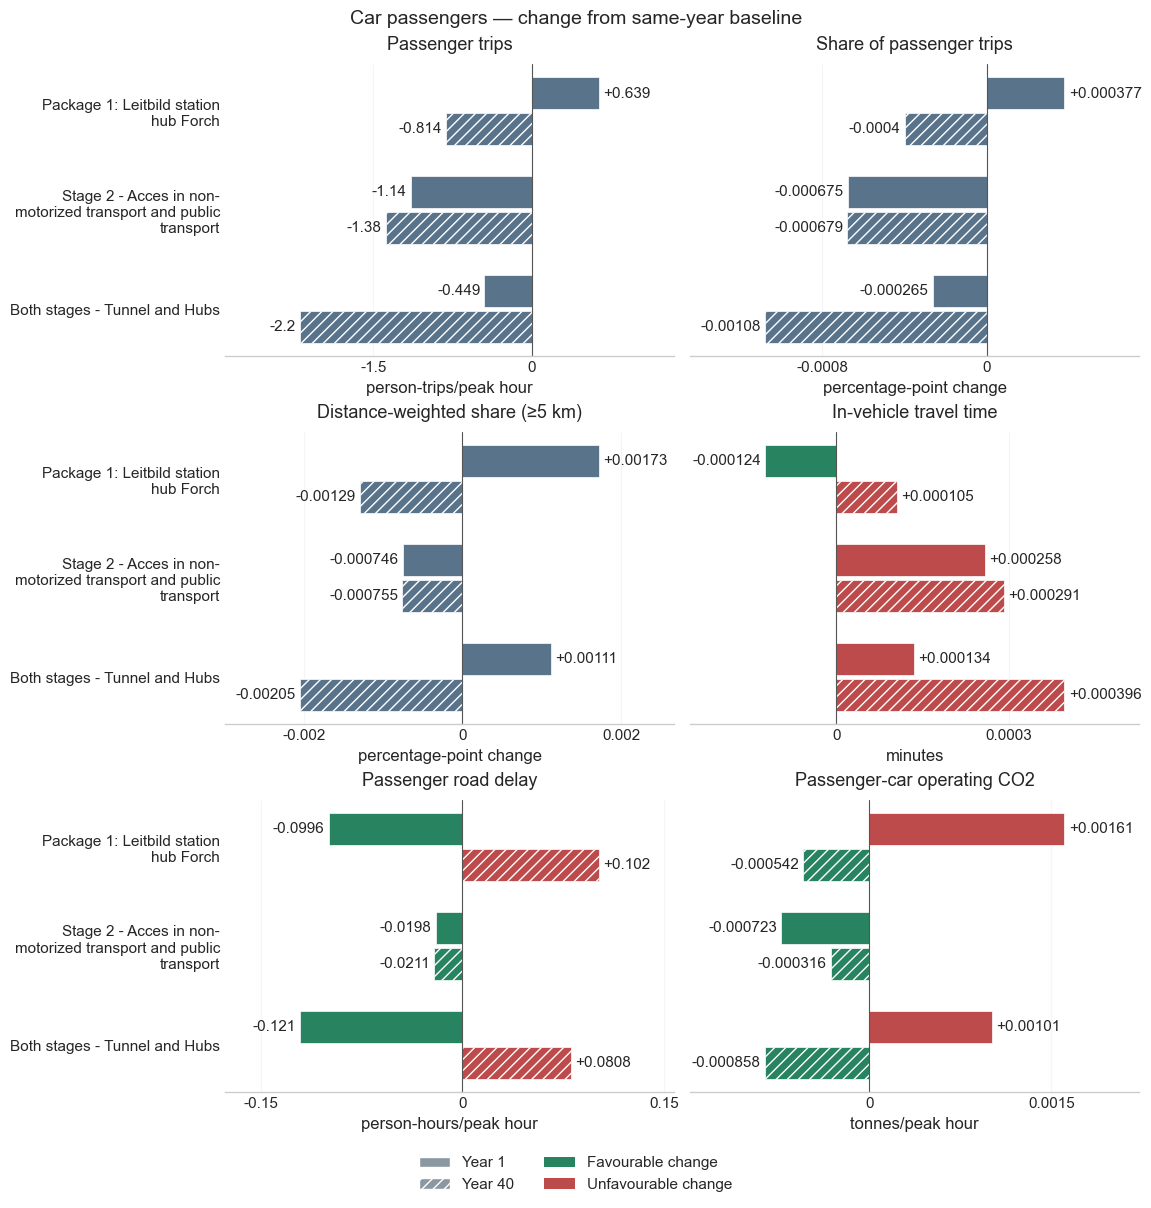

Public transport — absolute results


,Year 1 Trips,Year 40 Trips,Year 1 Trip Share,Year 40 Trip Share,Year 1 PKM Share (≥5 km),Year 40 PKM Share (≥5 km),Year 1 TT,Year 40 TT
Stage,,,,,,,,
Stage 0 – Baseline Network,"39,966 trips","50,498 trips",23.56%,24.81%,35.34%,37.95%,12.60 min,12.59 min
Package 1: Leitbild station hub Forch,"39,965 trips","50,499 trips",23.56%,24.81%,35.34%,37.95%,12.60 min,12.59 min
Stage 2 - Acces in non-motorized transport and public transport,"39,966 trips","50,499 trips",23.56%,24.81%,35.34%,37.95%,12.60 min,12.59 min
Both stages - Tunnel and Hubs,"39,966 trips","50,499 trips",23.56%,24.81%,35.34%,37.95%,12.60 min,12.59 min


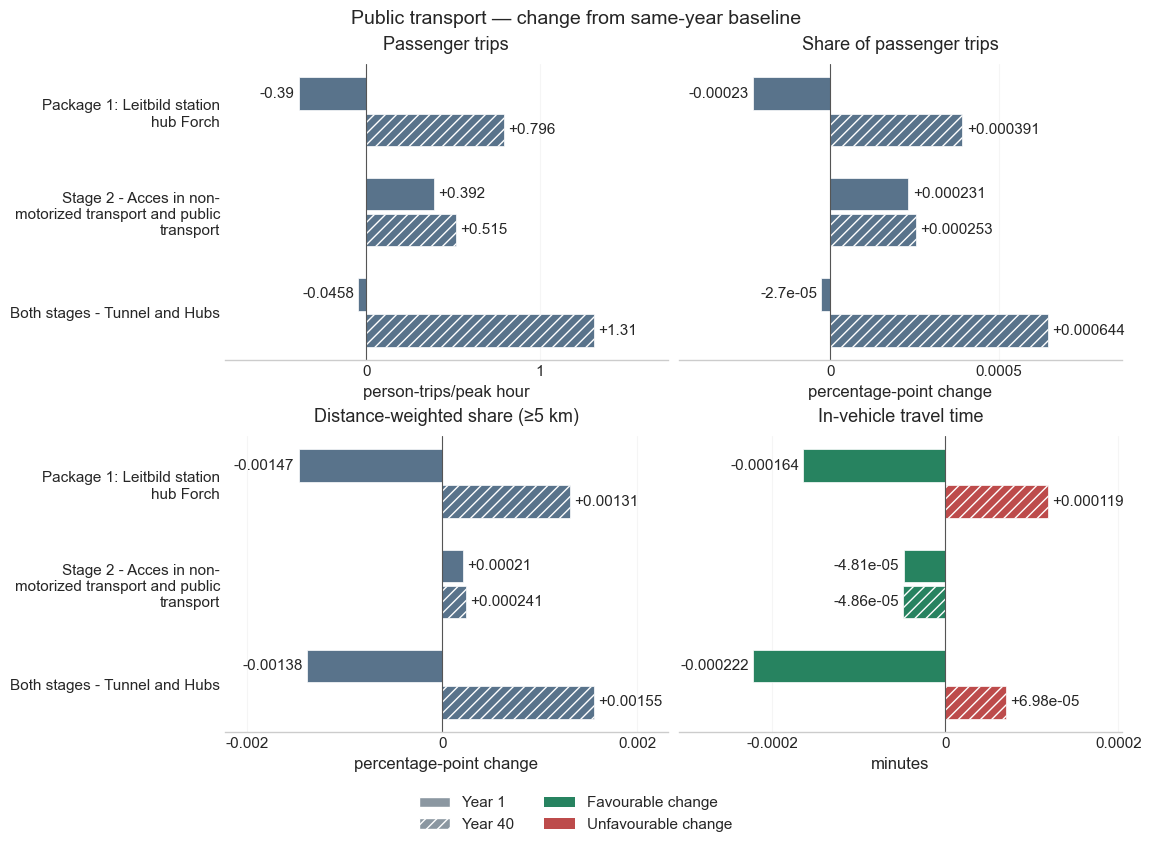

Active mobility — absolute results


,Year 1 Bike Trips,Year 40 Bike Trips,Year 1 Bike Trip Share,Year 1 Bike PKM Share,Year 1 Walk Trips,Year 40 Walk Trips,Year 1 Walk Trip Share,Year 1 Walk PKM Share
Stage,,,,,,,,
Stage 0 – Baseline Network,"26,356 trips","34,237 trips",15.54%,7.84%,"54,434 trips","64,469 trips",32.09%,1.87%
Package 1: Leitbild station hub Forch,"26,356 trips","34,237 trips",15.54%,7.84%,"54,434 trips","64,469 trips",32.09%,1.87%
Stage 2 - Acces in non-motorized transport and public transport,"26,357 trips","34,239 trips",15.54%,7.84%,"54,434 trips","64,469 trips",32.09%,1.87%
Both stages - Tunnel and Hubs,"26,357 trips","34,239 trips",15.54%,7.84%,"54,434 trips","64,469 trips",32.09%,1.87%


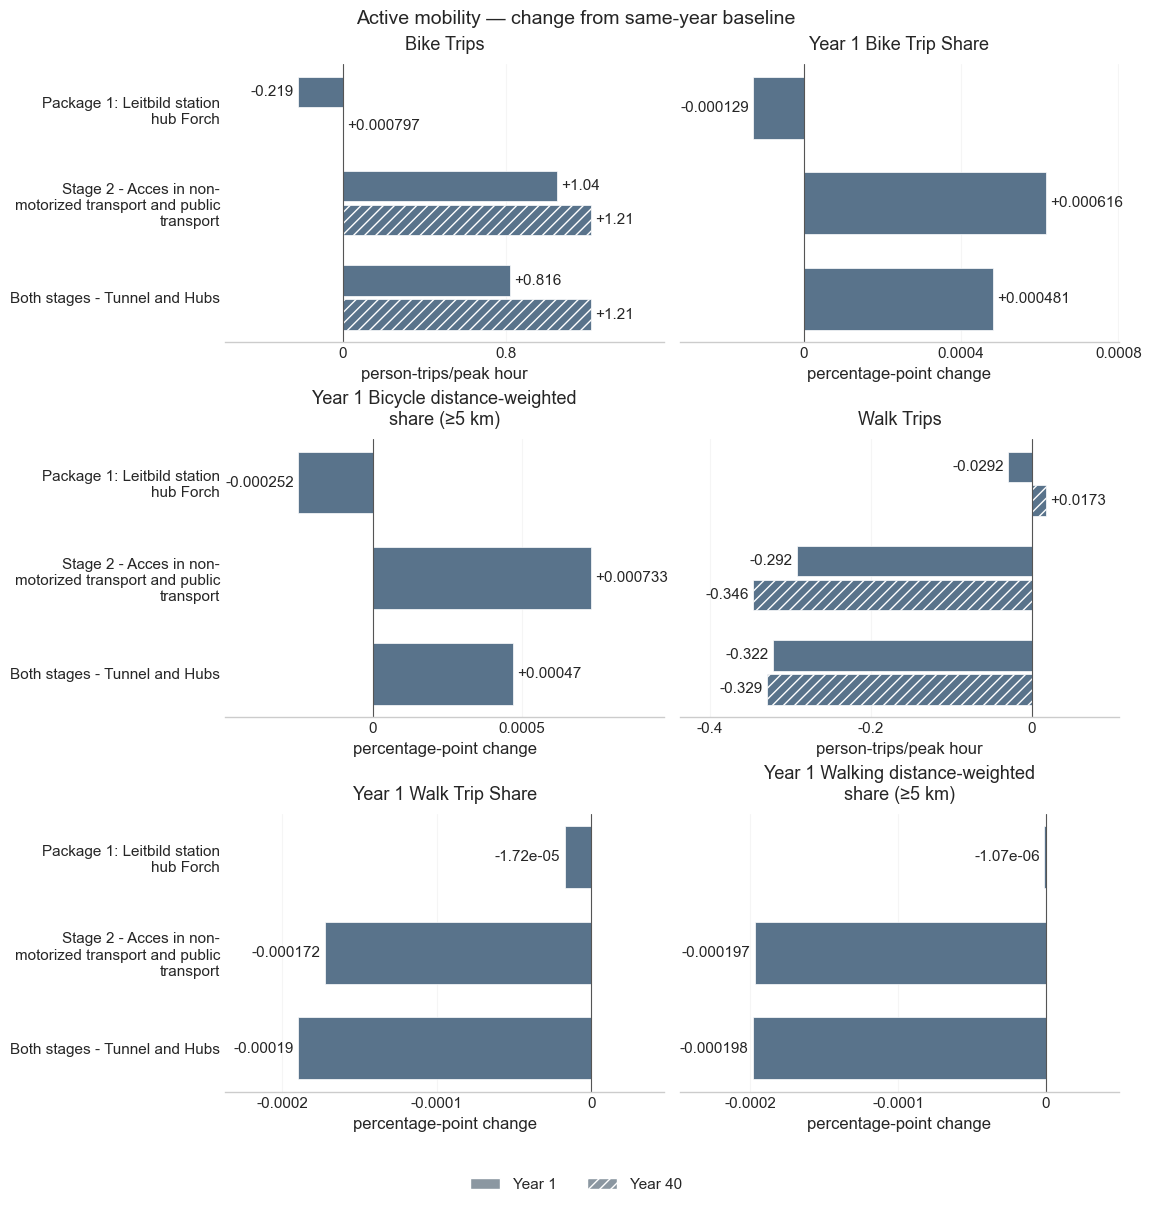

Overall system — absolute results


,Year 1 Total Demand,Year 40 Total Demand,Year 1 System Avg TT,Year 40 System Avg TT,Year 1 Peak Delay,Year 40 Peak Delay,Year 1 Peak CO2,Year 40 Peak CO2
Stage,,,,,,,,
Stage 0 – Baseline Network,"169,621 trips","203,545 trips",14.43 min,14.51 min,"4,290 h","5,209 h",56.6 t,22.5 t
Package 1: Leitbild station hub Forch,"169,621 trips","203,545 trips",14.43 min,14.51 min,"4,290 h","5,210 h",56.6 t,22.5 t
Stage 2 - Acces in non-motorized transport and public transport,"169,621 trips","203,545 trips",14.43 min,14.51 min,"4,290 h","5,209 h",56.6 t,22.5 t
Both stages - Tunnel and Hubs,"169,621 trips","203,545 trips",14.43 min,14.51 min,"4,290 h","5,210 h",56.6 t,22.5 t


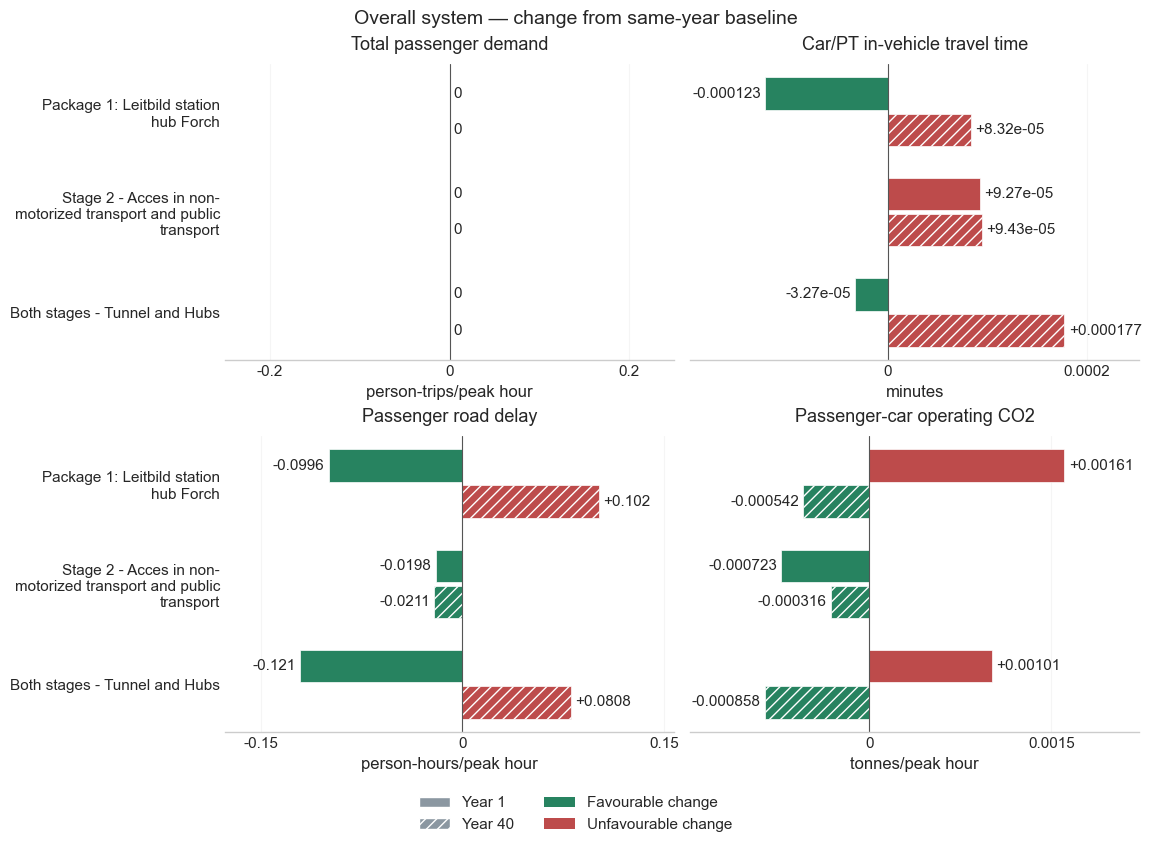

Section and PT components — absolute results


,Year 1 Section reference time,Year 1 Section modeled passengers,Year 1 Section supplementary passengers,Year 1 Section combined passengers,Year 1 Section comfort capacity,Year 1 Section load/capacity,Year 1 Section crowding multiplier,Year 1 Section crowding penalty,Year 1 PT waiting,Year 1 PT access,Year 1 PT egress,Year 1 PT transfer walking,Year 40 Section reference time,Year 40 Section modeled passengers,Year 40 Section supplementary passengers,Year 40 Section combined passengers,Year 40 Section comfort capacity,Year 40 Section load/capacity,Year 40 Section crowding multiplier,Year 40 Section crowding penalty,Year 40 PT waiting,Year 40 PT access,Year 40 PT egress,Year 40 PT transfer walking
Stage 0 – Baseline Network,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.87 minutes/baseline PT trip,4.92 minutes/baseline PT trip,4.70 minutes/baseline PT trip,1.07 minutes/baseline PT trip,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.90 minutes/baseline PT trip,4.86 minutes/baseline PT trip,4.64 minutes/baseline PT trip,1.07 minutes/baseline PT trip
Package 1: Leitbild station hub Forch,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.87 minutes/baseline PT trip,4.92 minutes/baseline PT trip,4.70 minutes/baseline PT trip,1.07 minutes/baseline PT trip,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.90 minutes/baseline PT trip,4.86 minutes/baseline PT trip,4.64 minutes/baseline PT trip,1.07 minutes/baseline PT trip
Stage 2 - Acces in non-motorized transport and public transport,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.87 minutes/baseline PT trip,4.92 minutes/baseline PT trip,4.70 minutes/baseline PT trip,1.07 minutes/baseline PT trip,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.90 minutes/baseline PT trip,4.86 minutes/baseline PT trip,4.64 minutes/baseline PT trip,1.07 minutes/baseline PT trip
Both stages - Tunnel and Hubs,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.87 minutes/baseline PT trip,4.92 minutes/baseline PT trip,4.70 minutes/baseline PT trip,1.07 minutes/baseline PT trip,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.90 minutes/baseline PT trip,4.86 minutes/baseline PT trip,4.64 minutes/baseline PT trip,1.07 minutes/baseline PT trip


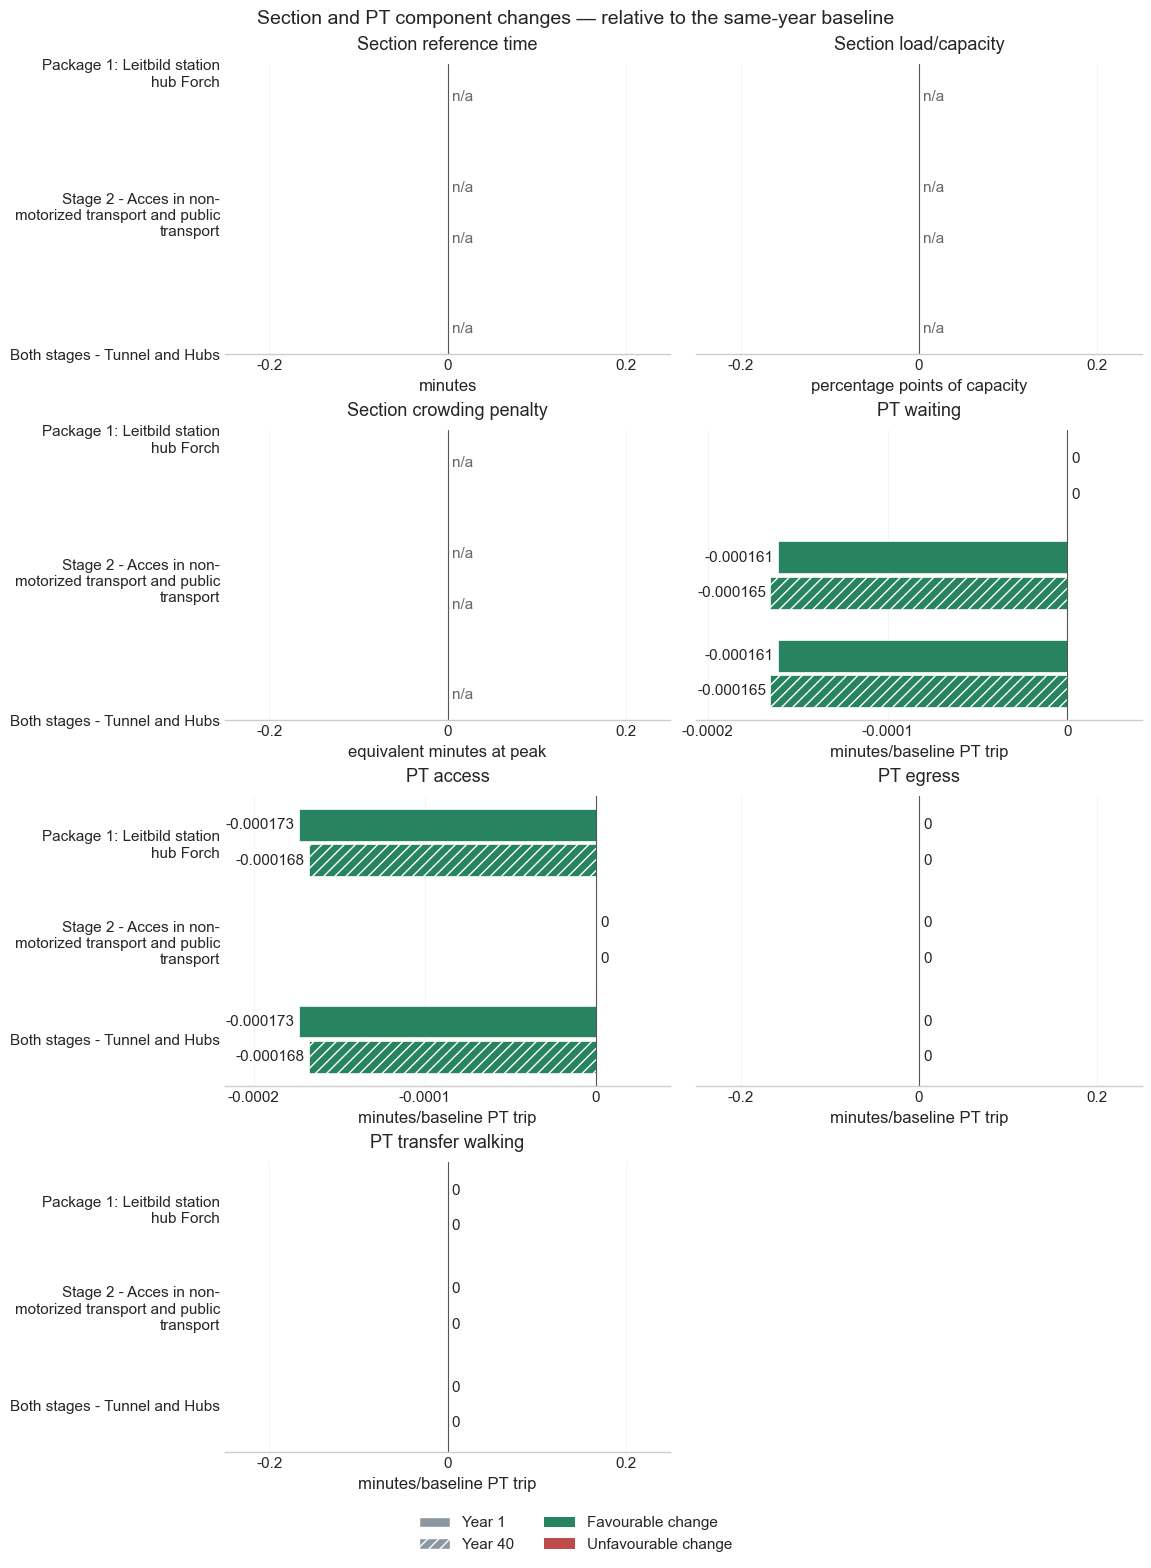

In [18]:
from additional import transport_display as td

# Formats for the absolute result tables.
_CAR_FORMAT = {
    "Year 1 Trips": "{:,.0f} trips", "Year 40 Trips": "{:,.0f} trips",
    "Year 1 Trip Share": "{:.2%}", "Year 40 Trip Share": "{:.2%}",
    "Year 1 PKM Share (>5km)": "{:.2%}", "Year 40 PKM Share (>5km)": "{:.2%}",
    "Year 1 TT": "{:.2f} min", "Year 40 TT": "{:.2f} min",
    "Year 1 Delay": "{:,.0f} h", "Year 40 Delay": "{:,.0f} h",
    "Year 1 CO2": "{:,.1f} t", "Year 40 CO2": "{:,.1f} t",
}
_PT_FORMAT = {
    "Year 1 Trips": "{:,.0f} trips", "Year 40 Trips": "{:,.0f} trips",
    "Year 1 Trip Share": "{:.2%}", "Year 40 Trip Share": "{:.2%}",
    "Year 1 PKM Share (>5km)": "{:.2%}", "Year 40 PKM Share (>5km)": "{:.2%}",
    "Year 1 TT": "{:.2f} min", "Year 40 TT": "{:.2f} min",
}
_ACTIVE_FORMAT = {
    "Year 1 Bike Trips": "{:,.0f} trips", "Year 40 Bike Trips": "{:,.0f} trips",
    "Year 1 Bike Trip Share": "{:.2%}", "Year 1 Bike PKM Share": "{:.2%}",
    "Year 1 Walk Trips": "{:,.0f} trips", "Year 40 Walk Trips": "{:,.0f} trips",
    "Year 1 Walk Trip Share": "{:.2%}", "Year 1 Walk PKM Share": "{:.2%}",
}
_SYSTEM_FORMAT = {
    "Year 1 Total Demand": "{:,.0f} trips", "Year 40 Total Demand": "{:,.0f} trips",
    "Year 1 System Avg TT": "{:.2f} min", "Year 40 System Avg TT": "{:.2f} min",
    "Year 1 Peak Delay": "{:,.0f} h", "Year 40 Peak Delay": "{:,.0f} h",
    "Year 1 Peak CO2": "{:,.1f} t", "Year 40 Peak CO2": "{:,.1f} t",
}


BASELINE_STAGE_NAME = ACTIVE_STAGE_SPECS[0]["name"]
active_display = df_active.rename(columns={
    c: f"Year 1 {c}" for c in ("Bike Trip Share", "Bike PKM Share", "Walk Trip Share", "Walk PKM Share")
})

def _stage_change_charts(frame, title, export_name):
    if not len(frame.columns):
        return
    panels, units, scales, directions = {}, {}, {}, {}
    for column in frame:
        metric = column.removeprefix("Year 1 ").removeprefix("Year 40 ")
        panels.setdefault(metric, []).append(column)
        if "Share" in metric:
            scales[column] = 100.0
            units[metric] = "percentage-point change"
        else:
            units[metric] = (
                "person-trips/peak hour" if "Trips" in metric or "Demand" in metric else
                "person-hours/peak hour" if "Delay" in metric else
                "tonnes/peak hour" if "CO2" in metric else "minutes"
            )
        directions[metric] = "low" if any(word in metric for word in ("TT", "Delay", "CO2")) else "context"
    metric_labels = {
        "Trips": "Passenger trips", "Trip Share": "Share of passenger trips",
        "PKM Share (>5km)": "Distance-weighted share (≥5 km)", "TT": "In-vehicle travel time",
        "Delay": "Passenger road delay", "CO2": "Passenger-car operating CO2",
        "System Avg TT": "Car/PT in-vehicle travel time", "Peak Delay": "Passenger road delay",
        "Peak CO2": "Passenger-car operating CO2", "Total Demand": "Total passenger demand",
        "Bike PKM Share": "Bicycle distance-weighted share (≥5 km)",
        "Walk PKM Share": "Walking distance-weighted share (≥5 km)",
    }
    labels = {key: (f"Year 1 {metric_labels.get(key, key)}" if all(c.startswith("Year 1 ") for c in cols) else metric_labels.get(key, key))
              for key, cols in panels.items()}
    fig = td.plot_baseline_changes(frame, BASELINE_STAGE_NAME, title=title + " — change from same-year baseline",
                             panels=panels, labels=labels, units=units, scales=scales, directions=directions,
                             ncols=CHANGE_PLOT_COLUMNS, fontsize=CHANGE_PLOT_FONT_SIZE)
    exports.save_outputs(export_name, figure=fig)
    plt.show()

for frame, title, fmt, export_name in [
    (df_car, "Car passengers", _CAR_FORMAT, "3_3_stage_car_changes"),
    (df_pt, "Public transport", _PT_FORMAT, "3_3_stage_pt_changes"),
    (active_display, "Active mobility", _ACTIVE_FORMAT, "3_3_stage_active_changes"),
    (df_system, "Overall system", _SYSTEM_FORMAT, "3_3_stage_system_changes"),
]:
    print(title + " — absolute results")
    selected = _display_indicators(frame, fmt)
    plot_columns = _plot_columns(frame, STAGE_PLOT_INDICATORS[title])
    _stage_change_charts(frame[plot_columns], title, export_name)

print("Section and PT components — absolute results")
project_formats = {
    f"{year} {key}": "{:,.2f} " + units
    for year in ("Year 1", "Year 40") for key, units in PROJECT_INDICATOR_UNITS.items()
}
selected_project = _display_indicators(STAGE_PROJECT_INDICATORS, project_formats, na_rep="n/a")
focus_columns = _plot_columns(STAGE_PROJECT_INDICATORS, PROJECT_PLOT_INDICATORS)
if focus_columns:
    fig = td.plot_baseline_changes(selected_project[focus_columns], BASELINE_STAGE_NAME,
        title="Section and PT component changes — relative to the same-year baseline",
        units={**PROJECT_INDICATOR_UNITS, "Section load/capacity": "percentage points of capacity"},
        scales={c: 100.0 for c in focus_columns if c.endswith("Section load/capacity")},
        directions=PROJECT_INDICATOR_DIRECTIONS,
        ncols=CHANGE_PLOT_COLUMNS, fontsize=CHANGE_PLOT_FONT_SIZE)
    exports.save_outputs("3_3_stage_project_changes", figure=fig)
    plt.show()


### 3.4 Preparing for uncertainty analysis (mandatory task)

Notebook 03 defines the uncertainty ranges and uses them to train the shared transport surrogate and prepare its response table. Save the intended interventions in the named packages in `code/stages.py` before continuing there; temporary changes in the interactive editor apply only within this notebook.



### 3.5 Optional section count and external-flow calibration (tutorial/supporting task)

Configure `SECTION` in `parameters.py` to estimate flow through a PT approach, along a cycling route or at a PT stop. Fixed inferred routes connect the modeled OD quantities to the selected location; this is not a separate PT or cycling assignment.

| Definition | Student inputs | Count |
|---|---|---|
| `pt_approach` | Station and a station indicating the approach direction | Journeys using service connections on that side of the station, including express services |
| `bike_route` | Two endpoint locations | Midpoint-link flow and unique users of any selected route link |
| `pt_stop` | Station name | Access, egress and represented walking transfers, reported separately |

The supplied MehrSpur coverage is loaded directly. Missing coverage or changed definitions/inputs are regenerated automatically from the shared routing inputs; preparation can take a few minutes. For another project, select a new `coverage_file` in `SECTION`, or use `None` for an automatic cache. PT connections do not contain physical railway alignments; a station approach can include other branches on the same side. Same-platform train changes are not fully identified. Cycling counts use fixed shortest paths and exclude cycling access to PT.

**Calibrate once against nominal Stage 0:**

1. Check that the observation matches the mode, location, directions, time period and count definition. A cycle counter measures flow at one link, not everyone using part of a route. Station entries, exits and transfers are different counts.
2. Run the next cell. It reuses the **Year-1 coupled Stage 0** result from Section 1.7 and reports the achieved assignment convergence. Set `OBSERVED_SECTION_TRIPS_DAILY = None` for a count without an observed target.
3. If justified, copy the reported nonnegative residual into `EXTERNAL_FLOW['additional_trips_daily']`. The report does not edit configuration. Retain that cohort across alternatives; only its configured growth applies.

**MehrSpur:** count the Winterthur approach facing Effretikon, in both directions. **120,000 passengers/day** is the assumed target; it is not evidence that an observed count uses precisely this definition. The residual can include missing external journeys, model error and measurement differences.

`EXTERNAL_FLOW` adds existing passengers after mode choice for appraisal; it does not load roads or generate municipal OD demand. A counting definition can be used without this supplementary cohort. Stop-specific hub benefits use `station` in the hub intervention: access and egress affect their respective users, while transfer-walking reductions apply only to represented physical walking at that stop.

**Other projects:** disable or omit both `SECTION` and `EXTERNAL_FLOW` if unused, and replace any section-dependent stage effects or adaptive triggers. To retain counts without supplementary passengers, set `EXTERNAL_FLOW['enabled'] = False`. See `python code/additional/section_flows.py --help` for preparation and calibration options.


In [ ]:
from additional import section_flows as sf

section_config = sf.section_config()
if section_config["active"]:
    AVAILABLE_SECTIONS = sf.available_sections()
    exports.save_outputs("3_5_available_sections", tables={"": AVAILABLE_SECTIONS})
    display(AVAILABLE_SECTIONS)
    OBSERVED_SECTION_TRIPS_DAILY = 120_000  # Comparable observed person-trips/day; None skips calibration.
    SECTION_CALIBRATION = sf.calibrate_section(
        ctx, assignment_y1.mode_result,
        observed_trips_daily=OBSERVED_SECTION_TRIPS_DAILY, params=p.NOMINAL_PARAMS,
    )
    diag = assignment_y1.diagnostics
    reference_ready = (
        diag.get("stopping_rule") == "road_relative_gap"
        and bool(diag.get("stopping_rule_met", False))
        and diag.get("road_gap_threshold", np.inf) <= 0.02
        and diag.get("od_threshold_veh_h", np.inf) == 0.0
    )
    external_config = sf.external_flow_config()
    configured = external_config["additional_trips_daily"] if external_config["enabled"] else 0.0
    SECTION_CALIBRATION_TABLE = pd.DataFrame({"Calibration": {
        "Modeled passengers/day": SECTION_CALIBRATION["modeled_trips_daily"],
        "Observed passengers/day": OBSERVED_SECTION_TRIPS_DAILY,
        "Suggested supplementary passengers/day": SECTION_CALIBRATION["additional_trips_daily"],
        "Configured supplementary passengers/day": configured,
        "Modeled + configured supplementary/day": SECTION_CALIBRATION["modeled_trips_daily"] + configured,
        "Suggested comfort capacity/peak hour": SECTION_CALIBRATION["suggested_comfort_capacity_peak"],
        "Road relative gap": diag.get("final_road_relative_gap_feasible_averaged_od"),
        "Iterations": diag.get("iterations"),
        "OD cutoff (vehicles/hour)": diag.get("od_threshold_veh_h"),
        "Termination": diag.get("termination_reason"),
        "Reference settings and convergence satisfied": reference_ready,
    }})
    exports.save_outputs("3_5_section_calibration", tables={"": SECTION_CALIBRATION_TABLE})
    display(SECTION_CALIBRATION_TABLE)
    if SECTION_CALIBRATION.get("component_counts_daily"):
        SECTION_COMPONENT_COUNTS = pd.Series(SECTION_CALIBRATION["component_counts_daily"], name="Journeys/day").to_frame()
        exports.save_outputs("3_5_section_calibration", tables={"component_counts": SECTION_COMPONENT_COUNTS})
        display(SECTION_COMPONENT_COUNTS)
    if not reference_ready:
        print("Illustrative count only: use zero OD cutoff and reach the 2% road-gap target before adopting a residual.")
    if SECTION_CALIBRATION["warning"]:
        print(SECTION_CALIBRATION["warning"])
else:
    print("Section counting and external flows are inactive for this project.")


# Part 4 — Deployment Plans

A **plan** specifies the initial infrastructure stage and any fixed or trigger-based rules for moving to later stages. A **pathway** is the resulting evolution of the system through time when that plan is evaluated under a scenario.

As a refresher, we reproduce the following distinctions in the terminology we use:

| Concept | Question | Example |
|---|---|---|
| Parameter | What numerical assumption controls a relationship? | Tunnel section travel-time saving = 4 minutes; both packages = 6 minutes |
| Stage | What transport intervention / package is in place? | Stations + tunnel: Brüttenertunnel, station upgrades and 15-minute service |
| Plan | When, and under which rules, are stages deployed? | Stage 1 in Year 1, Stage 2 in Year 25 |

Plan definitions live in [`code/adaptive_planning.py`](../code/adaptive_planning.py), stage definitions in [`code/stages.py`](../code/stages.py), and uncertain assumptions in [`code/parameters.py`](../code/parameters.py).

This notebook introduces three deterministic plans with no later transitions: a do-nothing baseline and two static plans, one partial and one full build.

| Plan | Stage from Year 1 | Later transition? |
|---|---|---|
| `baseline` | Stage 0 — do nothing | No |
| `static1` | Stage 1 — partial intervention | No |
| `static2` | Stages 1 + 2 — stations and tunnel (complete intervention) | No |

### 4.1 Static plan definition (mandatory task)

During the course, we use four plan types:

| Plan type | Deployment rule |
|---|---|
| **Baseline** | Keep Stage 0 for the complete horizon. |
| **Static** | Deploy one selected stage in Year 1 and retain it. |
| **Staged** | Deploy later stages in years predetermined at the outset, regardless of observed conditions. |
| **Adaptive** | Deploy later stages based on specific rules, i.e. only after predefined signposts cross their trigger thresholds, persistence requirements, and lead times. |

*Mandatory task*
>Define the three deterministic alternatives used here: **Baseline**, which retains Stage 0 throughout the simulation; **Static 1**, which deploys the partial Stage 1 intervention in Year 1 until the end of the simulation; and **Static 2**, which deploys both packages (Stages 1 + 2, the complete intervention) in Year 1 until the end of the simulation.

Notebook 02 compares `baseline`, `static1`, and `static2`. Predetermined (staged) and flexible/adaptive plans are examined in the following notebooks.
<br>
<br>
**Packages describe what is built; plans describe when.** `static1` opens the station package in Year 1. `static2` opens both station and tunnel packages in Year 1. 

---

Open [`code/adaptive_planning.py`](../code/adaptive_planning.py) and edit the student-facing `PLAN_DEFINITIONS` dictionary near the top:

1. Adapt `baseline`, `static1`, and `static2` as necessary for your project. Set `name` and `initial_packages`: `[]` for baseline, `['stations']` for Static 1, and `['stations', 'tunnel']` for Static 2. Keep `stations: None` and `tunnel: None` for these static plans, since no package is added later.
2. Leave `staged1`, `staged2`, and `flexible` unchanged for now. Their `stations` and `tunnel` entries schedule later openings, for example `{'type': 'fixed', 'opening_year': 9}` or `{'type': 'trigger', 'trigger': 'trigger1'}`. Trigger rules are configured in `DEFAULT_TRIGGERS`.
3. Set package construction costs, lifetimes and construction emissions in `PACKAGES` in `stages.py`. A general OPEX cost- `OPEX_RATE` and the cost of flexibility - `C_FLEX` are in `parameters.py`. The model derives costs and transport-state IDs from the named packages. An additional independently scheduled package requires extending the plan engine and transport states.
4. After saving plan or package changes, restart the kernel and Run All. `PLAN_SUBSET` below selects the static plans to display.

## 4.2 Visualizing plans and their system pathways (tutorial/supporting task)

The metro-style map compares the plans by showing the infrastructure-stage pathway that each plan produces over the 40-year horizon:

- read from left to right as time advances.
- horizontal lines show the active physical stage.
- a solid dot marks the initial Year-1 commitment.
- later dots or branches, introduced in Notebook 04, represent stage transitions.

The three plans shown here have no later transition: `baseline` remains at Stage 0, `static1` remains at Stage 1, and `static2` remains at Stages 1 + 2 (both packages).

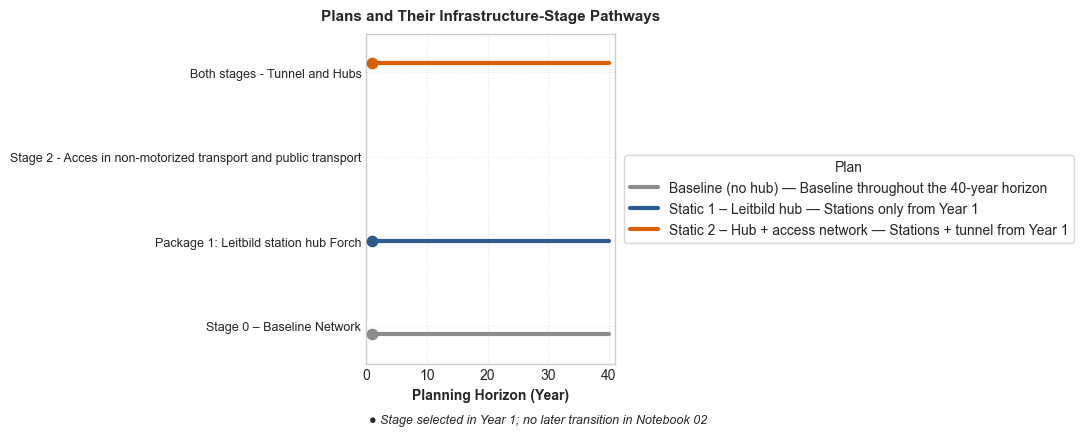

In [50]:
PLAN_SUBSET = ["baseline", "static1", "static2"]
PLANS = {name: adaptive_planning.PLANS[name] for name in PLAN_SUBSET}
PLAN_COLORS = ["#8c8c8c", "#2b5c8f", "#d95f02", "#2ca02c", "#7570b3"]


def draw_plan_metromap(
    plans,
    horizon=p.N_YEARS,
):
    fig, ax = plt.subplots(figsize=(11, 4.5))

    plan_offsets = np.linspace(-0.10, 0.10, max(len(plans), 2))

    for plan_idx, ((plan_name, plan), plan_offset) in enumerate(
        zip(plans.items(), plan_offsets)
    ):
        color = PLAN_COLORS[plan_idx % len(PLAN_COLORS)]
        display_name = plan.get("name", plan_name)

        if plan["to1"] is not None or plan["to2"] is not None:
            raise ValueError(f"{plan_name!r} is not a static plan")

        stage = plan["initial_stage"]
        ax.plot(
            [1, horizon],
            [stage + plan_offset, stage + plan_offset],
            color=color,
            linewidth=3,
            label=display_name,
        )
        ax.scatter(1, stage + plan_offset, color=color, s=55, zorder=5)

    stage_ticks = sorted(ACTIVE_STAGE_SPECS)
    ax.set_yticks(stage_ticks)
    ax.set_yticklabels([ACTIVE_STAGE_SPECS[s].get("name", f"Stage {s}") for s in stage_ticks], fontsize=9)

    ax.set_xlim(0, horizon + 1)
    ax.set_ylim(min(stage_ticks) - 0.45, max(stage_ticks) + 0.45)
    ax.set_xlabel("Planning Horizon (Year)", fontweight="bold")
    ax.set_title("Plans and Their Infrastructure-Stage Pathways", fontweight="bold", fontsize=11, pad=10)

    ax.grid(axis="x", linestyle=":", alpha=0.5)
    ax.grid(axis="y", linestyle=":", alpha=0.3)

    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        title="Plan",
        frameon=True,)
    ax.text(
        0.01,
        -0.18,
        "● Stage selected in Year 1; no later transition in Notebook 02",
        transform=ax.transAxes,
        fontsize=9,
        style="italic",)

    plt.tight_layout()

    exports.save_outputs("4_2_plan_metromap", figure=fig)

    return fig, ax

draw_plan_metromap(PLANS)
plt.show()


## 4.3 Compare plan end states (mandatory task)

Compare the Year-40 system state for the do-nothing `baseline`, the stations-only `static1`, and the combined `static2` plans. Each plan reuses the matching transport state from Section 3.3, using the nominal Year-40 values from General parameters, including `PASSENGER_DEMAND_GROWTH_Y40`, `PT_ASC_SHIFT_Y40`, `EBIKE_SHARE_Y40` and `ROAD_FREIGHT_GROWTH_Y40`. No uncertainty draws or annual transport runs are needed.

The cost column is undiscounted investment plus 40 years of operating costs for these static plans. Annual CO2 is from car and rail operation; total package construction emissions are shown separately. Uncertainty trajectories and discounted appraisal follow in later notebooks.

Modal shares use common-distance weighting for journeys of at least 5 km. The charts show each plan minus the Year-40 baseline in physical units; modal-share changes are percentage points. The section and PT component indicators use the definitions in Section 3.3. Absolute tables remain available, and `SHOW_ABSOLUTE_PARALLEL_COORDINATES` enables the optional absolute overview. The indicator-family selection in Section 1.7 also applies here; `PLAN_PLOT_INDICATORS` and `PROJECT_PLOT_INDICATORS` select individual subplots. Transport and operating indicators describe Year 40; construction emissions and infrastructure cost are totals over the stated period. Each subplot has its own axis range. Modal-share shifts are contextual, not welfare scores. Rerun only the display cell to redraw completed results.


In [51]:
# Year-40 plan results from the completed stage snapshots.

NOMINAL_PATHS = uc.nominal_paths()
YEAR40_PARAMS = uc.year_parameters(NOMINAL_PATHS, p.N_YEARS - 1)
PLAN_RESULTS = {}
PLAN_INFRASTRUCTURE_COSTS = {}
PLAN_CONSTRUCTION_EMISSIONS = {}
PLAN_PROJECT_ROWS = {}

for key, plan in PLANS.items():
    if plan["to1"] is not None or plan["to2"] is not None:
        raise ValueError(f"{key!r} is not a static plan")
    stage = int(plan["initial_stage"])
    stations_active, tunnel_active = stages_module.stage_components(stage)
    investment = (
        stations_active * plan.get("inv_stage1", 0.0)
        + tunnel_active * plan.get("inv_stage2", 0.0)
    )
    annual_opex = (
        stations_active * plan.get("op_stage1", 0.0)
        + tunnel_active * plan.get("op_stage2", 0.0)
    )
    print(f"Using Year {p.N_YEARS} state: {plan['name']}...")
    snapshot = tmi.stage_year_snapshot(ctx, stage_results[stage],
        stage_spec=ACTIVE_STAGE_SPECS[stage],
        corridor_context=globals().get("ROAD_STAGE_CORRIDORS", {}).get(stage, MEHRSPUR),
        year_idx=p.N_YEARS - 1,
        g_cum=float(NOMINAL_PATHS["PASSENGER_DEMAND_GROWTH"][-1]), params=YEAR40_PARAMS,
        assignment_settings=ASSIGNMENT_OPTIONS, snapshots=YEAR_SNAPSHOTS)
    PLAN_PROJECT_ROWS[plan["name"]] = _project_indicator_row(snapshot)
    PLAN_RESULTS[key] = m.simulate_year(
        stage_metrics[stage], stage=stage, year_idx=p.N_YEARS - 1,
        g_cum=float(NOMINAL_PATHS["PASSENGER_DEMAND_GROWTH"][-1]), params=YEAR40_PARAMS,
        context=ctx, mode_result=stage_results[stage],
        corridor_municipalities=corridor_municipalities,
        corridor_context=globals().get("ROAD_STAGE_CORRIDORS", {}).get(stage, MEHRSPUR),
        inv_cost=0.0, op_cost=annual_opex,
        transport_state=snapshot["transport_state"],
    )
    PLAN_INFRASTRUCTURE_COSTS[key] = investment + p.N_YEARS * annual_opex
    PLAN_CONSTRUCTION_EMISSIONS[key] = sum(
        stages_module.construction_emissions_tonnes(package)
        for package, active in ((1, stations_active), (2, tunnel_active)) if active
    )

# 1. One row per plan, with every indicator we track ----------------------
DIRECTION = {                       # preferred direction for each axis
    "Stage (Y40)":          "-",    # contextual information, not a quality metric
    "Car %":                "-",
    "PT %":                 "-",
    "Bicycle %":            "-",
    "Walk %":               "-",
    "Car/PT in-vehicle time (min)":    "low",
    "Congestion (k person-h/yr)": "low",
    "Operating CO2 (t/yr)":           "low",
    "Annual trip equivalents (thousands)": "-",   # mode-specific conversion of fixed peak OD demand
    "Construction CO2 (t total)": "low",
    "40-yr cost (bn CHF)":  "low",
}

rows = {}
for key, y in PLAN_RESULTS.items():
    rows[PLANS[key]["name"]] = {
        "Stage (Y40)":          y["stage"],
        "Car %":                y["car_share"]  * 100,
        "PT %":                 y["pt_share"]   * 100,
        "Bicycle %":            y["bike_share"] * 100,
        "Walk %":               y["walk_share"] * 100,
        "Car/PT in-vehicle time (min)":    y["avg_tt_min"],
        "Congestion (k person-h/yr)": y["congestion_delay_hours"] / 1e3,
        "Operating CO2 (t/yr)":           y["co2_tonnes"],
        "Annual trip equivalents (thousands)": y["total_demand"] / 1e3,
        "Construction CO2 (t total)": PLAN_CONSTRUCTION_EMISSIONS[key],
        "40-yr cost (bn CHF)":  PLAN_INFRASTRUCTURE_COSTS[key] / 1e9,
    }
PLAN_OUTCOMES = pd.DataFrame(rows).T[list(DIRECTION)]
exports.save_outputs("4_3_plan_outcomes", tables={"": PLAN_OUTCOMES})

# Modal shares are already percentages; their differences are percentage points.
PLAN_OUTCOME_CHANGES = _baseline_change_table(PLAN_OUTCOMES, PLANS["baseline"]["name"])
PLAN_OUTCOME_CHANGES = PLAN_OUTCOME_CHANGES.rename(columns={
    f"{mode} % change (original units)": f"{mode} share change (percentage points)"
    for mode in ("Car", "PT", "Bicycle", "Walk")
})
exports.save_outputs("4_3_plan_outcomes_changes", tables={"": PLAN_OUTCOME_CHANGES})

PLAN_PROJECT_INDICATORS = pd.DataFrame.from_dict(PLAN_PROJECT_ROWS, orient="index")

exports.save_outputs("4_3_plan_project_indicators", tables={"": PLAN_PROJECT_INDICATORS})

exports.save_outputs("4_3_plan_project_changes", tables={"": _baseline_change_table(
    PLAN_PROJECT_INDICATORS, PLANS["baseline"]["name"],
    percentage_point_columns=["Section load/capacity"],
)})


Using Year 40 state: Baseline (no hub) — Baseline throughout the 40-year horizon...
Using Year 40 state: Static 1 – Leitbild hub — Stations only from Year 1...
Using Year 40 state: Static 2 – Hub + access network — Stations + tunnel from Year 1...


{'table:': PosixPath('/Users/samuelpereira/Desktop/ETH/Infrastructure planning/IP-HS26-MehrSpur-CaseStudy/deliverables/phase2/s1/results/nb02_exports/4_3_plan_project_changes.csv')}

Year-40 plans — absolute results


,Stage (Y40),Car %,PT %,Bicycle %,Walk %,Car/PT in-vehicle time (min),Congestion (k person-h/yr),Operating CO2 (t/yr),Annual trip equivalents (thousands),Construction CO2 (t total),40-yr cost (bn CHF)
Baseline — Baseline throughout the 40-year horizon,0,50.4,38.0,9.8,1.8,14.51,"6,251.3","66,778","512,961.0",0,0.00
Static 1 — Stations only from Year 1,1,50.4,38.0,9.8,1.8,14.51,"6,251.5","66,776","512,961.2",0,0.02
Static 2 — Stations + tunnel from Year 1,3,50.4,38.0,9.8,1.8,14.51,"6,251.4","66,775","512,960.6",0,0.03


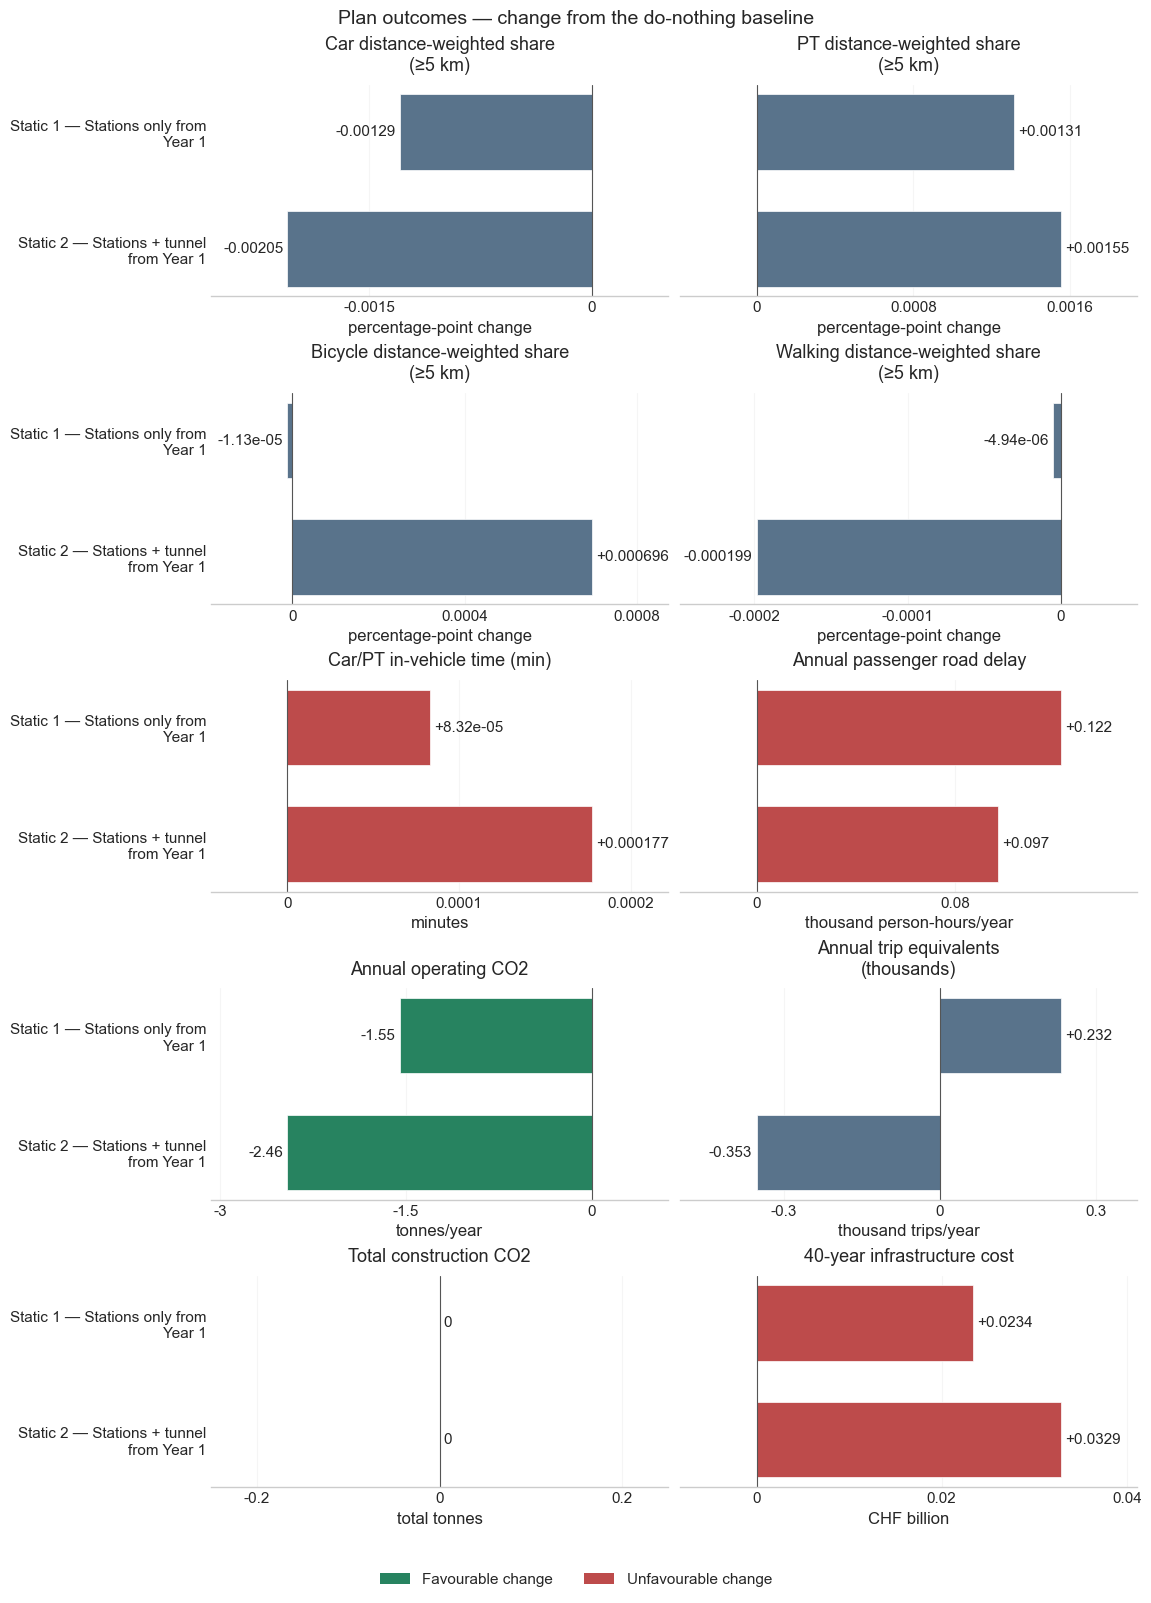

Year-40 section and PT components — absolute results


,Section reference time,Section modeled passengers,Section supplementary passengers,Section combined passengers,Section comfort capacity,Section load/capacity,Section crowding multiplier,Section crowding penalty,PT waiting,PT access,PT egress,PT transfer walking
Baseline — Baseline throughout the 40-year horizon,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.90 minutes/baseline PT trip,4.86 minutes/baseline PT trip,4.64 minutes/baseline PT trip,1.07 minutes/baseline PT trip
Static 1 — Stations only from Year 1,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.90 minutes/baseline PT trip,4.86 minutes/baseline PT trip,4.64 minutes/baseline PT trip,1.07 minutes/baseline PT trip
Static 2 — Stations + tunnel from Year 1,n/a,n/a,n/a,n/a,n/a,n/a,n/a,n/a,3.90 minutes/baseline PT trip,4.86 minutes/baseline PT trip,4.64 minutes/baseline PT trip,1.07 minutes/baseline PT trip


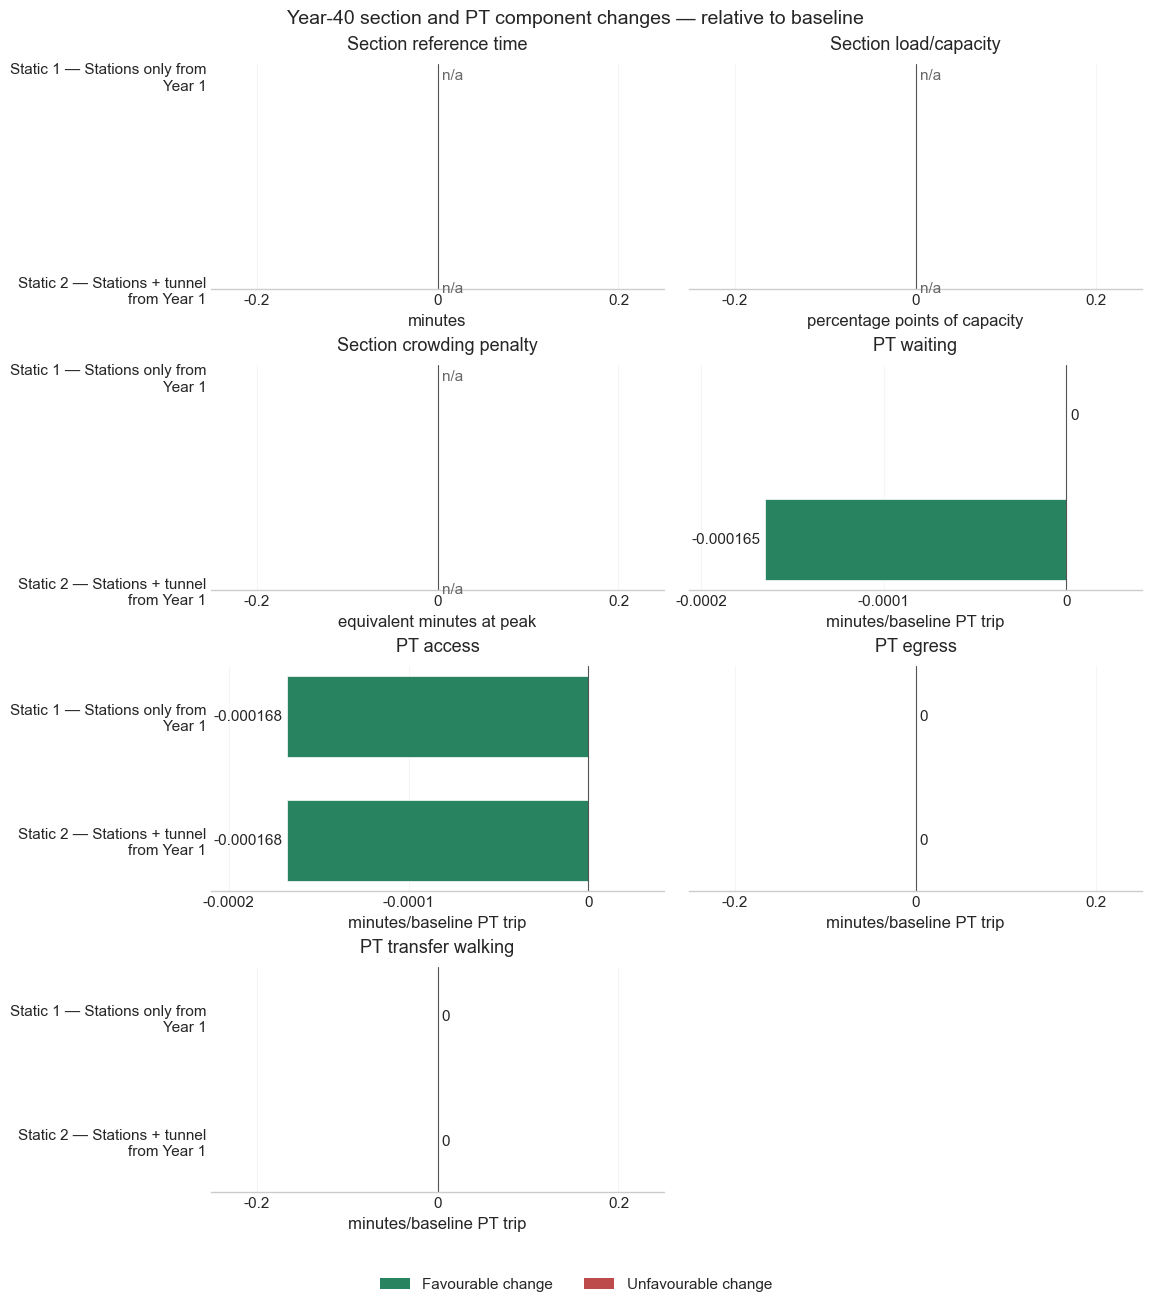

In [21]:
from additional import transport_display as td

SHOW_ABSOLUTE_PARALLEL_COORDINATES = False  # Optional overview of the absolute values.
BASELINE_PLAN_NAME = PLANS["baseline"]["name"]
PLOT_DIRECTIONS = {key: "context" if key in {"Car %", "PT %", "Bicycle %", "Walk %"}
                   or value not in {"low", "high"} else value for key, value in DIRECTION.items()}

print("Year-40 plans — absolute results")
selected_outcomes = _display_indicators(PLAN_OUTCOMES, {
    "Stage (Y40)": "{:.0f}", "Car %": "{:.1f}", "PT %": "{:.1f}", "Bicycle %": "{:.1f}",
    "Walk %": "{:.1f}", "Car/PT in-vehicle time (min)": "{:.2f}", "Congestion (k person-h/yr)": "{:,.1f}",
    "Construction CO2 (t total)": "{:,.0f}",
    "Operating CO2 (t/yr)": "{:,.0f}", "Annual trip equivalents (thousands)": "{:,.1f}", "40-yr cost (bn CHF)": "{:.2f}",
})

if SHOW_ABSOLUTE_PARALLEL_COORDINATES and len(selected_outcomes.columns):
    # 2. Normalize each axis to 0..1 and reverse axes where lower is better, so
    #    a higher line is preferable on benefit axes; context axes are not scores.
    cols   = list(selected_outcomes.columns)
    X      = selected_outcomes.to_numpy(dtype=float)
    lo, hi = X.min(0), X.max(0)
    span   = np.where(hi > lo, hi - lo, 1.0)
    Z      = (X - lo) / span
    Z[:, hi <= lo] = 0.5                       # identical values are placed at the center
    for j, c in enumerate(cols):
        if PLOT_DIRECTIONS[c] == "low":
            Z[:, j] = 1.0 - Z[:, j]

    # 3. Plot ---------------------------------------------------------------------
    colors = globals().get("PLAN_COLORS", ["#8c8c8c", "#2b5c8f", "#d95f02", "#2ca02c", "#7570b3"])
    xs = np.arange(len(cols))

    def _fmt(v):
        if abs(v) >= 1000: return f"{v:,.0f}"
        if abs(v) >= 10:   return f"{v:.2f}"
        return f"{v:.2f}"

    fig, ax = plt.subplots(figsize=(max(8.0, 1.4 * len(cols)), 6.0))
    for j in xs:
        ax.axvline(j, color="0.85", lw=1, zorder=1)
    for i, plan in enumerate(PLAN_OUTCOMES.index):
        ax.plot(xs, Z[i], "-o", lw=2.4, ms=6, color=colors[i % len(colors)], label=plan, zorder=3)

    for j, c in enumerate(cols):
        top, bot = (lo[j], hi[j]) if PLOT_DIRECTIONS[c] == "low" else (hi[j], lo[j])
        ax.text(j,  1.04, _fmt(top), ha="center", va="bottom", fontsize=11, color="0.4")
        ax.text(j, -0.04, _fmt(bot), ha="center", va="top",    fontsize=11, color="0.4")

    axis_labels = {
        "Stage (Y40)": "Stage\nYear 40",
        "Car %": "Car\n(%)", "PT %": "Public transport\n(%)",
        "Bicycle %": "Bicycle\n(%)", "Walk %": "Walking\n(%)",
        "Car/PT in-vehicle time (min)": "Car/PT in-vehicle time\n(minutes)",
        "Congestion (k person-h/yr)": "Road delay\n(thousand person-h/year)",
        "Operating CO2 (t/yr)": "Operating CO2\n(tonnes/year)",
        "Annual trip equivalents (thousands)": "Annual trip equivalents\n(thousands)",
        "Construction CO2 (t total)": "Construction CO2\n(total tonnes)",
        "40-yr cost (bn CHF)": "40-year infrastructure cost\n(CHF billion)",
    }
    ax.set_xticks(xs)
    ax.set_xticklabels([axis_labels[c] for c in cols], fontsize=11)
    ax.set_yticks([])
    ax.set_ylim(-0.16, 1.16)
    ax.set_xlim(-0.5, len(cols) - 0.5)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.set_title("Plan outcomes (each axis has its own range; context axes are not scores)",
                 fontsize=14, fontweight="bold", pad=24)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.30),
              ncol=len(PLAN_OUTCOMES), frameon=False, fontsize=10)

    plt.tight_layout()
    exports.save_outputs("4_3_plan_outcomes_parallel_coordinates", figure=fig)
    plt.show()

# Changes in physical units; the configuration ID stays in the absolute table.
relative_columns = _plot_columns(PLAN_OUTCOMES, PLAN_PLOT_INDICATORS)
if relative_columns:
    plan_units = {
        "Car %": "percentage-point change", "PT %": "percentage-point change",
        "Bicycle %": "percentage-point change", "Walk %": "percentage-point change",
        "Car/PT in-vehicle time (min)": "minutes", "Congestion (k person-h/yr)": "thousand person-hours/year",
        "Operating CO2 (t/yr)": "tonnes/year", "Annual trip equivalents (thousands)": "thousand trips/year",
        "Construction CO2 (t total)": "total tonnes", "40-yr cost (bn CHF)": "CHF billion",
    }
    fig = td.plot_baseline_changes(selected_outcomes[relative_columns], BASELINE_PLAN_NAME,
        title="Plan outcomes — change from the do-nothing baseline", units=plan_units,
        labels={"Car %": "Car distance-weighted share\n(≥5 km)",
                "PT %": "PT distance-weighted share\n(≥5 km)",
                "Bicycle %": "Bicycle distance-weighted share\n(≥5 km)",
                "Walk %": "Walking distance-weighted share\n(≥5 km)",
                "Congestion (k person-h/yr)": "Annual passenger road delay",
                "Operating CO2 (t/yr)": "Annual operating CO2",
                "Construction CO2 (t total)": "Total construction CO2",
                "40-yr cost (bn CHF)": "40-year infrastructure cost"},
        ncols=CHANGE_PLOT_COLUMNS, fontsize=CHANGE_PLOT_FONT_SIZE,
        directions=PLOT_DIRECTIONS)
    exports.save_outputs("4_3_plan_outcomes_changes", figure=fig)
    plt.show()

print("Year-40 section and PT components — absolute results")
selected_project = _display_indicators(PLAN_PROJECT_INDICATORS,
    {key: "{:,.2f} " + units for key, units in PROJECT_INDICATOR_UNITS.items()}, na_rep="n/a")
focus_columns = _plot_columns(PLAN_PROJECT_INDICATORS, PROJECT_PLOT_INDICATORS)
if focus_columns:
    fig = td.plot_baseline_changes(selected_project[focus_columns], BASELINE_PLAN_NAME,
        title="Year-40 section and PT component changes — relative to baseline",
        units={**PROJECT_INDICATOR_UNITS, "Section load/capacity": "percentage points of capacity"},
        scales={c: 100.0 for c in focus_columns if c == "Section load/capacity"},
        directions=PROJECT_INDICATOR_DIRECTIONS,
        ncols=CHANGE_PLOT_COLUMNS, fontsize=CHANGE_PLOT_FONT_SIZE)
    exports.save_outputs("4_3_plan_project_changes", figure=fig)
    plt.show()


In [22]:
# Total runtime notebook02
print(f"__NOTEBOOK_RUNTIME_SECONDS__={time.perf_counter() - _NB_START:.3f}")
print(f"__NOTEBOOK_RUNTIME_MINUTES__={(time.perf_counter() - _NB_START) / 60:.3f}")

__NOTEBOOK_RUNTIME_SECONDS__=1357.901
__NOTEBOOK_RUNTIME_MINUTES__=22.632
